<a href="https://colab.research.google.com/github/bogdanparvu18/msc-graduate-project/blob/main/notebooks/phase2/phase2_08_visual_input_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2 - Sector 8 — Visual input preparation

Consumes verified S7 outputs, preserves originals by reference, and generates only new visual products. All code is included here; no upstream notebooks are imported or executed.


Published tables verified when this notebook was built: **66,127 files**, **47,239 annotations**, **110,666 temporal references**. S7 retains `final_split = null`, `split_assignment_status = pending`, and `training_ready = false`; S8 preserves the same semantics. `image_usable_for_modelling = false` does not exclude preparation of a technically usable image.


## 1. Products and variants

| Product | What it generates | When it is available |
|---|---|---|
| `full_frame` | Reference to the original, without a new copy | Technically usable S7 source |
| `roi_crop` | Cropped JPEG with a configurable margin | Valid bbox within the image dimensions |
| `bbox_overlay` | Full frame with all valid bounding boxes drawn | At least one valid bbox |
| `evidence_panel` | Full frame + crop in one JPEG | Valid bbox |
| `temporal_collage` | Neighboring frames in order, with the target and offsets | S7 window containing a target and a neighbor |
| `progression_panel` | Verified anchors along the segment | At least two distinct verified frames |
| `quality_panel` | Target and nearby frames showing variation in QC metrics | At least two distinct frames from the same video |
| `comparison_panel` | Finding and an explicitly labeled normal reference | Verified normal reference in the same video |
| `combined_panel` | Frame, available crop/overlay, and temporal context | At least two available views |

Panels use neutral A/B/C markers or frame/time identifiers. They do not print diagnoses, classes, QC values, or answers. Normal/abnormal positions are permuted deterministically. Bbox-derived overlays/crops are marked `annotation_assisted`.

Here, “progression” means comparing **the appearance of observed anchors**, without claims about clinical progression, onset, end, or continuous visibility. QC metrics are uncalibrated technical indicators; a QC panel does not automatically yield a correct clinical answer. An unlabeled frame is not normal by default.

### Common manifest
`visual_manifest` indexes originals and products. `visual_source_manifest` preserves each product's links to all its sources; `source_evidence_manifest` keeps labels/verification records/QC separate from the object passed to the model. Originals are not physically duplicated.

### What the model receives
`benchmark_input_manifest` contains **ordered recipes**, not invented QA:

| Variant | Images actually loaded |
|---|---|
| `full` | Original |
| `crop` | Crop |
| `fullcrop` | Two images: original, crop |
| `fullcrop_panel` | One composite JPEG: original + crop |
| `overlay` | Original with bounding boxes |
| `temporal_multi` | List of originals in temporal order |
| `temporal_collage` | One temporal JPEG |
| `progression`, `qc`, `comparison`, `combined` | Corresponding panel |

`s8_load_model_input(example, question, CONFIG, run_dir)` returns **only** `question`, `images` (PIL RGB objects), and `image_roles`. It does not pass paths containing class names, labels, or ground truth. Validated questions and answers are added later. An actual loading example is included in section 10.

`same_cohort_eligible` indicates variant availability for the same annotation; question equivalence is validated separately. `shared_source_groups` links physical frames, files with the same SHA, and sources used together. The groups are conservative across all generated variants and may become large. After the final variants are selected, the benchmark stage assigns splits and may recompute groups on the selected subset.

## 2. Dependencies, imports, and configuration

The recorded successful S7 run used an NVIDIA L4, Python 3.13.15, CuPy 14.2.0, CUDA runtime 12.9, and a driver supporting CUDA 13. It decoded all 66,127 files on the GPU. S8 uses that CUDA 12 package family: `cupy-cuda12x==14.2.0`, `nvidia-nvimgcodec-cu12==0.9.0.20`, and `nvidia-nvjpeg-cu12==12.4.0.76`.

The installer inventories the environment and removes conflicting CuPy/nvImageCodec variants before installing one coherent family. Python 3.13 does not imply CUDA 13; the CUDA maximum printed by `nvidia-smi` is driver capability, not the active runtime. Installation errors are shown, not suppressed. Set `force_repair=True` only if a single installed distribution is itself damaged.

**If the installer reports that already-loaded binary packages changed, use Colab → Runtime → Restart session, then rerun from this section.** Repeating the cell without restarting is insufficient. Do not use **Disconnect and delete runtime**: a session restart preserves files on `/content`. If installing into a fresh session requires no restart, continue directly. All imports are confined to this section: standard-library imports in the dependency cell, then numerical/GPU/Drive imports in the next cell.

The early GPU preflight in section 5 validates actual JPEG decoding and reports device, runtime, package versions, backend warnings, and complete exception messages before any dataset copying or long resume verification. A GPU VM can still have a broken decoder installation.

`require_gpu_decode=True` requires NVIDIA GPU-accelerated JPEG decoding and device-resident pixels. `HW_GPU_ONLY`/`GPU_ONLY` are tried first. `allow_nvidia_hybrid=True` additionally permits nvJPEG's explicitly recorded `HYBRID_CPU_GPU` backend, which can use CPU header/entropy work while returning CUDA pixels; GPU cropping is retained. Set `require_gpu_only_backend=True` to keep the original pure-backend restriction. CPU-only JPEG decoding remains disabled by `allow_cpu_fallback=False`. Panel composition and JPEG encoding use the CPU, as before.

A logical batch contains at most **1,000 unique source files**. Adaptive subbatches and host spill limit GPU memory. Repeated uses read SSD, without another Drive copy. `progress_bars=True` shows aggregate copy, SHA, rendering, API inventory, upload, and confirmation progress. Hash and cloud-confirmation rules are unchanged.

References: [successful S7 notebook](https://github.com/bogdanparvu18/msc-graduate-project/blob/8645420b2d86d97ae536ceea9a8fa846564e936f/notebooks/phase2/phase2_07_image_quality_control.ipynb), [S7 lineage](https://github.com/bogdanparvu18/msc-graduate-project/blob/8645420b2d86d97ae536ceea9a8fa846564e936f/outputs/phase2/sector7/configs/sector7_lineage.json), [CuPy installation](https://docs.cupy.dev/en/stable/install.html), [NVIDIA nvImageCodec API](https://docs.nvidia.com/cuda/nvimagecodec/py_api.html).


In [27]:
"""Dependency repair before importing numerical/CUDA packages into this session.

CUDA 12 is the default because it is the recorded working S7 stack. Python 3.13
and the CUDA maximum displayed by nvidia-smi do not imply CUDA 13 packages.
"""
import importlib
import importlib.metadata
import json
import os
from pathlib import Path
import re
import subprocess
import sys
import builtins
import dis
import hashlib
import json
import types
import tarfile
import base64
import requests
from google.colab import userdata as colab_userdata


def s8_dependency_inventory():
    return {re.sub(r'[-_.]+', '-', dist.metadata['Name']).lower(): dist.version
            for dist in importlib.metadata.distributions() if dist.metadata.get('Name')}


def s8_dependency_plan(inventory, cuda_major=12, force_repair=False):
    """Pure planning: mutually exclusive packages share import paths, so repair all."""
    if int(cuda_major) not in (12, 13):
        raise ValueError('S8 supports an explicit CUDA package family of 12 or 13.')
    cuda_major = int(cuda_major)
    cupy_name = f'cupy-cuda{cuda_major}x'
    codec_name = f'nvidia-nvimgcodec-cu{cuda_major}'
    installed_cupy = sorted(name for name in inventory if name == 'cupy' or name.startswith('cupy-cuda'))
    installed_codec = sorted(name for name in inventory if name.startswith('nvidia-nvimgcodec'))
    remove = []
    if force_repair or installed_cupy != [cupy_name]:
        remove.extend(installed_cupy)
    if force_repair or installed_codec != [codec_name]:
        remove.extend(installed_codec)
    # Same tested module releases as the S7 lineage; one CUDA family only.
    gpu_requirements = [f'{cupy_name}[ctk]==14.2.0', f'{codec_name}[nvjpeg]==0.9.0.20']
    if cuda_major == 12:
        gpu_requirements.append('nvidia-nvjpeg-cu12==12.4.0.76')
    requirements = ['numpy>=2.0,<3', 'pandas>=2.2,<3', 'pyarrow>=16',
                    'opencv-python-headless>=4.10,<6', 'Pillow', 'tqdm',
                    'requests', 'google-auth'] + gpu_requirements
    return {'cuda_major': cuda_major, 'cupy_package': cupy_name, 'nvimgcodec_package': codec_name,
            'remove': sorted(set(remove)), 'requirements': requirements,
            's7_reference': {'cupy': '14.2.0', 'nvimgcodec': '0.9.0.20',
                             'nvjpeg_cu12': '12.4.0.76', 'cuda_runtime': '12.9'}}


def s8_restart_needed(before, after, loaded_modules, repaired_packages=()):
    package_roots = {'numpy': 'numpy', 'pandas': 'pandas', 'pyarrow': 'pyarrow',
                     'opencv-python-headless': 'cv2', 'pillow': 'PIL'}
    changed = {name for name in set(before) | set(after) if before.get(name) != after.get(name)}
    changed.update(repaired_packages)
    affected = []
    for name in sorted(changed):
        root = package_roots.get(name)
        if name == 'cupy' or name.startswith('cupy-cuda'):
            root = 'cupy'
        elif name.startswith(('nvidia-nvimgcodec', 'nvidia-nvjpeg', 'nvidia-cuda-', 'cuda-')):
            # nvImageCodec/CuPy may have already dlopen'ed a replaced CUDA library.
            if any(m == 'cupy' or m.startswith('cupy.') or m == 'nvidia.nvimgcodec'
                   or m.startswith('nvidia.nvimgcodec.') for m in loaded_modules):
                affected.append(name)
            continue
        if root and any(m == root or m.startswith(root + '.') for m in loaded_modules):
            affected.append(name)
    return affected


def s8_install_dependencies(cuda_major=12, force_repair=False):
    """Repair duplicate GPU distributions; require a restart for loaded replacements."""
    if globals().get('S8_DEPENDENCY_RESTART_REQUIRED'):
        raise RuntimeError('A dependency repair already changed loaded binary packages in this session. '
                           'Use Runtime > Restart session in Colab, then rerun from the first cell. '
                           'Repeating this cell without a session restart is not sufficient.')
    before = s8_dependency_inventory()
    loaded = set(sys.modules)
    plan = s8_dependency_plan(before, cuda_major, force_repair)
    probe = subprocess.run(['nvidia-smi'], capture_output=True, text=True, check=False, timeout=30)
    if probe.returncode:
        raise RuntimeError('NVIDIA driver query failed: ' + (probe.stderr or probe.stdout).strip()
                           + '. This is a driver/runtime diagnostic, not evidence about installed CuPy.')
    driver_match = re.search(r'CUDA Version:\s*(\d+)\.(\d+)', probe.stdout)
    driver_max = int(driver_match.group(1)) if driver_match else None
    if driver_max is not None and int(cuda_major) > driver_max:
        raise RuntimeError(f'Selected CUDA {cuda_major} packages exceed driver capability CUDA {driver_max}.')
    print(probe.stdout.strip())
    print('Python:', sys.version.split()[0], '| selected CUDA package family:', cuda_major,
          '| driver CUDA maximum:', driver_max)
    print('The driver CUDA maximum is not the installed toolkit/runtime version.')
    print('Repair plan:', json.dumps(plan, indent=2))
    try:
        if plan['remove']:
            subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', *plan['remove']], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '--only-binary=:all:',
                        *plan['requirements']], check=True)
        importlib.invalidate_caches()
        after = s8_dependency_inventory()
        installed_cupy = sorted(name for name in after if name == 'cupy' or name.startswith('cupy-cuda'))
        installed_codec = sorted(name for name in after if name.startswith('nvidia-nvimgcodec'))
        if installed_cupy != [plan['cupy_package']] or installed_codec != [plan['nvimgcodec_package']]:
            raise RuntimeError('GPU package repair did not produce one CuPy and one nvImageCodec distribution: '
                               + repr({'cupy': installed_cupy, 'nvimgcodec': installed_codec}))
    except BaseException as error:
        # pip is not transactional. Failed installs/uninstalls and interrupted
        # cells can replace binary files before package metadata is updated.
        # Preserve the restart guard even when a later rerun sees those new
        # disk versions as its starting inventory.
        requested = [re.split(r'[\[<>=!~]', value, maxsplit=1)[0].lower()
                     for value in plan['requirements']]
        potentially_changed = set(plan['remove']) | set(requested)
        inventory_error = None
        try:
            importlib.invalidate_caches()
            current = s8_dependency_inventory()
        except BaseException as inventory_failure:
            current = before
            potentially_changed.update(before)
            inventory_error = type(inventory_failure).__name__
        affected = s8_restart_needed(before, current, loaded, potentially_changed)
        report = {'status': 'restart_required' if affected else 'repair_failed',
                  'cuda_major': int(cuda_major), 'repair_error': type(error).__name__,
                  'potentially_changed_loaded_packages': affected,
                  'inventory_error': inventory_error}
        globals()['S8_DEPENDENCY_REPORT'] = report
        if affected:
            globals()['S8_DEPENDENCY_RESTART_REQUIRED'] = True
            print('Dependency repair failed or was interrupted after binary packages may have changed. '
                  'Use Runtime > Restart session in Colab, then rerun from the first cell. '
                  'Files already staged on /content are preserved by a session restart.')
        raise
    affected = s8_restart_needed(before, after, loaded, plan['remove'])
    report = {'status': 'restart_required' if affected else 'ready_for_imports',
              'cuda_major': int(cuda_major), 'changed_loaded_packages': affected,
              'gpu_packages': {name: version for name, version in after.items()
                               if name in installed_cupy + installed_codec
                               or name.startswith(('nvidia-nvjpeg', 'nvidia-cuda-runtime'))}}
    globals()['S8_DEPENDENCY_REPORT'] = report
    print(json.dumps(report, indent=2))
    if affected:
        globals()['S8_DEPENDENCY_RESTART_REQUIRED'] = True
        raise RuntimeError('Dependency repair completed, but binary packages already loaded in this session changed. '
                           'Use Runtime > Restart session in Colab (not Disconnect and delete runtime), '
                           'then rerun from the first cell. Files already staged on /content are preserved by a session restart.')
    return report

# Reproduce the CUDA 12 package family validated in S7, with no duplicate variants.
S8_DEPENDENCY_REPORT = s8_install_dependencies(cuda_major=12, force_repair=False)


Tue Oct 27 00:07:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   51C    P0             29W /   72W |     405MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# All numerical, rendering, progress, and optional Colab/Drive imports.
# Run only after the dependency cell has completed without a restart request.
if globals().get('S8_DEPENDENCY_RESTART_REQUIRED'):
    raise RuntimeError('Restart the Colab session, then rerun from the dependency cell before importing binaries.')

from pathlib import Path
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor, as_completed, wait, FIRST_COMPLETED
import hashlib
import json
import math
import os
import urllib.request
import urllib.parse
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import gc
import importlib.metadata
import platform
import time
import warnings
import cv2
from contextlib import contextmanager
from datetime import datetime, timezone
from urllib.parse import urlsplit
import fcntl
import gzip
import copy
import threading
import shutil
import uuid
from PIL import Image
import re
from collections import Counter
import tempfile
from IPython.display import display

S8_GPU_IMPORT_ERRORS = {}
try:
    import cupy as cp
except Exception as exc:
    cp = None
    S8_GPU_IMPORT_ERRORS['cupy'] = type(exc).__name__ + ': ' + str(exc)

try:
    from nvidia import nvimgcodec
except Exception as exc:
    nvimgcodec = None
    S8_GPU_IMPORT_ERRORS['nvimgcodec'] = type(exc).__name__ + ': ' + str(exc)

try:
    import google.auth as google_auth
    from google.auth.transport.requests import AuthorizedSession
except ImportError:
    google_auth = None
    AuthorizedSession = None

try:
    from google.colab import auth as colab_auth
except ImportError:
    colab_auth = None

try:
    from google.colab import drive
except ImportError:
    drive = None


In [3]:

CONFIG = {
    # One immutable, reviewed main snapshot; update intentionally after a new S7 run.
    'repository': 'bogdanparvu18/msc-graduate-project',
    'github_commit': 'cb4ac8d8f94caeb83dcddfccf495cdd4188bf9f0',
    'sector7_relative_root': 'outputs/phase2/sector7',
    'sector8_relative_root': 'outputs/phase2/sector8',
    'storage_root': '/content/drive/MyDrive/MMVQA_Clinical',
    'local_root': '/content/mmvqa_sector8_v2',
    'drive_mount': '/content/drive',
    'mount_google_drive': True,
    'existing_ssd_roots': [],  # Optional existing S6/S7 SSD trees with the same relative paths.
    'io_workers': 32,
    'progress_bars': True,
    'min_free_gib': 2,

    # A logical batch contains at most 1000 UNIQUE source files, not annotation rows.
    'batch_size': 1000,
    'gpu_device_id': 0,
    'gpu_memory_fraction': 0.65,
    'require_gpu_decode': True,
    'allow_nvidia_hybrid': True,  # GPU-accelerated nvJPEG; backend is recorded explicitly.
    'require_gpu_only_backend': False,  # True retains the hardware/GPU-only restriction.
    'allow_cpu_fallback': False,
    'allow_non_jpeg_cpu': True,
    'jpeg_quality': 95,
    'panel_size': 336,
    'roi_margin_fraction': 0.20,
    'temporal_max_frames': 5,
    'progression_max_frames': 5,
    'quality_max_frames': 3,
    'quality_max_frame_gap': 30,
    'generate_roi': True,
    'generate_overlays': True,
    'generate_temporal': True,
    'generate_evidence_panels': True,
    'generate_progression': True,
    'generate_quality_panels': True,
    'generate_comparison_panels': True,
    'generate_combined_panels': True,
    'include_qc_review': True,
    'max_subjects': None,  # Set 100 for a Colab smoke run, then None for the full run.

    # One outbound payload per changed file; wait for fresh Drive API checksums.
    'drive_ack_timeout_seconds': 3600,
    'drive_ack_poll_seconds': 2,
    'drive_retry_seconds': 90,
    'drive_api_workers': 4,
    'github_publish': False,  # No commit/push implementation is executed by this notebook.
}


## 3. Verified loading from GitHub

Only the required S7 metadata is downloaded, from the pinned commit. The catalog is checked against the hash embedded in the notebook; tables, schemas, configuration, and the report are checked against the **file** SHAs in the catalog. Semantic fingerprints do not replace the file hash. A valid local cache is reused; a corrupted file is downloaded again.

Changing the commit also requires `sector7_state_sha256` for the new catalog. The upstream reference remains reproducible even as `main` advances.

In [4]:
S8_PINNED_REPOSITORY = 'bogdanparvu18/msc-graduate-project'
S8_PINNED_COMMIT = 'cb4ac8d8f94caeb83dcddfccf495cdd4188bf9f0'
S8_PINNED_STATE_SHA256 = 'a90f4048491f9aef0be931b2d4c85cf4a8ac61236534d44ca50c3331b073fd69'
S8_UPSTREAM_TABLES = ('image_qc_manifest', 'labelled_frame_manifest_with_qc', 'temporal_manifest_with_qc')
S8_UPSTREAM_CONTRACT = {
    'training_ready': False, 'split_policy': 'deferred',
    'split_assignment_status': 'pending',
    'threshold_fit_policy': 'deferred_until_validated_final_split',
}
S8_UPSTREAM_CATALOG_FIELDS = (
    'schema_version', 'complete', 'processing_signature', 'semantic_config_fingerprint',
    'input_sha256', 'core_source_sha256', 'config_snapshot', 'tables', 'summary',
    'artifacts', 'obsolete_paths', 'config_snapshot_fingerprint', 'execution_contract',
)


def s8u_json_bytes(value):
    return (json.dumps(value, sort_keys=True, indent=2, ensure_ascii=False, allow_nan=False) + '\n').encode('utf-8')


def s8u_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b''):
            digest.update(block)
    return digest.hexdigest()


def s8u_hash(value, name):
    if not isinstance(value, str) or len(value) != 64 or any(c not in '0123456789abcdef' for c in value):
        raise ValueError(f'{name} must be a lowercase hexadecimal SHA-256.')
    return value


def s8u_relative(value):
    if not isinstance(value, str) or '\\' in value:
        raise ValueError(f'Unsafe source relative path: {value!r}')
    path = PurePosixPath(value)
    if path.is_absolute() or '..' in path.parts or value in ('', '.') or path.as_posix() != value:
        raise ValueError(f'Unsafe or noncanonical source relative path: {value!r}')
    return value


def s8u_safe_path(root, relative):
    root = Path(root).resolve()
    path = root / s8u_relative(relative)
    if not path.resolve().is_relative_to(root):
        raise ValueError('Resolved cache path escapes its declared root.')
    return path


def s8u_fetch_cached(url, destination, expected_sha256, expected_bytes=None):
    """A valid local cache avoids downloads; a corrupt cache is replaced atomically.

    The authority is the SHA-256 in the pinned upstream catalog. Never accept a
    changed file by changing the expected digest. File hashes are bytes hashes,
    not pandas serialization fingerprints.
    """
    expected_sha256 = s8u_hash(expected_sha256, 'Expected metadata hash')
    destination = Path(destination)
    if destination.is_symlink():
        raise ValueError('Metadata cache files must not be symbolic links.')
    if destination.is_file():
        size_ok = expected_bytes is None or destination.stat().st_size == int(expected_bytes)
        if size_ok and s8u_sha256(destination) == expected_sha256:
            return {'status': 'verified_cache', 'relative_file': destination.name,
                    'sha256': expected_sha256, 'bytes': destination.stat().st_size}
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + '.partial-' + str(os.getpid()))
    digest, length = hashlib.sha256(), 0
    try:
        request = urllib.request.Request(url, headers={'User-Agent': 'MMVQA-Sector8/2', 'Accept-Encoding': 'identity'})
        with urllib.request.urlopen(request, timeout=120) as response, temporary.open('wb') as output:
            for block in iter(lambda: response.read(8 * 1024**2), b''):
                digest.update(block)
                length += len(block)
                if expected_bytes is not None and length > int(expected_bytes):
                    raise RuntimeError('Downloaded metadata exceeds its pinned catalog size.')
                output.write(block)
            output.flush()
            os.fsync(output.fileno())
        if (digest.hexdigest() != expected_sha256 or
                (expected_bytes is not None and length != int(expected_bytes))):
            raise RuntimeError('Pinned GitHub metadata SHA-256/size mismatch: ' + destination.name)
        if s8u_sha256(temporary) != expected_sha256:
            raise RuntimeError('SSD metadata readback SHA-256 mismatch: ' + destination.name)
        os.replace(temporary, destination)
        return {'status': 'downloaded', 'relative_file': destination.name,
                'sha256': expected_sha256, 'bytes': length}
    finally:
        temporary.unlink(missing_ok=True)


def s8u_validate_deferred(frame, name):
    required = {'final_split', 'split_assignment_status', 'training_ready',
                'image_usable_for_modelling', 'image_technically_usable', 'qc_thresholds_calibrated'}
    missing = sorted(required - set(frame))
    if missing:
        raise RuntimeError(f'{name} lacks deferred-preparation fields: {missing}')
    if frame['final_split'].notna().any() or not frame['split_assignment_status'].eq('pending').fillna(False).all():
        raise RuntimeError(f'{name} must retain missing final_split and pending assignment.')
    for field in ('training_ready', 'image_usable_for_modelling', 'qc_thresholds_calibrated'):
        if not pd.api.types.is_bool_dtype(frame[field].dtype) or frame[field].fillna(True).any():
            raise RuntimeError(f'{name}/{field} must explicitly be False until final model selection.')
    return True


def s8_load_inputs(config):
    """Load immutable GitHub metadata and only the three consumed S7 data tables.

    Images are staged separately from Drive. No Drive metadata or earlier-sector
    filename discovery is used to select the current S7 run.
    """
    repository = config.get('repository', S8_PINNED_REPOSITORY)
    commit = config.get('github_commit', S8_PINNED_COMMIT)
    if repository != S8_PINNED_REPOSITORY:
        raise ValueError('This notebook is pinned to the MMVQA project repository.')
    if not isinstance(commit, str) or len(commit) != 40 or any(c not in '0123456789abcdef' for c in commit):
        raise ValueError('github_commit must be an explicit 40-character commit SHA, never a moving branch.')
    expected_state = config.get('sector7_state_sha256')
    if expected_state is None:
        if commit != S8_PINNED_COMMIT:
            raise ValueError('A different explicit commit also requires its verified sector7_state_sha256.')
        expected_state = S8_PINNED_STATE_SHA256
    s8u_hash(expected_state, 'Pinned S7 catalog hash')
    sector_root = s8u_relative(config.get('sector7_relative_root', 'outputs/phase2/sector7'))
    local_root = Path(config['local_root']).expanduser().resolve()
    if not local_root.is_absolute() or 'drive' in [p.lower() for p in local_root.parts]:
        raise ValueError('local_root must be a local SSD directory, outside the Drive mount.')
    cache_root = local_root / 'cache' / 'upstream' / commit / sector_root
    url_root = ('https://raw.githubusercontent.com/' + repository + '/' + commit + '/'
                + urllib.parse.quote(sector_root, safe='/') + '/')
    state_relative = 'configs/sector7_state.json'
    state_path = s8u_safe_path(cache_root, state_relative)
    with tqdm(total=1, desc='Fetch / verify S7 catalog SHA-256', unit='file',
              disable=not config.get('progress_bars', True)) as progress:
        transfers = [s8u_fetch_cached(url_root + state_relative, state_path, expected_state)]
        progress.update(1)
    state = json.loads(state_path.read_bytes())
    if state.get('schema_version') != 3 or state.get('complete') is not True:
        raise RuntimeError('Sector 8 v2 requires a complete S7 schema_version=3 catalog.')
    if state.get('execution_contract') != S8_UPSTREAM_CONTRACT:
        raise RuntimeError('S7 catalog does not declare the supported deferred-split QC contract.')
    try:
        semantic_state = {key: state[key] for key in S8_UPSTREAM_CATALOG_FIELDS}
    except KeyError as exc:
        raise RuntimeError('S7 catalog lacks a semantic contract field.') from exc
    if state.get('content_id') != hashlib.sha256(s8u_json_bytes(semantic_state)).hexdigest():
        raise RuntimeError('S7 catalog content_id verification failed.')
    catalog = {}
    for record in state['artifacts']:
        relative = s8u_relative(record['relative_path'])
        if relative in catalog:
            raise RuntimeError('Duplicate S7 catalog artifact path: ' + relative)
        s8u_hash(record['sha256'], relative)
        if not isinstance(record['bytes'], int) or isinstance(record['bytes'], bool) or record['bytes'] < 0:
            raise RuntimeError('Invalid S7 catalog byte size: ' + relative)
        catalog[relative] = record
    required = {state['config_snapshot'], 'configs/sector7_lineage.json', state['summary']['summary_relative_path']}
    for name in S8_UPSTREAM_TABLES:
        if name not in state['tables']:
            raise RuntimeError('S7 lacks required data product: ' + name)
        required.update((state['tables'][name]['relative_path'], state['tables'][name]['schema_path']))
    if not required.issubset(catalog):
        raise RuntimeError('A consumed S7 artifact is absent from its catalog.')

    def fetch(relative):
        record = catalog[relative]
        result = s8u_fetch_cached(url_root + urllib.parse.quote(relative, safe='/'),
                                 s8u_safe_path(cache_root, relative), record['sha256'], record['bytes'])
        return {'relative_path': relative, **result}

    with ThreadPoolExecutor(max_workers=max(1, min(6, int(config.get('metadata_workers', 4))))) as pool:
        futures = {pool.submit(fetch, relative): relative for relative in sorted(required)}
        for future in tqdm(as_completed(futures), total=len(futures), unit='file',
                           desc='Fetch / verify S7 metadata SHA-256',
                           disable=not config.get('progress_bars', True)):
            transfers.append(future.result())
    snapshot = json.loads(s8u_safe_path(cache_root, state['config_snapshot']).read_bytes())
    lineage = json.loads(s8u_safe_path(cache_root, 'configs/sector7_lineage.json').read_bytes())
    summary = json.loads(s8u_safe_path(cache_root, state['summary']['summary_relative_path']).read_bytes())
    if (lineage.get('input_sha256') != state['input_sha256'] or
            lineage.get('core_source_sha256') != state['core_source_sha256']):
        raise RuntimeError('S7 lineage disagrees with its catalog.')
    if snapshot.get('semantic_config_fingerprint') != state['semantic_config_fingerprint']:
        raise RuntimeError('S7 effective configuration identity disagrees with its catalog.')
    if not isinstance(snapshot.get('effective_config'), dict):
        raise RuntimeError('S7 configuration snapshot lacks effective_config.')
    if summary.get('material_validation_passed') is not True or any(summary.get(k) != v for k, v in S8_UPSTREAM_CONTRACT.items()):
        raise RuntimeError('S7 summary does not certify complete material with deferred final eligibility.')
    tables, schemas = {}, {}
    for name in tqdm(S8_UPSTREAM_TABLES, desc='Validate S7 table schemas', unit='table',
                     disable=not config.get('progress_bars', True)):
        descriptor = state['tables'][name]
        schema = json.loads(s8u_safe_path(cache_root, descriptor['schema_path']).read_bytes())
        if schema.get('artifact') != descriptor['relative_path'] or schema.get('fingerprint') != descriptor['fingerprint']:
            raise RuntimeError('S7 table/schema identity mismatch: ' + name)
        frame = pd.read_parquet(s8u_safe_path(cache_root, descriptor['relative_path']))
        if list(frame.columns) != [col['name'] for col in schema['columns']] or len(frame) != schema['rows']:
            raise RuntimeError('S7 table column order or row count mismatch: ' + name)
        if frame.columns.name != schema.get('column_axis_name'):
            raise RuntimeError('S7 table column-axis metadata mismatch: ' + name)
        for column in schema['columns']:
            dtype = frame[column['name']].dtype
            if str(dtype) != column['dtype']:
                raise RuntimeError(f'S7 dtype mismatch: {name}/{column["name"]}: {dtype} versus {column["dtype"]}')
            if 'string_storage' in column and getattr(dtype, 'storage', None) != column['string_storage']:
                raise RuntimeError(f'S7 string storage mismatch: {name}/{column["name"]}')
        if summary['table_row_counts'].get(name) != len(frame):
            raise RuntimeError('S7 summary/table row count mismatch: ' + name)
        s8u_validate_deferred(frame, name)
        tables[name], schemas[name] = frame, schema
    return {'state': state, 'state_sha256': expected_state, 'commit': commit, 'repository': repository,
            'tables': tables, 'schemas': schemas, 'config': snapshot, 'effective_config': snapshot['effective_config'],
            'summary': summary, 'lineage': lineage, 'cache_root': str(cache_root),
            'consumed_sha256': {relative: catalog[relative]['sha256'] for relative in sorted(required)},
            'transfers': transfers}


def s8u_scalar(value):
    if value is None or value is pd.NA or (isinstance(value, float) and math.isnan(value)):
        return None
    if isinstance(value, np.generic):
        return value.item()
    return value


def s8u_ids(value, field):
    value = s8u_scalar(value)
    if value is None:
        return []
    decoded = json.loads(value) if isinstance(value, str) else value
    if not isinstance(decoded, (list, tuple)) or any(not isinstance(item, str) or not item for item in decoded):
        raise ValueError(field + ' must contain a JSON list of nonempty strings.')
    if len(decoded) != len(set(decoded)):
        raise ValueError(field + ' has duplicated identities.')
    return sorted(decoded)


def s8u_int(value, field):
    value = s8u_scalar(value)
    if value is None or isinstance(value, bool) or not math.isfinite(float(value)) or float(value) != int(value):
        raise ValueError(field + ' must be a finite integer.')
    return int(value)


def s8_build_sources(inputs, config):
    """Normalize S7's physical-file inventory without assigning final splits.

    All original tables remain in inputs. Source records retain exact row-index
    links to those tables, multiple annotation IDs and historical assignments.
    A temporal window's target class is never transferred onto its neighbours.
    """
    tables = inputs['tables']
    qc = tables['image_qc_manifest']
    labelled = tables['labelled_frame_manifest_with_qc']
    temporal = tables['temporal_manifest_with_qc']
    for name, table in tables.items():
        if name in S8_UPSTREAM_TABLES:
            s8u_validate_deferred(table, name)
    if not qc['image_relpath'].is_unique or qc['image_relpath'].isna().any():
        raise ValueError('S7 QC inventory needs unique non-null physical file paths.')
    if labelled['annotation_id'].isna().any() or not labelled['annotation_id'].is_unique:
        raise ValueError('Labelled annotation identities must remain unique and non-null.')
    old_root = Path(inputs['effective_config']['storage_root'])
    new_root = Path(config.get('storage_root', str(old_root)))
    if not old_root.is_absolute() or not new_root.is_absolute() or '..' in new_root.parts:
        raise ValueError('Storage roots must be canonical absolute paths.')
    sources = {}
    qc_fields = ('image_readable', 'image_read_error', 'image_technically_usable', 'qc_requires_review',
                 'brightness_mean', 'contrast_std', 'blur_laplacian', 'underexposed_fraction',
                 'overexposed_fraction', 'specular_fraction', 'qc_blur_outlier', 'qc_contrast_outlier',
                 'qc_low_brightness_outlier', 'qc_high_brightness_outlier', 'qc_thresholds_calibrated',
                 'qc_assessment_status', 'qc_source_matches_upstream', 'image_decode_backend', 'image_qc_backend')
    for row in tqdm(qc.to_dict('records'), desc='Validate S7 source hash identities', unit='file',
                    disable=not config.get('progress_bars', True)):
        relative = s8u_relative(row['image_relpath'])
        if str(old_root / relative) != row['image_path']:
            raise ValueError('S7 source absolute/relative path disagreement: ' + relative)
        video, frame = s8u_scalar(row['video_key']), s8u_int(row['opencv_frame_index'], 'opencv_frame_index')
        if not isinstance(video, str) or not video or frame < 0:
            raise ValueError('Invalid physical-frame source identity: ' + relative)
        physical_id = json.dumps([video, frame], separators=(',', ':'), ensure_ascii=False)
        if row['physical_frame_id'] != physical_id:
            raise ValueError('S7 physical_frame_id disagrees with video/frame identity: ' + relative)
        upstream = s8u_ids(row['upstream_splits_json'], 'upstream_splits_json')
        if (not upstream or set(upstream) - {'train', 'validation', 'test'}
                or len(upstream) != int(row['upstream_split_count'])):
            raise ValueError('Invalid historical split provenance: ' + relative)
        readable = s8u_scalar(row['image_readable']) is True
        technically_usable = s8u_scalar(row['image_technically_usable']) is True
        matched = s8u_scalar(row['qc_source_matches_upstream']) is True
        sha = s8u_scalar(row['image_sha256'])
        verified_sha = s8u_scalar(row['qc_verified_source_sha256'])
        if sha is not None:
            s8u_hash(sha, relative)
        if verified_sha is not None:
            s8u_hash(verified_sha, relative + '/upstream')
        if sha is not None and verified_sha is not None and sha != verified_sha:
            raise ValueError('S7 decoded/source-audit hashes disagree: ' + relative)
        width, height = s8u_scalar(row['image_width']), s8u_scalar(row['image_height'])
        if readable:
            width, height = s8u_int(width, 'image_width'), s8u_int(height, 'image_height')
            if min(width, height) <= 0 or sha is None or verified_sha is None:
                raise ValueError('Readable S7 source lacks dimensions or verified bytes: ' + relative)
        eligible = readable and technically_usable and matched
        reason = None if eligible else ('source_not_readable' if not readable else
                   'source_not_technically_usable' if not technically_usable else 'upstream_hash_not_verified')
        if Path(relative).suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            eligible, reason = False, 'unsupported_source_image_format'
        if not bool(config.get('include_qc_review', True)) and s8u_scalar(row['qc_requires_review']) is True:
            eligible, reason = False, 'qc_review_excluded_by_explicit_policy'
        sources[relative] = {
            'image_relpath': relative, 'image_path': str(new_root / relative), 'upstream_image_path': row['image_path'],
            'sha256': sha, 'source_sha256': sha, 'width': width, 'height': height,
            'source_width': width, 'source_height': height, 'image_size_bytes': None,
            'video_key': video, 'frame_index': frame, 'physical_frame_id': physical_id,
            'annotation_ids': set(), 'finding_segment_ids': set(), 'referenced_by_segment_ids': set(),
            'verified_labels': set(), 'upstream_splits': upstream, 'qc': {k: s8u_scalar(row[k]) for k in qc_fields},
            'labelled_row_indices': [], 'temporal_row_indices': [],
            'final_split': None, 'split_assignment_status': 'pending', 'training_ready': False,
            'image_usable_for_modelling': False, 'prepare_eligible': eligible, 'skip_reason': reason,
        }

    def validate_reference(row, relative, kind):
        if relative not in sources:
            raise ValueError(f'{kind} reference is not present in the pinned S7 QC inventory: {relative}')
        source = sources[relative]
        if row['video_key'] != source['video_key'] or s8u_int(row['opencv_frame_index'], 'reference frame') != source['frame_index']:
            raise ValueError(f'{kind} file/physical-frame identity disagreement: {relative}')
        if s8u_scalar(row['qc_reference_covered']) is not True:
            raise ValueError(f'{kind} source lacks QC coverage: {relative}')
        for field in ('qc_image_sha256', 'qc_verified_source_sha256'):
            actual = s8u_scalar(row[field])
            if actual != source['sha256']:
                raise ValueError(f'{kind} enriched/QC source hash disagreement: {relative}/{field}')
        if (s8u_scalar(row['qc_image_width']), s8u_scalar(row['qc_image_height'])) != (source['width'], source['height']):
            raise ValueError(f'{kind} enriched/QC source dimensions disagree: {relative}')
        for field, qc_field in [('qc_image_readable', 'image_readable'),
                              ('qc_source_matches_upstream', 'qc_source_matches_upstream'),
                              ('image_technically_usable', 'image_technically_usable')]:
            if s8u_scalar(row[field]) != source['qc'][qc_field]:
                raise ValueError(f'{kind} enriched/QC flag disagreement: {relative}/{field}')
        if row['upstream_split'] not in source['upstream_splits']:
            raise ValueError(f'{kind} reference historical split is absent from inventory provenance.')
        return source

    annotation_sources, annotation_labels = {}, {}
    annotation_columns = ['image_relpath', 'video_key', 'opencv_frame_index', 'annotation_id',
        'finding_segment_id', 'finding_class_normalized', 'upstream_split', 'split',
        'qc_image_sha256', 'qc_verified_source_sha256', 'qc_image_width', 'qc_image_height',
        'qc_image_readable', 'qc_source_matches_upstream', 'image_technically_usable', 'qc_reference_covered',
        'source_image_sha256', 'source_image_size_bytes']
    for index, row in enumerate(tqdm(labelled[annotation_columns].to_dict('records'),
            desc='Validate labelled source SHA references', unit='row',
            disable=not config.get('progress_bars', True))):
        relative = s8u_relative(row['image_relpath'])
        source = validate_reference(row, relative, 'Labelled')
        if row['split'] != row['upstream_split']:
            raise ValueError('Retained labelled split differs from upstream_split provenance.')
        if row['source_image_sha256'] != source['sha256']:
            raise ValueError('Labelled original bytes differ from the pinned S7 source: ' + relative)
        annotation = str(row['annotation_id'])
        label = s8u_scalar(row['finding_class_normalized'])
        if not isinstance(label, str) or not label:
            raise ValueError('Verified annotation lacks its normalized source label.')
        annotation_sources[annotation] = relative
        annotation_labels[annotation] = label
        source['annotation_ids'].add(annotation)
        source['verified_labels'].add(label)
        source['finding_segment_ids'].add(str(row['finding_segment_id']))
        source['labelled_row_indices'].append(index)
        size = s8u_int(row['source_image_size_bytes'], 'source_image_size_bytes')
        if size <= 0 or source['image_size_bytes'] not in (None, size):
            raise ValueError('Contradictory original byte size for a labelled image.')
        source['image_size_bytes'] = size
    temporal_columns = ['context_image_relpath', 'video_key', 'opencv_frame_index', 'finding_segment_id',
        'upstream_split', 'context_frame_id', 'context_image_annotation_ids_json',
        'context_image_verified_labels', 'context_annotation_status', 'qc_image_sha256',
        'qc_verified_source_sha256', 'qc_image_width', 'qc_image_height', 'qc_image_readable',
        'qc_source_matches_upstream', 'image_technically_usable', 'qc_reference_covered', 'image_sha256']
    for index, row in enumerate(tqdm(temporal[temporal_columns].to_dict('records'),
            desc='Validate temporal source SHA references', unit='row',
            disable=not config.get('progress_bars', True))):
        relative = s8u_scalar(row['context_image_relpath'])
        if relative is None:
            # Preserve the original row in inputs for the planner's skipped-reference report.
            continue
        relative = s8u_relative(relative)
        source = validate_reference(row, relative, 'Temporal')
        if row['context_frame_id'] != source['physical_frame_id'] or row['image_sha256'] != source['sha256']:
            raise ValueError('S6 temporal identity/bytes disagree with S7 verified source: ' + relative)
        selected_ids = s8u_ids(row['context_image_annotation_ids_json'], 'context_image_annotation_ids_json')
        for annotation in selected_ids:
            if annotation_sources.get(annotation) != relative:
                raise ValueError('Temporal selected-image annotation belongs to a different file: ' + annotation)
            source['annotation_ids'].add(annotation)
            source['verified_labels'].add(annotation_labels[annotation])
        if not selected_ids and s8u_scalar(row['context_image_verified_labels']) is not None:
            raise ValueError('Temporal image labels lack source annotation evidence: ' + relative)
        source['referenced_by_segment_ids'].add(str(row['finding_segment_id']))
        source['temporal_row_indices'].append(index)
    for source in sources.values():
        for field in ('annotation_ids', 'verified_labels', 'finding_segment_ids', 'referenced_by_segment_ids'):
            source[field] = sorted(source[field])
        source['annotation_status'] = 'verified_source_annotations' if source['annotation_ids'] else 'unlabelled_context'
        source['unlabelled_is_normal'] = False
    return sources


## 4. Product planning and provenance preservation

### What `skipped` means

This table records a derived product or reference that cannot be constructed from the available evidence. It is not a list of deleted images, and its row count is not an excluded-image count. Several unavailable products can refer to the same source.

For `progression_panel`, construction requires at least **two distinct verified frames in the same segment**. A single frame remains usable as an original and for any other view whose requirements are met. Unlabelled neighboring context frames do not replace verified segment anchors.

For example, in video `04a78ef00c5245e0`, angiectasia segment `00001` has frame **887** and cannot produce a progression panel; segment `00002` has frame **888** and likewise cannot; segment `00003` has frames **889 and 890** and can. This is panel construction, not a model comparison or a split exclusion.

These are segment-level records, so `image_relpath` and `subject_id` may be null. The detailed report now includes `selection_scope`, `available_verified_frames`, `required_verified_frames`, frame indices, and source paths. Reasons are displayed without truncation, with a grouped explanation table.

For the pinned complete S7 snapshot, all **66,127 source files** and **47,239 annotation subjects** are retained. The **80,475** unavailable-product records comprise **43,112** annotations without a usable bbox, **23,075** unavailable combined panels, **13,378** singleton segments without a progression panel, and **910** unavailable same-video normal comparison panels. These product requirements remain unchanged.


In [5]:
# Pure deterministic visual planning. Imports are centralized by the notebook assembler.
S8_VARIANT_NAMES = ('full', 'crop', 'fullcrop', 'overlay', 'temporal_multi',
                    'temporal_collage', 'progression', 'qc', 'comparison', 'combined', 'fullcrop_panel')

S8_SKIP_EXPLANATIONS = {
    'segment_has_fewer_than_two_available_verified_anchors':
        'Only the progression panel is unavailable: the segment has fewer than two distinct verified frames. Its original frames remain available.',
    'bbox_not_spatially_usable':
        'The annotation has no spatially usable bounding box. The original remains available; bbox-dependent views cannot be generated for this annotation.',
    'bbox_coordinates_missing':
        'Bounding-box coordinates are incomplete. The original remains available; a crop cannot be generated safely.',
    'bbox_outside_verified_source_dimensions':
        'The bounding box is invalid or outside the verified image dimensions. The original remains available.',
    'no_distinct_existing_neighbor_within_quality_window':
        'No distinct existing same-video neighbor is available within the configured quality window. Only the quality panel is unavailable.',
    'no_verified_normal_reference_in_same_video':
        'No distinct explicitly verified normal reference is available in the same video. Only the comparison panel is unavailable.',
    'no_additional_available_visual_evidence':
        'No usable bounding box or temporal neighbor is available to add another view. The original remains available; the combined panel is unavailable.',
    'missing_finding_segment_id':
        'A temporal reference has no segment identifier and cannot be assigned to a temporal panel.',
    'target_source_unavailable':
        'The temporal target is not available among technically eligible verified sources.',
    'context_source_or_actual_time_unavailable':
        'This temporal reference lacks an eligible source, frame index, or actual time offset; the remaining valid references are still considered.',
    'target_or_neighbor_context_unavailable':
        'A temporal panel requires the target and at least one available neighboring frame.',
    'labelled_source_unavailable':
        'This annotation references a source that is not eligible for visual preparation; consult the source-level reason.',
    'source_not_readable': 'S7 marked the source as unreadable.',
    'source_not_technically_usable': 'S7 marked the source as technically unusable.',
    'source_not_technically_eligible': 'The source does not meet the technical preparation requirements.',
    'upstream_hash_not_verified': 'S7 did not verify that the source bytes match the upstream hash.',
    'unsupported_source_image_format': 'The source format is outside the supported JPEG/PNG formats.',
    'qc_review_excluded_by_explicit_policy': 'The explicit configuration excludes sources requiring QC review.',
}


def s8_skip_summary(plan):
    """Summarize unavailable products/references without counting them as dropped images.

    Several records may describe one source or annotation, so their sum is not
    the number of excluded images. Use the kind and scope to interpret a reason.
    """
    columns = ['kind', 'selection_scope', 'reason', 'records', 'explanation']
    groups = {}
    for record in plan.get('skipped', []):
        key = (record['kind'], record.get('selection_scope', 'unspecified'), record['reason'])
        groups[key] = groups.get(key, 0) + 1
    return pd.DataFrame([
        {'kind': kind, 'selection_scope': scope, 'reason': reason, 'records': count,
         'explanation': S8_SKIP_EXPLANATIONS.get(reason, 'Inspect the detailed record for this selection condition.')}
        for (kind, scope, reason), count in sorted(groups.items())
    ], columns=columns)


def _s8p_scalar(value):
    if value is None:
        return None
    if isinstance(value, (list, dict, tuple)):
        return value
    try:
        if bool(pd.isna(value)):
            return None
    except (TypeError, ValueError):
        pass
    return value.item() if isinstance(value, np.generic) else value


def _s8p_text(value):
    value = _s8p_scalar(value)
    return None if value is None or not str(value).strip() else str(value)


def _s8p_number(value, integer=False):
    value = _s8p_scalar(value)
    if value is None or isinstance(value, bool):
        return None
    try:
        number = float(value)
        if not math.isfinite(number) or (integer and not number.is_integer()):
            return None
        return int(number) if integer else number
    except (TypeError, ValueError, OverflowError):
        return None


def _s8p_true(value):
    value = _s8p_scalar(value)
    return isinstance(value, (bool, int)) and value is not None and value == 1


def _s8p_strings(value):
    value = _s8p_scalar(value)
    if value is None:
        return []
    if isinstance(value, str):
        if value.startswith('['):
            value = json.loads(value)
        else:
            value = [value]
    return sorted({_s8p_text(item) for item in value if _s8p_text(item) is not None})


def _s8p_normalize_label(value):
    return ' '.join(str(value).lower().replace('-', ' ').replace('_', ' ').split())


def s8_build_plan(inputs, sources, config):
    """Plan originals and all derived kinds from verified S7 evidence only.

    Old train/validation/test values are provenance, never selection criteria.
    No derived source is called normal merely because it is unlabelled. Segment
    progression uses actual labelled memberships, not adjacent unlabelled frames.
    Clinical labels remain in private subject metadata, never renderer params.
    """
    tables = inputs.get('tables', inputs)
    labelled = tables.get('labelled_frame_manifest_with_qc', pd.DataFrame()).to_dict('records')
    temporal = tables.get('temporal_manifest_with_qc', pd.DataFrame()).to_dict('records')
    margin = _s8p_number(config.get('roi_margin_fraction', .2))
    panel_size = _s8p_number(config.get('panel_size', 336), True)
    temporal_max = _s8p_number(config.get('temporal_max_frames', 5), True)
    progression_max = _s8p_number(config.get('progression_max_frames', 5), True)
    jpeg_quality = _s8p_number(config.get('jpeg_quality', 95), True)
    if margin is None or margin < 0 or panel_size is None or not 64 <= panel_size <= 4096:
        raise ValueError('Invalid ROI margin or panel_size (64..4096).')
    if temporal_max is None or progression_max is None or min(temporal_max, progression_max) < 2:
        raise ValueError('Temporal and progression panel limits must be at least two.')
    if jpeg_quality is None or not 1 <= jpeg_quality <= 100:
        raise ValueError('jpeg_quality must be between 1 and 100.')
    flags = {name: bool(config.get(name, True)) for name in (
        'generate_roi', 'generate_overlays', 'generate_temporal', 'generate_evidence_panels',
        'generate_progression', 'generate_quality_panels', 'generate_comparison_panels', 'generate_combined_panels')}
    max_subjects = config.get('max_subjects')
    if max_subjects is not None and (_s8p_number(max_subjects, True) is None or int(max_subjects) < 1):
        raise ValueError('max_subjects must be None or a positive integer.')
    artifacts, artifact_map, subjects, skipped = [], {}, [], []
    prepared_sources = {}

    def omit(kind, reason, subject_id=None, image_relpath=None, segment_id=None, **details):
        skipped.append({'kind': kind, 'status': 'skipped', 'reason': reason,
                        'subject_id': subject_id, 'image_relpath': image_relpath,
                        'finding_segment_id': segment_id,
                        'selection_scope': ('annotation' if subject_id is not None else
                            'segment' if segment_id is not None else
                            'source' if image_relpath is not None else 'reference'), **details})

    for path, raw in sorted(sources.items()):
        path = str(s8_safe_relative(path))
        source = dict(raw)
        if not _s8p_true(source.get('prepare_eligible')):
            omit('source', _s8p_text(source.get('skip_reason')) or 'source_not_technically_eligible', image_relpath=path)
            continue
        sha = source.get('sha256')
        width, height = _s8p_number(source.get('width'), True), _s8p_number(source.get('height'), True)
        frame = _s8p_number(source.get('frame_index'), True)
        video = _s8p_text(source.get('video_key'))
        if not isinstance(sha, str) or len(sha) != 64 or any(c not in '0123456789abcdef' for c in sha):
            raise ValueError('Missing verified S7 source SHA-256: ' + path)
        if width is None or height is None or min(width, height) < 1 or frame is None or video is None:
            raise ValueError('Missing verified source dimensions/frame identity: ' + path)
        source.update({'image_relpath': path, 'width': width, 'height': height, 'frame_index': frame,
                       'video_key': video, 'sha256': sha, 'training_ready': False, 'final_split': None,
                       'split_assignment_status': 'pending'})
        source['physical_frame_id'] = _s8p_text(source.get('physical_frame_id')) or s8_json_hash({'video_key': video, 'frame_index': frame})
        for name in ('annotation_ids', 'finding_segment_ids', 'verified_labels', 'upstream_splits'):
            source[name] = _s8p_strings(source.get(name))
        prepared_sources[path] = source

    def make_ref(path, role='target', index=0, is_target=True, offset=None, annotation_ids=None, segment_id=None):
        source = prepared_sources[path]
        return {'image_relpath': path, 'source_sha256': source['sha256'],
                'source_width': source['width'], 'source_height': source['height'],
                'video_key': source['video_key'], 'frame_index': source['frame_index'],
                'physical_frame_id': source['physical_frame_id'],
                'annotation_ids': source['annotation_ids'] if annotation_ids is None else sorted(set(annotation_ids)),
                'finding_segment_id': segment_id,
                'upstream_splits': source['upstream_splits'], 'role': role,
                'panel_index': int(index), 'is_target': bool(is_target),
                'time_offset_seconds': offset, 'final_split': None, 'training_ready': False}

    def add(kind, refs, params, materialized=True, assisted=False):
        # Logical IDs survive source-byte updates; signatures invalidate old pixels.
        logical = [{key: ref.get(key) for key in ('image_relpath', 'video_key', 'frame_index',
                   'annotation_ids', 'finding_segment_id', 'role', 'panel_index', 'is_target', 'time_offset_seconds')} for ref in refs]
        identity = {'kind': kind, 'sources': logical, 'params': params,
                    'version': S8_RECIPE_VERSION, 'jpeg_quality': jpeg_quality if materialized else None}
        aid = s8_json_hash(identity)
        signature = s8_json_hash({'recipe': identity, 'source_hashes': [r['source_sha256'] for r in refs],
                                 'source_sizes': [[r['source_width'], r['source_height']] for r in refs]})
        spec = {'artifact_id': aid, 'kind': kind, 'materialized': bool(materialized),
                'relative_path': f'images/{kind}/{aid}.jpg' if materialized else refs[0]['image_relpath'],
                'recipe_signature': signature, 'source_refs': refs, 'params': params,
                'annotation_assisted': bool(assisted), 'final_split': None, 'training_ready': False,
                'split_assignment_status': 'pending',
                'upstream_splits': sorted({v for r in refs for v in r['upstream_splits']})}
        existing = artifact_map.get(aid)
        if existing is not None:
            if existing != spec:
                raise ValueError('Conflicting visual artifact identity: ' + aid)
        else:
            artifact_map[aid] = spec
            artifacts.append(spec)
        return aid

    # Originals are registered, never rewritten or copied back to Drive.
    full_ids = {path: add('full_frame', [make_ref(path)], {}, False) for path in prepared_sources}
    annotations, subjects_by_annotation, subjects_by_path, segment_members = {}, {}, {}, {}
    all_segment_members, all_labels_by_path = {}, {}
    ordered_labelled = sorted(labelled, key=lambda r: (_s8p_text(r.get('annotation_id')) or '', _s8p_text(r.get('image_relpath')) or ''))
    eligible_annotation_ids = [_s8p_text(r.get('annotation_id')) for r in ordered_labelled if _s8p_text(r.get('image_relpath')) in prepared_sources]
    selected_annotation_ids = set(eligible_annotation_ids if max_subjects is None else eligible_annotation_ids[:int(max_subjects)])
    valid_boxes_by_path = {}
    for row in ordered_labelled:
        annotation_id, path = _s8p_text(row.get('annotation_id')), _s8p_text(row.get('image_relpath'))
        if annotation_id is None or path is None:
            raise ValueError('S7 labelled row has no annotation/source identity.')
        if annotation_id in annotations:
            raise ValueError('Duplicate S7 annotation_id: ' + annotation_id)
        annotations[annotation_id] = row
        subject_id = s8_json_hash({'annotation_id': annotation_id, 'image_relpath': path})
        if path not in prepared_sources:
            omit('subject', 'labelled_source_unavailable', subject_id, path)
            continue
        source = prepared_sources[path]
        if (_s8p_text(row.get('video_key')), _s8p_number(row.get('opencv_frame_index'), True)) != (source['video_key'], source['frame_index']):
            raise ValueError('Labelled/source frame identity disagreement: ' + annotation_id)
        segment_id = _s8p_text(row.get('finding_segment_id'))
        label = _s8p_text(row.get('finding_class_normalized')) or _s8p_text(row.get('finding_class'))
        group = _s8p_text(row.get('clinical_group'))
        if label:
            all_labels_by_path.setdefault(path, set()).add(_s8p_normalize_label(label))
        if segment_id:
            all_segment_members.setdefault(segment_id, []).append({'annotation_id': annotation_id, 'source_image_relpath': path,
                'video_key': source['video_key'], 'frame_index': source['frame_index']})
        box = None
        if _s8p_true(row.get('bbox_spatially_usable')):
            values = [_s8p_number(row.get(k)) for k in ('bbox_xmin', 'bbox_ymin', 'bbox_xmax', 'bbox_ymax')]
            if all(v is not None for v in values):
                x1, y1, x2, y2 = values
                if 0 <= x1 < x2 <= source['width'] and 0 <= y1 < y2 <= source['height']:
                    box = values
                else:
                    if annotation_id in selected_annotation_ids:
                        omit('roi_crop', 'bbox_outside_verified_source_dimensions', subject_id, path, segment_id)
            else:
                if annotation_id in selected_annotation_ids:
                    omit('roi_crop', 'bbox_coordinates_missing', subject_id, path, segment_id)
        else:
            if annotation_id in selected_annotation_ids:
                omit('roi_crop', 'bbox_not_spatially_usable', subject_id, path, segment_id)
        if box is not None:
            valid_boxes_by_path.setdefault(path, []).append({'bbox_xyxy': box, 'annotation_ids': [annotation_id]})
        if annotation_id not in selected_annotation_ids:
            continue
        subject = {'subject_id': subject_id, 'annotation_id': annotation_id, 'source_image_relpath': path,
                   'finding_segment_id': segment_id, 'video_key': source['video_key'], 'frame_index': source['frame_index'],
                   'upstream_splits': source['upstream_splits'], 'final_split': None, 'training_ready': False,
                   'variants': {'full': [full_ids[path]]},
                   'private_label_metadata': {'label': label, 'clinical_group': group, 'bbox_xyxy': box,
                       'all_verified_source_labels': source['verified_labels'], 'annotation_id': annotation_id,
                       'source_qc': source.get('qc', {}), 'ground_truth_scope': 'Original dataset annotation; no generated diagnosis.'}}
        subjects.append(subject)
        subjects_by_annotation[annotation_id] = subject
        subjects_by_path.setdefault(path, []).append(subject)
        if segment_id:
            segment_members.setdefault(segment_id, []).append(subject)
        if box is not None:
            ref = make_ref(path, annotation_ids=[annotation_id], segment_id=segment_id)
            params = {'bbox_xyxy': box, 'margin_fraction': margin}
            if flags['generate_roi']:
                crop = add('roi_crop', [ref], params, assisted=True)
                subject['variants']['crop'] = [crop]
                subject['variants']['fullcrop'] = [full_ids[path], crop]
            if flags['generate_evidence_panels']:
                # A paired view exists as a separate artifact; fullcrop benchmark
                # uses two original-resolution inputs, not this resized collage.
                subject['evidence_panel_id'] = add('evidence_panel', [ref], dict(params, panel_size=panel_size), assisted=True)
                subject['variants']['fullcrop_panel'] = [subject['evidence_panel_id']]

    for path, members in sorted(subjects_by_path.items()):
        boxes = sorted(valid_boxes_by_path.get(path, []), key=lambda item: (item['bbox_xyxy'], item['annotation_ids']))
        if flags['generate_overlays'] and boxes:
            overlay = add('bbox_overlay', [make_ref(path)], {'boxes': boxes}, assisted=True)
            for subject in members:
                if subject['private_label_metadata']['bbox_xyxy'] is not None:
                    subject['variants']['overlay'] = [overlay]

    # Quality comparison uses only existing same-video neighbours and raw S7
    # metrics. Selection is not a clinical cleanliness/evidence-sufficiency label.
    if flags['generate_quality_panels']:
        quality_max = _s8p_number(config.get('quality_max_frames', 3), True)
        quality_gap = _s8p_number(config.get('quality_max_frame_gap', 30), True)
        if quality_max is None or quality_max < 2 or quality_gap is None or quality_gap < 1:
            raise ValueError('Quality panels require >=2 frames and a positive same-video frame gap.')
        by_video = {}
        for path, source in prepared_sources.items():
            by_video.setdefault(source['video_key'], []).append(path)
        for video in by_video:
            by_video[video].sort(key=lambda p: (prepared_sources[p]['frame_index'], p))
        video_frame_arrays = {video: np.asarray([prepared_sources[p]['frame_index'] for p in paths], dtype=np.int64) for video, paths in by_video.items()}
        for path, members in sorted(subjects_by_path.items()):
            target = prepared_sources[path]
            numbers = video_frame_arrays[target['video_key']]
            lo = int(np.searchsorted(numbers, target['frame_index'] - quality_gap, side='left'))
            hi = int(np.searchsorted(numbers, target['frame_index'] + quality_gap, side='right'))
            candidates = [p for p in by_video[target['video_key']][lo:hi]
                if p != path and prepared_sources[p]['physical_frame_id'] != target['physical_frame_id']
                and prepared_sources[p]['sha256'] != target['sha256']
                and abs(prepared_sources[p]['frame_index'] - target['frame_index']) <= quality_gap]
            def variation(p):
                other, total, available = prepared_sources[p], 0.0, 0
                for metric in ('blur_laplacian', 'contrast_std', 'brightness_mean'):
                    a = _s8p_number(target.get('qc', {}).get(metric))
                    b = _s8p_number(other.get('qc', {}).get(metric))
                    if a is not None and b is not None:
                        total += abs(a - b) / max(abs(a), abs(b), 1.0)
                        available += 1
                return total if available else -1.0
            ordered_candidates = sorted(candidates, key=lambda p: (-variation(p),
                abs(prepared_sources[p]['frame_index'] - target['frame_index']), prepared_sources[p]['frame_index'], p))
            chosen, seen_frames, seen_sha = [], {target['physical_frame_id']}, {target['sha256']}
            for other in ordered_candidates:
                source = prepared_sources[other]
                if source['physical_frame_id'] in seen_frames or source['sha256'] in seen_sha:
                    continue
                chosen.append(other)
                seen_frames.add(source['physical_frame_id'])
                seen_sha.add(source['sha256'])
                if len(chosen) >= quality_max - 1:
                    break
            if not chosen:
                for subject in members:
                    omit('quality_panel', 'no_distinct_existing_neighbor_within_quality_window', subject['subject_id'], path)
                continue
            selected_paths = [path] + chosen
            refs = [make_ref(p, 'target' if p == path else 'quality_context', i, p == path) for i, p in enumerate(selected_paths)]
            quality = add('quality_panel', refs, {'panel_size': panel_size,
                'qc_by_image': {p: prepared_sources[p].get('qc', {}) for p in selected_paths},
                'selection_policy': 'Same video bounded frame gap; prioritize variation of available raw S7 blur/contrast/brightness.',
                'quality_max_frame_gap': quality_gap,
                'quality_semantics': 'Technical proxies only; no good/bad clinical visibility labels.'})
            for subject in members:
                subject['variants']['qc'] = [quality]

    # Build temporal views from existing S7 windows; all inherited split values
    # remain attached, even when a physical context frame has several origins.
    temporal_groups, temporal_for_subject = {}, {}
    for row in temporal:
        segment_id = _s8p_text(row.get('finding_segment_id'))
        if segment_id is None:
            omit('temporal_collage', 'missing_finding_segment_id')
            continue
        temporal_groups.setdefault(segment_id, []).append(row)
    for segment_id, rows in sorted(temporal_groups.items()):
        if not any(_s8p_text(r.get('target_image_annotation_id')) in subjects_by_annotation for r in rows) and not any(
                s['finding_segment_id'] == segment_id for r in rows for s in subjects_by_path.get(_s8p_text(r.get('target_image_relpath')), [])):
            continue
        targets = {(_s8p_text(r.get('target_image_relpath')), _s8p_text(r.get('video_key')),
                    _s8p_number(r.get('target_opencv_frame_index'), True)) for r in rows}
        if len(targets) != 1:
            raise ValueError('Temporal group has conflicting target identity: ' + segment_id)
        target_path, video, target_frame = next(iter(targets))
        if target_path not in prepared_sources or video is None or target_frame is None:
            omit('temporal_collage', 'target_source_unavailable', image_relpath=target_path, segment_id=segment_id)
            continue
        candidates = {}
        for row in rows:
            path = _s8p_text(row.get('context_image_relpath'))
            frame = _s8p_number(row.get('opencv_frame_index'), True)
            offset = _s8p_number(row.get('effective_temporal_offset_seconds'))
            if path not in prepared_sources or frame is None or offset is None:
                omit('temporal_collage', 'context_source_or_actual_time_unavailable', image_relpath=path, segment_id=segment_id)
                continue
            source = prepared_sources[path]
            if source['video_key'] != video or source['frame_index'] != frame:
                raise ValueError('Temporal/source frame identity mismatch: ' + segment_id)
            target = frame == target_frame
            if _s8p_true(row.get('is_target')) != target or (target and path != target_path):
                raise ValueError('Temporal target flag/path mismatch: ' + segment_id)
            if (target and offset != 0) or (frame < target_frame and offset >= 0) or (frame > target_frame and offset <= 0):
                raise ValueError('Temporal effective offset disagrees with frame ordering: ' + segment_id)
            candidate = (path, frame, offset, target)
            old = candidates.get(frame)
            if old is not None and old != candidate:
                raise ValueError('Ambiguous physical temporal frame source: ' + segment_id)
            candidates[frame] = candidate
        if target_frame not in candidates or len(candidates) < 2:
            omit('temporal_collage', 'target_or_neighbor_context_unavailable', image_relpath=target_path, segment_id=segment_id)
            continue
        chosen = sorted(sorted(candidates.values(), key=lambda v: (abs(v[2]), abs(v[1] - target_frame), v[1]))[:temporal_max], key=lambda v: v[1])
        refs = [make_ref(p, 'target' if t else 'temporal_context', i, t, off, segment_id=segment_id)
                for i, (p, frame, off, t) in enumerate(chosen)]
        target_annotations = {_s8p_text(r.get('target_image_annotation_id')) for r in rows}
        matching = [subjects_by_annotation[a] for a in sorted(a for a in target_annotations if a in subjects_by_annotation)]
        if not matching:
            matching = [s for s in subjects_by_path.get(target_path, []) if s['finding_segment_id'] == segment_id]
        if flags['generate_temporal']:
            collage = add('temporal_collage', refs, {'panel_size': panel_size, 'temporal_max_frames': temporal_max,
                'selection_policy': 'Nearest available actual offsets; chronological panels.',
                'temporal_semantics': 'Container-FPS offsets; no verified clinical boundaries.'})
            for subject in matching:
                subject['variants']['temporal_collage'] = [collage]
                subject['variants']['temporal_multi'] = [full_ids[ref['image_relpath']] for ref in refs]
                subject.setdefault('variant_input_metadata', {})['temporal_multi'] = [
                    {'frame_index': ref['frame_index'], 'time_offset_seconds': ref['time_offset_seconds'], 'is_target': ref['is_target']} for ref in refs]
        for subject in matching:
            temporal_for_subject[subject['subject_id']] = refs

    # Representative endpoints/interior anchors span the existing segment's
    # observed evidence. This does not infer onset, offset, tracking or continuity.
    if flags['generate_progression']:
        for segment_id, selected_members in sorted(segment_members.items()):
            members = all_segment_members.get(segment_id, [])
            if len({s['video_key'] for s in members}) != 1:
                raise ValueError('Segment annotation memberships cross videos: ' + segment_id)
            frames = {}
            for subject in members:
                path, frame = subject['source_image_relpath'], subject['frame_index']
                frames.setdefault(frame, []).append(path)
            ordered = [(frame, sorted(set(paths))[0]) for frame, paths in sorted(frames.items())]
            if len(ordered) < 2:
                omit('progression_panel', 'segment_has_fewer_than_two_available_verified_anchors',
                     segment_id=segment_id, available_verified_frames=len(ordered), required_verified_frames=2,
                     available_verified_frame_indices=[frame for frame, path in ordered],
                     available_verified_source_paths=[path for frame, path in ordered])
                continue
            count = min(len(ordered), progression_max)
            indexes = sorted({int(round(i * (len(ordered) - 1) / (count - 1))) for i in range(count)})
            chosen = [ordered[i] for i in indexes]
            refs = [make_ref(path, 'verified_segment_anchor', i, False, None,
                            annotation_ids=sorted({s['annotation_id'] for s in members if s['frame_index'] == frame and s['source_image_relpath'] == path}),
                            segment_id=segment_id) for i, (frame, path) in enumerate(chosen)]
            progression = add('progression_panel', refs, {'panel_size': panel_size,
                'selection_policy': 'Evenly spaced observed verified anchors including segment endpoints.',
                'available_verified_anchor_count': len(ordered), 'selected_verified_anchor_count': len(chosen),
                'observed_frame_min': ordered[0][0], 'observed_frame_max': ordered[-1][0],
                'clinical_boundary_verified': False, 'continuous_visibility_verified': False,
                'all_verified_anchor_annotation_ids': sorted({s['annotation_id'] for s in members}),
                'all_verified_anchor_frame_indices': [frame for frame, path in ordered]})
            for subject in selected_members:
                subject['variants']['progression'] = [progression]

    # A normal reference must have an explicit normal annotation on that file,
    # and no contradictory non-normal annotation. Unlabelled never means normal.
    normal_labels = {_s8p_normalize_label(v) for v in config.get('normal_reference_labels', ['normal clean mucosa'])}
    abnormal_groups = set(config.get('comparison_target_clinical_groups', [
        'bleeding', 'foreign_body', 'lymphatic_lesion', 'mucosal_lesion', 'protruding_lesion', 'vascular_lesion']))
    normals_by_video = {}
    for path, verified in all_labels_by_path.items():
        # Require the normalized source label union to agree as well, so an
        # alias/context annotation cannot hide a non-normal source label.
        source_verified = {_s8p_normalize_label(label) for label in prepared_sources[path]['verified_labels']}
        if verified and verified <= normal_labels and source_verified and source_verified <= normal_labels:
            normals_by_video.setdefault(prepared_sources[path]['video_key'], []).append(path)
    mappings = config.get('normal_comparison_pairs', {})
    if not isinstance(mappings, dict):
        raise ValueError('normal_comparison_pairs must map subject/annotation IDs to verified normal image_relpath.')
    if flags['generate_comparison_panels']:
        for subject in subjects:
            path = subject['source_image_relpath']
            if subject['private_label_metadata']['clinical_group'] not in abnormal_groups:
                continue
            candidates = [p for p in normals_by_video.get(subject['video_key'], [])
                          if prepared_sources[p]['physical_frame_id'] != prepared_sources[path]['physical_frame_id']]
            requested = mappings.get(subject['subject_id'], mappings.get(subject['annotation_id']))
            if requested is not None:
                if requested not in candidates:
                    raise ValueError('Configured normal comparison must be a distinct verified-normal frame in the same video: ' + str(requested))
                pair = requested
                policy = 'Explicit configured verified-normal pair in same video.'
            elif candidates:
                target_splits = set(subject['upstream_splits'])
                pair = min(candidates, key=lambda p: (-len(target_splits.intersection(prepared_sources[p]['upstream_splits'])),
                    abs(prepared_sources[p]['frame_index'] - subject['frame_index']), prepared_sources[p]['frame_index'], p))
                policy = 'Same video; prefer shared inherited provenance, then nearest verified-normal frame.'
            else:
                omit('comparison_panel', 'no_verified_normal_reference_in_same_video', subject['subject_id'], path, subject['finding_segment_id'])
                continue
            refs = [make_ref(path, 'target', 0, True, annotation_ids=[subject['annotation_id']], segment_id=subject['finding_segment_id']),
                    make_ref(pair, 'comparison_reference', 1, False)]
            if int(s8_json_hash({'comparison_subject': subject['subject_id'], 'reference': pair})[:8], 16) % 2:
                refs.reverse()
            refs = [dict(ref, panel_index=i) for i, ref in enumerate(refs)]
            comparison = add('comparison_panel', refs, {'panel_size': panel_size, 'pair_selection_policy': policy,
                'reference_annotation_verified': True, 'same_video': True, 'position_policy': 'Deterministic opaque permutation; no fixed normal position.',
                'clinical_comparability_validated': False, 'final_split_assignment_required': True})
            subject['variants']['comparison'] = [comparison]
            subject['comparison_reference_image_relpath'] = pair

    if flags['generate_combined_panels']:
        for subject in subjects:
            path = subject['source_image_relpath']
            box = subject['private_label_metadata']['bbox_xyxy']
            boxes = valid_boxes_by_path.get(path, [])
            temporal_refs = temporal_for_subject.get(subject['subject_id'], [])
            neighbors = [ref for ref in temporal_refs if ref['image_relpath'] != path]
            # Keep an explicit combined view even when one component is absent;
            # mark availability so no downstream task assumes invented evidence.
            refs = [make_ref(path, 'target', 0, True, annotation_ids=[subject['annotation_id']], segment_id=subject['finding_segment_id'])]
            for index, ref in enumerate(neighbors, 1):
                refs.append(dict(ref, panel_index=index, role='temporal_context'))
            if box is None and not boxes and not neighbors:
                omit('combined_panel', 'no_additional_available_visual_evidence', subject['subject_id'], path, subject['finding_segment_id'])
                continue
            params = {'panel_size': panel_size, 'margin_fraction': margin, 'boxes': boxes,
                'has_roi': box is not None, 'has_overlay': bool(boxes), 'has_temporal_context': bool(neighbors)}
            if box is not None:
                params['bbox_xyxy'] = box
            combined = add('combined_panel', refs, params, assisted=bool(boxes or box is not None))
            subject['variants']['combined'] = [combined]

    for subject in subjects:
        subject['variants'] = {name: subject['variants'][name] for name in S8_VARIANT_NAMES if name in subject['variants']}
        subject['available_variants'] = list(subject['variants'])
        subject['unavailable_variants'] = [name for name in S8_VARIANT_NAMES if name not in subject['variants']]
    artifacts.sort(key=lambda a: (a['kind'], a['artifact_id']))
    subjects.sort(key=lambda s: s['subject_id'])
    skipped.sort(key=lambda r: json.dumps(r, sort_keys=True, default=str))
    return {'artifacts': artifacts, 'subjects': subjects, 'sources': prepared_sources, 'skipped': skipped,
            'training_ready': False, 'final_split': None, 'split_assignment_status': 'pending',
            'summary': {'source_images': len(prepared_sources), 'subjects': len(subjects),
                        'materialized_artifacts': sum(a['materialized'] for a in artifacts),
                        'reference_artifacts': sum(not a['materialized'] for a in artifacts),
                        'skipped_records': len(skipped), 'max_subjects': max_subjects,
                        'eligible_annotations_before_scope_limit': len(eligible_annotation_ids)}}


## 5. GPU decoding, crops, overlays, and panels

In [6]:
"""Sector 8 decoding and deterministic visual rendering.

JPEGs use verified NVIDIA device output by default. A logical source batch is at
most 5000 unique files; adaptive subbatches and host spill bound GPU residency.
Source checksums are verified before decode. CPU composition is recorded; it is
not reported as GPU decoding or GPU resizing.
"""



def s8_warn_fallback_once(runtime, reason):
    runtime['fallback_reasons'].add(str(reason))
    if not runtime['warning_emitted']:
        runtime['warning_emitted'] = True
        warnings.warn('Sector 8: an explicitly permitted alternate decode route is active: ' + str(reason)
                      + '. Every backend/reason is recorded; this is the only decode-route warning for this runtime.',
                      UserWarning, stacklevel=2)


def s8_runtime_fingerprint(runtime):
    """Record pixel/encoding dependencies and selected policy, not changing free VRAM."""
    result = {
        'numpy_version': str(np.__version__), 'opencv_version': str(cv2.__version__),
        'cupy_version': None if cp is None else str(cp.__version__),
        'nvimagecodec_version': None if nvimgcodec is None else str(getattr(nvimgcodec, '__version__', 'unknown')),
        'primary_decoder': runtime['decoder_mode'], 'device_name': runtime.get('device_name'),
        'cuda_runtime_version': runtime.get('cuda_runtime_version'),
        'orientation': 'ignore_exif', 'colour': 'RGB_uint8',
        'cpu_decode_fallback_allowed': runtime['allow_cpu_fallback'],
        'require_gpu_decode': runtime['require_gpu_decode'],
        'non_jpeg_cpu_allowed': runtime['allow_non_jpeg_cpu'],
        'nvidia_hybrid_allowed': runtime['allow_nvidia_hybrid'],
        'require_gpu_only_backend': runtime.get('require_gpu_only_backend', False),
        'selected_backend_kinds': runtime.get('selected_backend_kinds', []),
        'gpu_backend_order': ['HW_GPU_ONLY', 'GPU_ONLY'],
        'crop_algorithm': 'xyxy_half_open_floor_ceil_margin_v1',
        'composition_algorithm': 'opencv_letterbox_area_down_linear_up_v1',
    }
    return result


def s8_cuda_pixels(owner, runtime):
    if owner is None:
        raise RuntimeError('NVIDIA decoder returned no image')
    if owner.buffer_kind != nvimgcodec.ImageBufferKind.STRIDED_DEVICE:
        raise RuntimeError('NVIDIA decoder returned host pixels')
    if int(owner.device_id) != runtime['device_id']:
        raise RuntimeError('NVIDIA decoder returned the wrong CUDA device')
    interface = getattr(owner, '__cuda_array_interface__', None)
    if not isinstance(interface, dict) or not interface.get('data', (0,))[0]:
        raise RuntimeError('NVIDIA image has no valid CUDA array interface')
    pixels = cp.asarray(owner)
    if (not isinstance(pixels, cp.ndarray) or int(pixels.device.id) != runtime['device_id']
            or pixels.ndim != 3 or pixels.shape[2] != 3 or pixels.dtype != cp.uint8):
        raise RuntimeError('NVIDIA image must be RGB uint8 on the selected device')
    return pixels


def s8_gpu_error_text(exc):
    return type(exc).__name__ + ': ' + str(exc).strip()


def s8_gpu_environment():
    packages = {}
    for package in ('cupy', 'cupy-cuda11x', 'cupy-cuda12x', 'cupy-cuda13x',
                    'nvidia-nvimgcodec-cu12', 'nvidia-nvimgcodec-cu13',
                    'nvidia-nvjpeg-cu12', 'nvidia-nvjpeg-cu13'):
        try:
            packages[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    return {'python': platform.python_version(), 'packages': packages,
            'import_errors': dict(globals().get('S8_GPU_IMPORT_ERRORS', {}))}


def s8_probe_decoder(runtime, names):
    available = [getattr(nvimgcodec.BackendKind, name) for name in names
                 if hasattr(nvimgcodec.BackendKind, name)]
    if not available:
        raise RuntimeError('Requested NVIDIA backend kinds are unavailable')
    with cp.cuda.Device(runtime['device_id']), runtime['stream'], warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        decoder = nvimgcodec.Decoder(device_id=runtime['device_id'],
                                    max_num_cpu_threads=runtime['workers'],
                                    backends=[nvimgcodec.Backend(kind) for kind in available])
        # A reproducible local RGB image tests real baseline-JPEG decoding, not just CUDA presence.
        probe_bgr = np.zeros((336, 336, 3), dtype=np.uint8)
        probe_bgr[:, :, 2] = 180
        ok, encoded = cv2.imencode('.jpg', probe_bgr, [cv2.IMWRITE_JPEG_QUALITY, 95])
        if not ok:
            raise RuntimeError('Could not construct the JPEG capability probe')
        payload = encoded.tobytes()
        stream = nvimgcodec.CodeStream(payload)
        owners = None
        try:
            owners = decoder.decode([stream], params=runtime['params'], cuda_stream=runtime['stream'].ptr)
            if not isinstance(owners, (list, tuple)) or len(owners) != 1:
                raise RuntimeError('Unexpected NVIDIA capability probe result')
            pixels = s8_cuda_pixels(owners[0], runtime)
            if tuple(pixels.shape) != (336, 336, 3):
                raise RuntimeError('Unexpected NVIDIA capability probe dimensions')
            runtime['stream'].synchronize()
            sample = cp.asnumpy(pixels[0, 0])
            if int(sample[0]) < 150 or int(sample[2]) > 25:
                raise RuntimeError('NVIDIA capability probe RGB channel order failed')
        finally:
            runtime['stream'].synchronize()
            if captured:
                runtime.setdefault('probe_warnings', []).append({
                    'backends': list(names), 'warnings': [str(w.message) for w in captured]})
    return decoder


def s8_get_hybrid_decoder(runtime):
    if runtime.get('require_gpu_only_backend', False) or not runtime['allow_nvidia_hybrid']:
        return None
    if runtime['hybrid_attempted']:
        return runtime['hybrid_decoder']
    runtime['hybrid_attempted'] = True
    if not runtime['cuda_available'] or nvimgcodec is None or runtime.get('params') is None:
        return None
    try:
        runtime['hybrid_decoder'] = s8_probe_decoder(runtime, ('HYBRID_CPU_GPU',))
    except Exception as exc:
        reason = 'nvidia_hybrid_unavailable:' + s8_gpu_error_text(exc)
        runtime['fallback_reasons'].add(reason)
        runtime.setdefault('gpu_diagnostics', []).append({'stage': 'HYBRID_CPU_GPU probe', 'error': reason})
    return runtime['hybrid_decoder']



def s8_runtime_policy_identity(config):
    """Normalize every setting consumed when constructing the decoder/runtime."""
    return {'gpu_device_id': int(config.get('gpu_device_id', 0)),
            'io_workers': int(config.get('io_workers', 16)),
            'require_gpu_decode': bool(config.get('require_gpu_decode', True)),
            'require_gpu_only_backend': bool(config.get('require_gpu_only_backend', False)),
            'allow_nvidia_hybrid': bool(config.get('allow_nvidia_hybrid', False)),
            'allow_cpu_fallback': bool(config.get('allow_cpu_fallback', False)),
            'allow_non_jpeg_cpu': bool(config.get('allow_non_jpeg_cpu', True))}


def s8_runtime_module_identity():
    """Process-local module identities prevent reuse after a module replacement."""
    return tuple((id(module), str(getattr(module, '__version__', None)))
                 for module in (cp, nvimgcodec, np, cv2))


def s8_runtime_decoder_code_identity():
    """Session-only references invalidate cached decoder objects after redefinition."""
    names = ('s8_make_runtime', 's8_gpu_environment', 's8_probe_decoder',
             's8_cuda_pixels', 's8_get_hybrid_decoder', 's8_runtime_policy_identity',
             's8_assert_gpu_runtime')
    result = []
    for name in names:
        function = globals().get(name)
        if not callable(function) or not hasattr(function, '__code__'):
            raise RuntimeError('Decoder implementation is unavailable: ' + name)
        result.append((name, function.__code__, function.__defaults__, function.__kwdefaults__))
    return tuple(result)


def s8_runtime_matches_config(runtime, config):
    """Reuse a successful preflight without another CUDA allocation/JPEG probe.

    Package metadata is local. Checking it does not access Drive or execute GPU
    work; changed binary packages or a pending restart invalidate the runtime.
    """
    if not isinstance(runtime, dict) or globals().get('S8_DEPENDENCY_RESTART_REQUIRED'):
        return False
    if runtime.get('runtime_policy_identity') != s8_runtime_policy_identity(config):
        return False
    if runtime.get('runtime_module_identity') != s8_runtime_module_identity():
        return False
    if runtime.get('runtime_decoder_code_identity') != s8_runtime_decoder_code_identity():
        return False
    if runtime.get('gpu_environment') != s8_gpu_environment():
        return False
    mode = runtime.get('decoder_mode')
    if mode in ('nvidia_gpu', 'nvidia_hybrid'):
        return bool(runtime.get('cuda_available') and runtime.get('decoder') is not None
                    and runtime.get('params') is not None and runtime.get('stream') is not None)
    return mode == 'opencv_cpu' and not runtime.get('require_gpu_decode', True)


def s8_make_runtime(config):
    runtime = {'device_id': int(config.get('gpu_device_id', 0)), 'workers': int(config.get('io_workers', 16)),
               'require_gpu_decode': bool(config.get('require_gpu_decode', True)),
               'allow_cpu_fallback': bool(config.get('allow_cpu_fallback', False)),
               'allow_non_jpeg_cpu': bool(config.get('allow_non_jpeg_cpu', True)),
               'allow_nvidia_hybrid': bool(config.get('allow_nvidia_hybrid', False)),
               'require_gpu_only_backend': bool(config.get('require_gpu_only_backend', False)),
               'decoder': None, 'decoder_mode': 'unavailable', 'params': None, 'stream': None,
               'cuda_available': False, 'hybrid_attempted': False, 'hybrid_decoder': None,
               'warning_emitted': False, 'fallback_reasons': set(), 'batch_history': [],
               'gpu_environment': s8_gpu_environment(), 'gpu_diagnostics': [], 'probe_warnings': [],
               'runtime_policy_identity': s8_runtime_policy_identity(config),
               'runtime_module_identity': s8_runtime_module_identity(),
               'runtime_decoder_code_identity': s8_runtime_decoder_code_identity()}
    if runtime['workers'] < 1:
        raise ValueError('io_workers must be at least one')
    reason = 'cupy_unavailable: ' + str(runtime['gpu_environment']['import_errors'].get('cupy', 'not imported'))
    cupy_packages = [p for p in runtime['gpu_environment']['packages'] if p == 'cupy' or p.startswith('cupy-cuda')]
    if len(cupy_packages) > 1:
        runtime['gpu_unavailable_reason'] = ('conflicting_cupy_distributions: ' + ', '.join(cupy_packages)
            + '. Rerun the dependency repair cell, restart the Colab session when requested, and rerun imports.')
        runtime['gpu_diagnostics'].append({'stage': 'package inventory', 'error': runtime['gpu_unavailable_reason']})
        return runtime
    codec_packages = [p for p in runtime['gpu_environment']['packages'] if p.startswith('nvidia-nvimgcodec')]
    if len(codec_packages) > 1:
        runtime['gpu_unavailable_reason'] = ('conflicting_nvimagecodec_distributions: ' + ', '.join(codec_packages)
            + '. Both distributions share nvidia.nvimgcodec. Run dependency repair, then restart if requested.')
        runtime['gpu_diagnostics'].append({'stage': 'package inventory', 'error': runtime['gpu_unavailable_reason']})
        return runtime
    if cp is not None:
        try:
            if runtime['device_id'] < 0 or runtime['device_id'] >= cp.cuda.runtime.getDeviceCount():
                raise RuntimeError('Selected CUDA device unavailable')
            with cp.cuda.Device(runtime['device_id']):
                runtime['stream'] = cp.cuda.Stream(non_blocking=True)
                with runtime['stream']:
                    probe = cp.asarray(np.array([1], dtype=np.uint8)) + 1
                    if int(cp.asnumpy(probe)[0]) != 2:
                        raise RuntimeError('CUDA computation probe failed')
                runtime['stream'].synchronize()
                props = cp.cuda.runtime.getDeviceProperties(runtime['device_id'])
                name = props['name']
                runtime['device_name'] = name.decode(errors='replace') if isinstance(name, bytes) else str(name)
                runtime['cuda_runtime_version'] = int(cp.cuda.runtime.runtimeGetVersion())
                runtime['cuda_available'] = True
        except Exception as exc:
            reason = 'cuda_unavailable:' + s8_gpu_error_text(exc)
            runtime['gpu_diagnostics'].append({'stage': 'CUDA compute probe', 'error': reason})
    if runtime['cuda_available'] and nvimgcodec is not None:
        try:
            runtime['params'] = nvimgcodec.DecodeParams(color_spec=nvimgcodec.ColorSpec.SRGB,
                                                       sample_format=nvimgcodec.SampleFormat.I_RGB,
                                                       apply_exif_orientation=False)
            # Try dedicated JPEG hardware first, then GPU-only implementations.
            # A CUDA device alone does not guarantee dedicated JPEG hardware.
            for names in (('HW_GPU_ONLY', 'GPU_ONLY'), ('GPU_ONLY',)):
                try:
                    runtime['decoder'] = s8_probe_decoder(runtime, names)
                    runtime['selected_backend_kinds'] = list(names)
                    runtime['decoder_mode'] = 'nvidia_gpu'
                    return runtime
                except Exception as exc:
                    runtime['gpu_diagnostics'].append({'stage': '+'.join(names) + ' JPEG probe',
                                                       'error': s8_gpu_error_text(exc)})
            raise RuntimeError('; '.join(item['stage'] + ': ' + item['error']
                                         for item in runtime['gpu_diagnostics']))
        except Exception as exc:
            reason = 'nvidia_gpu_unavailable:' + s8_gpu_error_text(exc)
            runtime['fallback_reasons'].add(reason)
        runtime['decoder'] = s8_get_hybrid_decoder(runtime)
        if runtime['decoder'] is not None:
            runtime['decoder_mode'] = 'nvidia_hybrid'
            runtime['selected_backend_kinds'] = ['HYBRID_CPU_GPU']
            runtime['decode_policy_note'] = ('NVIDIA nvJPEG CUDA-accelerated decode: CPU header/entropy work may be used; '
                                             'decoded pixels and cropping are on the selected GPU. No CPU-only decoder.')
            s8_warn_fallback_once(runtime, 'nvidia_hybrid_cpu_gpu_decode')
            return runtime
    elif runtime['cuda_available']:
        reason = 'nvimagecodec_unavailable: ' + str(runtime['gpu_environment']['import_errors'].get('nvimgcodec', 'not imported'))
    # Eligibility is decided per actual encoded format in s8_decode_batch. PNG
    # sources may use their authorized CPU route even on a runtime without CUDA;
    # strict-policy JPEGs fail explicitly instead of silently decoding on CPU.
    if runtime.get('gpu_diagnostics'):
        reason += ' | ' + '; '.join(item['stage'] + ': ' + item['error'] for item in runtime['gpu_diagnostics'])
    runtime['gpu_unavailable_reason'] = reason
    if runtime['allow_cpu_fallback'] and not runtime['require_gpu_decode']:
        runtime['decoder_mode'] = 'opencv_cpu'
    return runtime


def s8_assert_gpu_runtime(runtime, config, require_jpeg=True):
    """Fail early with actual package/CUDA/JPEG probe reasons, not a generic GPU message."""
    if not require_jpeg or not bool(config.get('require_gpu_decode', True)):
        return runtime
    accepted = {'nvidia_gpu'}
    if config.get('allow_nvidia_hybrid', False) and not config.get('require_gpu_only_backend', False):
        accepted.add('nvidia_hybrid')
    if runtime.get('decoder_mode') in accepted and runtime.get('cuda_available'):
        return runtime
    reason = runtime.get('gpu_unavailable_reason', 'selected decoder mode: ' + str(runtime.get('decoder_mode')))
    environment = runtime.get('gpu_environment', {})
    diagnostics = runtime.get('gpu_diagnostics', [])
    raise RuntimeError('Required NVIDIA JPEG decode capability probe failed. ' + str(reason)
                       + ' | Environment: ' + repr(environment)
                       + ' | Backend probes: ' + repr(diagnostics)
                       + '. A GPU VM can still have conflicting packages, a missing nvJPEG library, '
                         'or an unsupported backend. Run the dependency repair cell and restart the '
                         'session if requested; then rerun imports and the early GPU preflight. '
                         'CPU-only JPEG fallback remains disabled.')


def s8_gpu_preflight(config):
    """A small baseline-JPEG decode probe before dataset staging or resume verification."""
    runtime = s8_make_runtime(config)
    print('GPU environment:', runtime.get('gpu_environment'))
    print('CUDA device:', runtime.get('device_name'), '| CUDA runtime:', runtime.get('cuda_runtime_version'))
    print('JPEG decoder:', runtime.get('decoder_mode'), '| backends:', runtime.get('selected_backend_kinds'))
    for diagnostic in runtime.get('gpu_diagnostics', []):
        print('Backend diagnostic:', diagnostic)
    for item in runtime.get('probe_warnings', []):
        print('Probe warnings:', item)
    if runtime.get('decode_policy_note'):
        print(runtime['decode_policy_note'])
    return s8_assert_gpu_runtime(runtime, config)


def s8_read_encoded_local(item, config):
    path = Path(str(item['local_path']))
    # Drive-backed paths must never enter the decoding loop.
    if path.is_symlink() or 'drive' in [p.lower() for p in path.resolve().parts]:
        raise ValueError('Decode requires an ordinary SSD staged file, not a Drive path or symlink')
    local_root = config.get('local_root')
    if local_root is not None and not path.resolve().is_relative_to(Path(local_root).resolve()):
        raise ValueError('Decode source is outside configured local_root')
    expected = str(item.get('sha256', '')).lower()
    if len(expected) != 64 or any(c not in '0123456789abcdef' for c in expected):
        raise ValueError('A valid verified source SHA256 is required before decoding')
    payload = path.read_bytes()
    actual = hashlib.sha256(payload).hexdigest()
    if actual != expected:
        raise ValueError('source_sha256_mismatch: expected=' + expected + ' actual=' + actual)
    return {'payload': payload, 'sha256': actual, 'is_jpeg': payload.startswith(b'\xff\xd8\xff')}


def s8_decode_cpu(snapshot, runtime, reason):
    result = {'pixels': None, 'owner': None, 'decode_backend': 'opencv_cpu',
              'fallback_reason': str(reason), 'error': None, 'source_sha256': snapshot['sha256'],
              'pixel_residency': 'host', 'gpu_device_id': None}
    authorized = (runtime['allow_non_jpeg_cpu'] if not snapshot['is_jpeg'] else
                  runtime['allow_cpu_fallback'] and not runtime['require_gpu_decode'])
    if not authorized:
        result['error'] = 'cpu_fallback_disabled:' + str(reason)
        result['decode_backend'] = 'not_decoded'
        result['pixel_residency'] = 'none'
        return result
    result['decode_policy'] = ('authorized_non_jpeg_cpu' if not snapshot['is_jpeg']
                               else 'explicit_jpeg_cpu_fallback')
    try:
        pixels = cv2.imdecode(np.frombuffer(snapshot['payload'], dtype=np.uint8),
                              cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
        if pixels is None or pixels.size == 0:
            raise ValueError('opencv_decode_failed')
        result['pixels'] = cv2.cvtColor(pixels, cv2.COLOR_BGR2RGB)
    except Exception as exc:
        result['error'] = type(exc).__name__ + ': ' + str(exc)
    return result


def s8_spill_device_pixels(output, runtime, required_bytes, fraction):
    """Bound retained device pixels across microbatches within one logical batch.

    This is a memory transfer, not a switch to CPU decoding. Spilled frames retain
    their NVIDIA decoder provenance and are uploaded one at a time for GPU crops.
    """
    with cp.cuda.Device(runtime['device_id']):
        free_bytes, _ = cp.cuda.runtime.memGetInfo()
        if required_bytes <= int(free_bytes * fraction):
            return int(free_bytes)
        candidates = sorted(
            ((key, int(record['pixels'].nbytes)) for key, record in output.items()
             if isinstance(record.get('pixels'), cp.ndarray)), key=lambda pair: (-pair[1], pair[0]))
        spilled_bytes, spilled_count = 0, 0
        for key, size in candidates:
            record = output[key]
            runtime['stream'].synchronize()
            host_pixels = cp.asnumpy(record['pixels'])
            record['pixels'] = host_pixels
            record['owner'] = None
            record['pixel_residency'] = 'host_after_gpu_decode'
            record['gpu_device_id'] = runtime['device_id']
            spilled_bytes += size
            spilled_count += 1
            gc.collect()
            cp.get_default_memory_pool().free_all_blocks()
            free_bytes, _ = cp.cuda.runtime.memGetInfo()
            if required_bytes <= int(free_bytes * fraction):
                break
        if spilled_count:
            runtime['batch_history'].append({'backend': 'device_to_host_transfer',
                'batch_size': spilled_count, 'status': 'spilled_for_vram', 'rgb_bytes': spilled_bytes,
                'crop_policy': 'upload_one_source_for_gpu_crop'})
        return int(free_bytes)


def s8_decode_nvidia_group(keys, snapshots, runtime, decoder, backend, config, output, failures):
    """Decode a true list batch; adaptively bisect failed calls before any CPU fallback."""
    if not keys:
        return
    codestreams, eligible = [], []
    for key in keys:
        try:
            cs = nvimgcodec.CodeStream(snapshots[key]['payload'])
            if str(cs.codec_name).lower() != 'jpeg':
                raise ValueError('Expected JPEG codestream')
            # Header dimensions estimate output+temporary memory before GPU allocation.
            estimated = max(1, int(cs.width)) * max(1, int(cs.height)) * 3
            snapshots[key]['decoded_byte_estimate'] = estimated
            codestreams.append(cs)
            eligible.append(key)
        except Exception as exc:
            failures[key] = 'nvidia_header_failed:' + s8_gpu_error_text(exc)
    if not eligible:
        return
    needed = sum(snapshots[key]['decoded_byte_estimate'] for key in eligible)
    fraction = float(config.get('gpu_memory_fraction', 0.65))
    if not 0 < fraction <= 0.90:
        raise ValueError('gpu_memory_fraction must be in (0, 0.90]')
    free_bytes = s8_spill_device_pixels(output, runtime, needed * 3, fraction)
    # Retained pixels are already reflected in free_bytes. Reserve 2x RGB output for SDK workspace.
    if len(eligible) > 1 and needed * 3 > int(free_bytes * fraction):
        middle = len(eligible) // 2
        codestreams.clear()
        runtime['batch_history'].append({'backend': backend, 'batch_size': len(eligible),
                                         'status': 'split_for_vram', 'estimated_rgb_bytes': needed})
        s8_decode_nvidia_group(eligible[:middle], snapshots, runtime, decoder, backend, config, output, failures)
        s8_decode_nvidia_group(eligible[middle:], snapshots, runtime, decoder, backend, config, output, failures)
        return
    owners, temporary = None, {}
    start = time.perf_counter()
    error = None
    try:
        with cp.cuda.Device(runtime['device_id']), runtime['stream'], warnings.catch_warnings():
            warnings.simplefilter('ignore')
            try:
                owners = decoder.decode(codestreams, params=runtime['params'], cuda_stream=runtime['stream'].ptr)
                if not isinstance(owners, (list, tuple)) or len(owners) != len(eligible):
                    raise RuntimeError('NVIDIA decode result count mismatch')
                for key, owner in zip(eligible, owners):
                    try:
                        pixels = s8_cuda_pixels(owner, runtime)
                        temporary[key] = {'pixels': pixels, 'owner': owner, 'decode_backend': backend,
                                          'fallback_reason': 'nvidia_hybrid_cpu_gpu_decode' if backend == 'nvidia_hybrid' else None,
                                          'error': None, 'source_sha256': snapshots[key]['sha256'],
                                          'pixel_residency': 'device', 'gpu_device_id': runtime['device_id']}
                    except Exception as exc:
                        failures[key] = backend + '_image_failed:' + s8_gpu_error_text(exc)
            finally:
                runtime['stream'].synchronize()
    except Exception as exc:
        error = backend + '_batch_failed:' + type(exc).__name__ + ':' + str(exc)[:200]
    runtime['batch_history'].append({'backend': backend, 'batch_size': len(eligible),
                                     'status': 'failed' if error else 'decoded', 'error': error,
                                     'decoded_count': 0 if error else len(temporary),
                                     'elapsed_seconds': round(time.perf_counter() - start, 6)})
    if error:
        temporary.clear()
        pixels = None
        owner = None
        owners = None
        codestreams.clear()
        gc.collect()
        with cp.cuda.Device(runtime['device_id']):
            cp.get_default_memory_pool().free_all_blocks()
        if len(eligible) > 1:
            middle = len(eligible) // 2
            s8_decode_nvidia_group(eligible[:middle], snapshots, runtime, decoder, backend, config, output, failures)
            s8_decode_nvidia_group(eligible[middle:], snapshots, runtime, decoder, backend, config, output, failures)
        else:
            failures[eligible[0]] = error
        return
    output.update(temporary)
    for key in temporary:
        failures.pop(key, None)
    if backend == 'nvidia_hybrid' and temporary:
        s8_warn_fallback_once(runtime, 'nvidia_hybrid_cpu_gpu_decode')
    # nvImageCodec also signals some allocation failures by returning None.
    # Retry an all-failed multi-image call as smaller batches before fallback.
    pending = [key for key in eligible if key not in output]
    if pending and len(eligible) > 1:
        owners = None
        owner = None
        pixels = None
        codestreams.clear()
        gc.collect()
        with cp.cuda.Device(runtime['device_id']):
            cp.get_default_memory_pool().free_all_blocks()
        middle = max(1, len(pending) // 2)
        s8_decode_nvidia_group(pending[:middle], snapshots, runtime, decoder, backend, config, output, failures)
        s8_decode_nvidia_group(pending[middle:], snapshots, runtime, decoder, backend, config, output, failures)


def s8_decode_progress(futures, config):
    """Presentation-only iterator; decoder policy lives in s8_decode_batch."""
    return tqdm(as_completed(futures), total=len(futures),
                desc='Read SSD sources / SHA-256', unit='file',
                disable=not config.get('progress_bars', True), mininterval=0.25,
                position=1, leave=False)


def s8_decode_batch(items, runtime, config):
    """One logical batch <=5000 frames; return pixels keyed by unique source relpath."""
    if not 1 <= int(config.get('batch_size', 5000)) <= 5000:
        raise ValueError('batch_size must be in [1,5000]')
    if len(items) > int(config.get('batch_size', 5000)) or len(items) > 5000:
        raise ValueError('A logical decode batch may contain at most 5000 source frames')
    keys = [str(item['image_relpath']) for item in items]
    if len(keys) != len(set(keys)):
        raise ValueError('Duplicate source image_relpath in logical decode batch')
    snapshots, output, failures = {}, {}, {}
    started = time.perf_counter()
    workers = max(1, min(int(config.get('io_workers', 16)), len(items) or 1))
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = {pool.submit(s8_read_encoded_local, item, config): str(item['image_relpath']) for item in items}
        for future in s8_decode_progress(futures, config):
            key = futures[future]
            try:
                snapshots[key] = future.result()
            except Exception as exc:
                # Source-integrity errors cannot be bypassed by another decoder.
                output[key] = {'pixels': None, 'owner': None, 'decode_backend': 'not_decoded',
                               'fallback_reason': None, 'error': type(exc).__name__ + ': ' + str(exc)}
    jpeg_keys = [key for key in keys if key in snapshots and snapshots[key]['is_jpeg']]
    if runtime['decoder'] is not None and jpeg_keys:
        s8_decode_nvidia_group(jpeg_keys, snapshots, runtime, runtime['decoder'],
                              runtime['decoder_mode'], config, output, failures)
        pending = [key for key in jpeg_keys if key not in output]
        if pending and runtime['decoder_mode'] == 'nvidia_gpu':
            hybrid = s8_get_hybrid_decoder(runtime)
            if hybrid is not None:
                s8_decode_nvidia_group(pending, snapshots, runtime, hybrid, 'nvidia_hybrid', config, output, failures)
    cpu_keys = [key for key in keys if key in snapshots and key not in output]
    # CPU image decode can run in parallel; only the main thread emits the one warning.
    allowed_cpu_keys = [key for key in cpu_keys if
                       (runtime['allow_non_jpeg_cpu'] if not snapshots[key]['is_jpeg'] else
                        runtime['allow_cpu_fallback'] and not runtime['require_gpu_decode'])]
    for key in allowed_cpu_keys:
        s8_warn_fallback_once(runtime, failures.get(key,
                              'non_jpeg_cpu_decode' if not snapshots[key]['is_jpeg'] else
                              runtime.get('gpu_unavailable_reason', 'gpu_decoder_unavailable')))
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = {}
        for key in cpu_keys:
            reason = failures.get(key, 'non_jpeg_cpu_decode' if not snapshots[key]['is_jpeg'] else
                                  runtime.get('gpu_unavailable_reason', 'gpu_decoder_unavailable'))
            futures[pool.submit(s8_decode_cpu, snapshots[key], runtime, reason)] = key
        for future in as_completed(futures):
            output[futures[future]] = future.result()
    runtime['batch_history'].append({'backend': 'logical_batch', 'batch_size': len(items),
                                    'status': 'complete', 'decoded_count': sum(v['pixels'] is not None for v in output.values()),
                                    'failed_count': sum(v.get('error') is not None for v in output.values()),
                                    'jpeg_count': len(jpeg_keys), 'unique_source_count': len(keys),
                                    'elapsed_seconds': round(time.perf_counter() - started, 6)})
    return output


def s8_release_decoded(decoded, runtime):
    if runtime.get('stream') is not None:
        runtime['stream'].synchronize()
    for record in decoded.values():
        record['pixels'] = None
        record['owner'] = None
    decoded.clear()
    gc.collect()
    if runtime.get('cuda_available'):
        with cp.cuda.Device(runtime['device_id']):
            cp.get_default_memory_pool().free_all_blocks()


def s8_ref_pixels(ref, decoded):
    key = str(ref['image_relpath'])
    record = decoded.get(key)
    if record is None or record.get('error') or record.get('pixels') is None:
        raise ValueError('Source cannot be rendered: ' + key + ': ' + str(None if record is None else record.get('error')))
    pixels = record['pixels']
    expected = (int(ref['source_height']), int(ref['source_width']), 3)
    if min(expected) <= 0 or tuple(pixels.shape) != expected:
        raise ValueError('Decoded source dimensions disagree with verified manifest: ' + key)
    if pixels.dtype != np.uint8:
        raise ValueError('Decoded pixels must be RGB uint8: ' + key)
    expected_sha = ref.get('source_sha256')
    if expected_sha and str(expected_sha).lower() != str(record.get('source_sha256', '')).lower():
        raise ValueError('Decoded source SHA256 disagrees with artifact reference: ' + key)
    return pixels, record


def s8_pixels_host(pixels):
    if cp is not None and isinstance(pixels, cp.ndarray):
        with cp.cuda.Device(int(pixels.device.id)):
            return cp.asnumpy(pixels)
    return np.asarray(pixels)


def s8_crop_pixels(pixels, params, gpu_device_id=None):
    bbox = [float(value) for value in params['bbox_xyxy']]
    if len(bbox) != 4 or not all(math.isfinite(value) for value in bbox):
        raise ValueError('ROI bbox must contain four finite coordinates')
    x1, y1, x2, y2 = bbox
    height, width = pixels.shape[:2]
    if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
        raise ValueError('Original bbox is outside the source or has zero/negative area; it must not be silently repaired')
    margin = float(params.get('margin_fraction', 0.20))
    if not math.isfinite(margin) or margin < 0:
        raise ValueError('ROI margin_fraction must be finite and nonnegative')
    left = max(0, int(math.floor(x1 - margin * (x2 - x1))))
    top = max(0, int(math.floor(y1 - margin * (y2 - y1))))
    right = min(width, int(math.ceil(x2 + margin * (x2 - x1))))
    bottom = min(height, int(math.ceil(y2 + margin * (y2 - y1))))
    is_gpu = cp is not None and isinstance(pixels, cp.ndarray)
    uploaded_for_crop = False
    if not is_gpu and gpu_device_id is not None:
        if cp is None:
            raise RuntimeError('Cannot restore NVIDIA-decoded frame to GPU for cropping')
        with cp.cuda.Device(int(gpu_device_id)):
            pixels = cp.asarray(pixels)
        is_gpu = True
        uploaded_for_crop = True
    if is_gpu:
        with cp.cuda.Device(int(pixels.device.id)):
            cropped = cp.ascontiguousarray(pixels[top:bottom, left:right, :])
            host = cp.asnumpy(cropped)
    else:
        host = np.ascontiguousarray(pixels[top:bottom, left:right, :])
    return host, {'bbox_xyxy': bbox, 'crop_xyxy': [left, top, right, bottom],
                  'margin_fraction': margin, 'crop_backend': 'cupy_gpu' if is_gpu else 'numpy_cpu',
                  'gpu_source_restored_from_host': uploaded_for_crop,
                  'resized': False, 'source_to_crop_translation': [-left, -top]}


def s8_letterbox_panel(rgb, panel_size, label):
    """Aspect-preserving panel with a label strip outside all source pixels."""
    size = int(panel_size)
    if not 64 <= size <= 4096:
        raise ValueError('panel_size must be between 64 and 4096')
    height, width = rgb.shape[:2]
    if rgb.ndim != 3 or rgb.shape[2] != 3 or min(height, width) < 1 or rgb.dtype != np.uint8:
        raise ValueError('Panel input must be nonempty RGB uint8')
    scale = min(size / width, size / height)
    out_width = max(1, min(size, round(width * scale)))
    out_height = max(1, min(size, round(height * scale)))
    interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(rgb, (out_width, out_height), interpolation=interpolation)
    band = max(24, int(round(size * 0.09)))
    panel = np.full((size + band, size, 3), 16, dtype=np.uint8)
    left, top = (size - out_width) // 2, (size - out_height) // 2
    panel[top:top + out_height, left:left + out_width] = resized
    font_scale = max(0.32, min(0.55, size / 672))
    while cv2.getTextSize(str(label), cv2.FONT_HERSHEY_SIMPLEX, font_scale, 1)[0][0] > size - 8 and font_scale > 0.15:
        font_scale *= 0.90
    cv2.putText(panel, str(label), (4, size + band - 7), cv2.FONT_HERSHEY_SIMPLEX,
                font_scale, (230, 230, 230), 1, cv2.LINE_AA)
    return panel, {'input_to_panel_scale_xy': [out_width / width, out_height / height],
                   'input_to_panel_translation_xy': [left, top],
                   'source_to_panel_scale_xy': [out_width / width, out_height / height],
                   'source_to_panel_translation_xy': [left, top],
                   'image_region_xyxy': [left, top, left + out_width, top + out_height],
                   'label_strip_height': band, 'label': str(label),
                   'resize_interpolation': 'INTER_AREA' if scale < 1 else 'INTER_LINEAR'}


def s8_overlay_pixels(rgb, boxes, line_width=2):
    """Overlay every validated xyxy annotation without resizing or clinical text."""
    if not boxes:
        raise ValueError('bbox_overlay requires at least one box')
    thickness = int(line_width)
    if not 1 <= thickness <= 32:
        raise ValueError('overlay_line_width must be between 1 and 32')
    output = np.array(rgb, dtype=np.uint8, copy=True, order='C')
    height, width = output.shape[:2]
    geometries = []
    for box in boxes:
        coords = [float(value) for value in box['bbox_xyxy']]
        if len(coords) != 4 or not all(math.isfinite(value) for value in coords):
            raise ValueError('Overlay bbox must contain four finite coordinates')
        x1, y1, x2, y2 = coords
        if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
            raise ValueError('Overlay bbox lies outside source or has nonpositive area')
        # xyxy uses exclusive right/bottom edges; OpenCV rectangle endpoints are
        # inclusive. Drawing inside these integer bounds avoids a one-pixel shift.
        left, top = int(math.floor(x1)), int(math.floor(y1))
        right, bottom = int(math.ceil(x2)) - 1, int(math.ceil(y2)) - 1
        color = (255, 200, 0)  # RGB array: same color for every box, no class code.
        # Draw inward strips rather than cv2's center-aligned thick stroke, which
        # would modify pixels outside the supplied annotation rectangle.
        stroke = min(thickness, right - left + 1, bottom - top + 1)
        output[top:top + stroke, left:right + 1] = color
        output[bottom - stroke + 1:bottom + 1, left:right + 1] = color
        output[top:bottom + 1, left:left + stroke] = color
        output[top:bottom + 1, right - stroke + 1:right + 1] = color
        geometries.append({'bbox_xyxy': coords, 'raster_xyxy': [left, top, right + 1, bottom + 1],
                           'annotation_ids': list(box.get('annotation_ids', [])),
                           'line_width': stroke, 'color_rgb': list(color)})
    return output, {'boxes': geometries, 'overlay_backend': 'numpy_cpu',
                    'overlay_text': None, 'resized': False,
                    'source_to_output_scale_xy': [1.0, 1.0],
                    'source_to_output_translation_xy': [0, 0]}


def _s8_unique_panel_refs(refs):
    """Deduplicate annotation lineage rows, never silently merge distinct frames."""
    by_index = {}
    fields = ('image_relpath', 'source_sha256', 'source_width', 'source_height',
              'video_key', 'frame_index', 'is_target', 'time_offset_seconds')
    for ref in refs:
        index = int(ref.get('panel_index', len(by_index)))
        if index < 0:
            raise ValueError('panel_index must be nonnegative')
        if index in by_index:
            if any(by_index[index].get(field) != ref.get(field) for field in fields):
                raise ValueError('Conflicting source geometry for panel index ' + str(index))
        else:
            by_index[index] = ref
    indexes = sorted(by_index)
    if indexes != list(range(len(indexes))):
        raise ValueError('Panel indexes must be contiguous and zero based')
    return [by_index[index] for index in indexes]


def _s8_validate_temporal_refs(refs, require_target):
    videos = {str(ref.get('video_key', ref.get('video_id'))) for ref in refs
              if ref.get('video_key', ref.get('video_id')) is not None}
    if len(videos) > 1:
        raise ValueError('Temporal panels must all come from the same video')
    frames = [int(ref['frame_index']) for ref in refs]
    if frames != sorted(set(frames)):
        raise ValueError('Temporal panels require unique frames in chronological order')
    targets = sum(bool(ref.get('is_target', False)) for ref in refs)
    if require_target and targets != 1:
        raise ValueError('Temporal collage must identify exactly one target frame')
    if not require_target and targets > 1:
        raise ValueError('Progression panel may identify at most one target frame')
    offsets = [ref.get('time_offset_seconds') for ref in refs]
    known_offsets = [float(offset) for offset in offsets if offset is not None]
    if not all(math.isfinite(offset) for offset in known_offsets):
        raise ValueError('Temporal offsets must be finite when present')
    if known_offsets != sorted(known_offsets):
        raise ValueError('Temporal offsets disagree with chronological order')


def _s8_frame_label(ref):
    label = 'Frame ' + str(int(ref['frame_index']))
    offset = ref.get('time_offset_seconds')
    if offset is not None:
        if not math.isfinite(float(offset)):
            raise ValueError('Temporal label offset must be finite')
        label += ' ' + format(float(offset), '+.3f') + 's'
    if ref.get('is_target', False):
        label += ' target'
    return label


def _s8_panel_letter(index):
    # Spreadsheet-style A..Z, AA.. avoids any class-dependent visible label.
    label = ''
    number = index + 1
    while number:
        number, remainder = divmod(number - 1, 26)
        label = chr(65 + remainder) + label
    return label


def s8_encode_jpeg(rgb, config):
    """Encode validated RGB pixels with the configured JPEG quality."""
    if rgb.dtype != np.uint8 or rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError('Renderer must return RGB uint8 HxWx3.')
    ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_JPEG_QUALITY, int(config['jpeg_quality'])])
    if not ok:
        raise RuntimeError('JPEG encoding failed.')
    return encoded.tobytes()


def s8_render_artifact(spec, decoded, config):
    """Render all Sector 8 variants using only planner-provided source geometry.

    Clinical labels, QC scores/flags and arbitrary caller-provided display labels
    never enter pixel text. Semantic roles remain in the external provenance.
    """
    kind = str(spec['kind'])
    supported = {'roi_crop', 'bbox_overlay', 'evidence_panel', 'temporal_collage',
                 'progression_panel', 'quality_panel', 'comparison_panel', 'combined_panel'}
    if kind not in supported:
        raise ValueError('Unsupported visual artifact kind: ' + kind)
    refs = list(spec['source_refs'])
    params = dict(spec.get('params', {}))
    if not refs:
        raise ValueError('Artifact needs at least one source reference')
    metadata = {'kind': kind, 'source_decode_backends': {}, 'source_fallback_reasons': {},
                'source_pixel_residency': {}, 'source_sha256': {},
                'colour': 'RGB_uint8', 'apply_exif_orientation': False,
                'annotation_assisted': spec.get('annotation_assisted', params.get('annotation_assisted')),
                'clinical_labels_rendered': False, 'qc_scores_rendered': False}
    for ref in refs:
        _, record = s8_ref_pixels(ref, decoded)
        key = str(ref['image_relpath'])
        metadata['source_decode_backends'][key] = record['decode_backend']
        metadata['source_fallback_reasons'][key] = record.get('fallback_reason')
        metadata['source_pixel_residency'][key] = record.get('pixel_residency', 'unknown')
        metadata['source_sha256'][key] = record.get('source_sha256')
        if ref.get('split') is not None and spec.get('split') is not None and ref['split'] != spec['split']:
            raise ValueError('Artifact source split differs from artifact split')

    if kind == 'roi_crop':
        if len(refs) != 1:
            raise ValueError('ROI crop must have exactly one source reference')
        pixels, record = s8_ref_pixels(refs[0], decoded)
        host, geometry = s8_crop_pixels(pixels, params, record.get('gpu_device_id'))
        metadata.update(geometry)
        metadata['output_dimensions_wh'] = [int(host.shape[1]), int(host.shape[0])]
        return host, metadata

    if kind == 'bbox_overlay':
        if len(refs) != 1:
            raise ValueError('BBox overlay must have exactly one source reference')
        pixels, _ = s8_ref_pixels(refs[0], decoded)
        host, geometry = s8_overlay_pixels(s8_pixels_host(pixels), params.get('boxes', []),
                                          params.get('overlay_line_width', 2))
        metadata.update(geometry)
        metadata['output_dimensions_wh'] = [int(host.shape[1]), int(host.shape[0])]
        return host, metadata

    panel_size = int(params.get('panel_size', config.get('panel_size', 336)))
    panels, panel_geometries = [], []

    def add_panel(ref, operation='full', temporal_label=False):
        pixels, record = s8_ref_pixels(ref, decoded)
        source_geometry = {}
        if operation == 'crop':
            rgb, source_geometry = s8_crop_pixels(pixels, params, record.get('gpu_device_id'))
        elif operation == 'overlay':
            rgb, source_geometry = s8_overlay_pixels(s8_pixels_host(pixels), params.get('boxes', []),
                                                      params.get('overlay_line_width', 2))
        elif operation == 'full':
            rgb = s8_pixels_host(pixels)
        else:
            raise ValueError('Unknown panel operation: ' + str(operation))
        label = _s8_frame_label(ref) if temporal_label else _s8_panel_letter(len(panels))
        panel, geometry = s8_letterbox_panel(rgb, panel_size, label)
        geometry.update({'image_relpath': str(ref['image_relpath']), 'source_sha256': ref.get('source_sha256'),
                         'frame_index': ref.get('frame_index'), 'video_key': ref.get('video_key'),
                         'role': ref.get('role'), 'operation': operation,
                         'is_target': bool(ref.get('is_target', False)),
                         'time_offset_seconds': ref.get('time_offset_seconds'),
                         'source_geometry': source_geometry})
        if operation == 'crop':
            sx, sy = geometry['input_to_panel_scale_xy']
            tx, ty = geometry['input_to_panel_translation_xy']
            left, top = source_geometry['crop_xyxy'][:2]
            # Coordinates refer to the original source, not the cropped array.
            geometry['source_to_panel_translation_xy'] = [tx - left * sx, ty - top * sy]
        panels.append(panel)
        panel_geometries.append(geometry)

    if kind == 'evidence_panel':
        if len(refs) != 1:
            raise ValueError('Evidence panel needs one original source')
        add_panel(refs[0])
        add_panel(refs[0], 'crop')
    elif kind in ('temporal_collage', 'progression_panel'):
        ordered = _s8_unique_panel_refs(refs)
        _s8_validate_temporal_refs(ordered, require_target=kind == 'temporal_collage')
        if len(ordered) < 2:
            raise ValueError('Temporal/progression panels require at least two different frames')
        for ref in ordered:
            add_panel(ref, temporal_label=True)
    elif kind == 'comparison_panel':
        if len(refs) != 2:
            raise ValueError('Comparison panel requires exactly two source references')
        if refs[0]['image_relpath'] == refs[1]['image_relpath']:
            raise ValueError('Comparison panel requires different source images')
        for ref in refs:
            add_panel(ref)
    elif kind == 'quality_panel':
        # The planner determines eligibility and selection. QC scores stay in
        # its manifest; this panel never visualizes the answer in text or colors.
        for ref in _s8_unique_panel_refs(refs):
            add_panel(ref)
    elif kind == 'combined_panel':
        target, neighbors = refs[0], refs[1:]
        if neighbors:
            if any(ref['image_relpath'] == target['image_relpath'] for ref in neighbors):
                raise ValueError('Combined temporal neighbors must exclude target source')
            _s8_validate_temporal_refs(neighbors, require_target=False)
            videos = {str(ref.get('video_key')) for ref in refs if ref.get('video_key') is not None}
            if len(videos) > 1:
                raise ValueError('Combined temporal context must use target video')
        add_panel(target)
        if params.get('bbox_xyxy') is not None:
            add_panel(target, 'crop')
        if params.get('boxes'):
            add_panel(target, 'overlay')
        for ref in neighbors:
            add_panel(ref, temporal_label=True)
        if len(panels) < 2:
            raise ValueError('Combined panel requires at least one ROI, overlay, or neighbor')

    columns = min(len(panels), int(params.get('columns', config.get('panel_columns', 5))))
    if columns < 1 or columns > 5:
        raise ValueError('Panel columns must be between one and five')
    rows = (len(panels) + columns - 1) // columns
    ph, pw = panels[0].shape[:2]
    canvas = np.full((rows * ph, columns * pw, 3), 16, dtype=np.uint8)
    for index, panel in enumerate(panels):
        x, y = (index % columns) * pw, (index // columns) * ph
        canvas[y:y + ph, x:x + pw] = panel
        geometry = panel_geometries[index]
        geometry['panel_origin_xy'] = [x, y]
        geometry['source_to_output_scale_xy'] = geometry['source_to_panel_scale_xy']
        tx, ty = geometry['source_to_panel_translation_xy']
        geometry['source_to_output_translation_xy'] = [tx + x, ty + y]
    metadata.update({'composition_backend': 'opencv_cpu', 'panels': panel_geometries,
                     'panel_count': len(panels), 'layout_rows': rows, 'layout_columns': columns,
                     'output_dimensions_wh': [int(canvas.shape[1]), int(canvas.shape[0])]})
    return canvas, metadata


### Early GPU capability check

Run this before loading the S7 dataset. It decodes a synthetic baseline JPEG on the selected GPU and checks RGB layout and dimensions. If it fails, the output distinguishes package conflicts, CUDA initialization, and decoder/backend probe errors. This cell accesses no dataset or Drive files.

In [7]:
S8_GPU_PREFLIGHT = s8_gpu_preflight(CONFIG)
print('GPU preflight passed. Continue with storage definitions and S7 data loading.')


GPU environment: {'python': '3.13.16', 'packages': {'cupy-cuda12x': '14.2.0', 'nvidia-nvimgcodec-cu12': '0.9.0.20', 'nvidia-nvjpeg-cu12': '12.4.0.76'}, 'import_errors': {}}
CUDA device: NVIDIA L4 | CUDA runtime: 12090
JPEG decoder: nvidia_gpu | backends: ['HW_GPU_ONLY', 'GPU_ONLY']
GPU preflight passed. Continue with storage definitions and S7 data loading.


## 6. Staging, checkpoints, and Drive confirmation

Inputs are copied once from the mount to SSD, deduplicated by SHA. Files already present in `existing_ssd_roots` are verified before reuse. All computation reads from SSD. Originals used only as manifest references are loaded onto SSD on demand when preparing model input.

Each product is written to a temporary file, verified, and then checkpointed. A missing or mismatched hash triggers product regeneration. In a new runtime, previous products can be restored using the S8 manifest and verified; corrupted products are regenerated.

Export uses the Drive API directly to avoid a second copy through the DriveFS queue: **products → metadata → final catalog**. Server-side size + SHA-256 are compared; when Drive exposes only MD5, it is compared against the MD5 computed from the same SSD bytes validated by SHA-256. This method is recorded explicitly. A simple `exists()` or `fsync()` on the mount is not treated as cloud confirmation.

An unchanged rerun preserves manifest hashes. Operational logs and execution counters are kept separate from semantic identity. Upstream content is not modified.

Progress is reported for copying/reusing sources, verifying source SHA identities, restoring previous products, and checking output hashes. Drive export uses the **Google Drive API**, while DriveFS is the mounted filesystem used for incoming data. API inventory, directory preparation, uploads, and server checksum confirmation have separate bars; no extra image download is introduced for progress reporting.


In [24]:
# Imports are moved into the notebook's single import cell by the builder.



def s8_storage_progress(iterable=None, *, config=None, **kwargs):
    """One aggregate bar per operation; worker threads never create their own bars."""
    options = {'disable': not (config or {}).get('progress_bars', True),
               'dynamic_ncols': True, 'mininterval': 0.5, 'unit': 'file'}
    options.update(kwargs)
    return tqdm(iterable, **options)


def s8_storage_json_bytes(value):
    return (json.dumps(value, sort_keys=True, indent=2, ensure_ascii=False, allow_nan=False) + '\n').encode('utf-8')


def s8_storage_hashes(path):
    sha, md5 = hashlib.sha256(), hashlib.md5()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            sha.update(block)
            md5.update(block)
    return {'sha256': sha.hexdigest(), 'md5': md5.hexdigest(), 'bytes': Path(path).stat().st_size}


def s8_storage_valid_sha(value):
    return isinstance(value, str) and len(value) == 64 and all(c in '0123456789abcdef' for c in value)


def s8_storage_relative_parts(relative):
    """Validate relative syntax without stat/resolve calls on any filesystem."""
    if not isinstance(relative, str) or not relative or '\\' in relative or '\x00' in relative:
        raise ValueError('Expected a nonempty safe POSIX relative path.')
    parts = relative.split('/')
    if any(p in ('', '.', '..') for p in parts) or relative.startswith('/'):
        raise ValueError(f'Unsafe relative path: {relative!r}')
    return parts


def s8_storage_path_from_root(root, relative):
    """Check each candidate beneath an already canonicalized trusted root."""
    parts = s8_storage_relative_parts(relative)
    root = Path(root)
    path = root
    for part in parts:
        path = path / part
        if path.is_symlink():
            raise ValueError(f'Symbolic links are not allowed in artifact paths: {relative!r}')
    if not path.resolve().is_relative_to(root):
        raise ValueError('Artifact path escapes its declared root.')
    return path


def s8_storage_path(root, relative):
    s8_storage_relative_parts(relative)
    return s8_storage_path_from_root(Path(root).resolve(), relative)


def s8_storage_stat(path):
    stat = Path(path).stat()
    return (stat.st_dev, stat.st_ino, stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns)


def s8_storage_atomic_bytes(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.partial-' + uuid.uuid4().hex)
    try:
        with temporary.open('wb') as stream:
            stream.write(payload)
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def s8_storage_atomic_json(path, value):
    s8_storage_atomic_bytes(path, s8_storage_json_bytes(value))


@contextmanager
def s8_workspace_lock(path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('a+') as handle:
        try:
            fcntl.flock(handle.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError('Another S8 cell is using this workspace. Wait for it to finish.') from None
        try:
            yield
        finally:
            fcntl.flock(handle.fileno(), fcntl.LOCK_UN)


def s8_storage_assert_ssd(local_root, config):
    local = Path(local_root).expanduser().resolve()
    drive = Path(config.get('drive_mount', '/content/drive')).expanduser().resolve()
    storage = Path(config['storage_root']).expanduser().resolve()
    if not local.is_absolute() or local.is_relative_to(drive) or local.is_relative_to(storage):
        raise ValueError('The processing/cache/output workspace must be SSD storage outside Google Drive.')
    return local


def s8_storage_copy_verified(source, destination, expected_sha256, expected_bytes=None):
    """Read an incoming source once; hash during copy, then verify SSD bytes.

    fsync only flushes the local filesystem; it is never evidence of remote Drive
    persistence. Existing SSD files are fully hashed before reuse.
    """
    if not s8_storage_valid_sha(expected_sha256):
        raise ValueError('A trusted upstream SHA-256 is required for source staging.')
    source, destination = Path(source), Path(destination)
    if expected_bytes is not None:
        expected_bytes = int(expected_bytes)
        if expected_bytes < 0:
            raise ValueError('Invalid expected file size.')
    if destination.is_file():
        identity = s8_storage_hashes(destination)
        if identity['sha256'] == expected_sha256 and (expected_bytes is None or identity['bytes'] == expected_bytes):
            return {'status': 'reused', **identity, 'local_path': str(destination)}
    if not source.is_file():
        raise FileNotFoundError(f'Source file is unavailable: {source}')
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + '.partial-' + uuid.uuid4().hex)
    before = s8_storage_stat(source)
    digest, total = hashlib.sha256(), 0
    try:
        with source.open('rb') as incoming, temporary.open('wb') as outgoing:
            for block in iter(lambda: incoming.read(8 * 1024 * 1024), b''):
                digest.update(block)
                total += len(block)
                outgoing.write(block)
            outgoing.flush()
            os.fsync(outgoing.fileno())
        if (digest.hexdigest() != expected_sha256 or (expected_bytes is not None and total != expected_bytes)
                or before != s8_storage_stat(source)):
            raise ValueError(f'Source-to-SSD byte identity does not match S7: {source.name}')
        actual = s8_storage_hashes(temporary)
        if actual['sha256'] != expected_sha256 or actual['bytes'] != total:
            raise RuntimeError('SSD copy failed destination SHA-256/size verification.')
        os.replace(temporary, destination)
        return {'status': 'copied', **actual, 'local_path': str(destination)}
    finally:
        temporary.unlink(missing_ok=True)


def s8_plan_source_staging(sources, config):
    """Deduplicate trusted identities without touching DriveFS or local paths."""
    items = sources.items() if isinstance(sources, dict) else ((s['image_relpath'], s) for s in sources)
    total = len(sources) if hasattr(sources, '__len__') else None
    aliases, unique = {}, {}
    with s8_storage_progress(total=total, config=config,
                             desc='Plan source staging (metadata only; no Drive reads)') as progress:
        for relative, original in items:
            source = {**original, 'image_relpath': relative}
            s8_storage_relative_parts(relative)
            if bool(source.get('prepare_eligible', True)):
                digest = source.get('sha256', source.get('source_sha256'))
                if not s8_storage_valid_sha(digest):
                    raise ValueError(f'S7 supplies no valid source-image SHA-256: {relative}')
                source['sha256'] = digest
                aliases[relative] = source
                expected_bytes = source.get('bytes', source.get('image_size_bytes'))
                if expected_bytes is not None and int(expected_bytes) < 0:
                    raise ValueError('Invalid expected source file size.')
                if digest in unique:
                    prior_size = unique[digest].get('bytes', unique[digest].get('image_size_bytes'))
                    if expected_bytes is not None and prior_size is not None and int(expected_bytes) != int(prior_size):
                        raise ValueError('Identical source hashes have conflicting recorded byte sizes.')
                unique.setdefault(digest, source)
            progress.update(1)
        progress.set_postfix(unique_sha=len(unique), aliases=len(aliases), refresh=False)
    return aliases, unique


def s8_stage_sources(sources, config):
    """Plan lexically, verify SSD first, then resolve only needed source paths."""
    aliases, unique = s8_plan_source_staging(sources, config)
    # Do not resolve/stat configured Drive roots just to reuse an SSD cache.
    # Reject symlinks in the SSD path itself before resolving it, including an
    # SSD alias pointing into Drive. Remote roots are canonicalized lazily below.
    local_lexical = Path(os.path.abspath(os.path.expanduser(str(config['local_root']))))
    drive_lexical = Path(os.path.abspath(os.path.expanduser(str(config.get('drive_mount', '/content/drive')))))
    storage_lexical = Path(os.path.abspath(os.path.expanduser(str(config['storage_root']))))
    if local_lexical.is_relative_to(drive_lexical) or local_lexical.is_relative_to(storage_lexical):
        raise ValueError('The processing/cache/output workspace must be SSD storage outside Google Drive.')
    local = s8_storage_path_from_root(Path(local_lexical.anchor), local_lexical.relative_to(local_lexical.anchor).as_posix())
    local.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(local).free < float(config.get('min_free_gib', 2)) * 1024 ** 3:
        raise RuntimeError('Not enough free SSD space for source staging.')
    workers = int(config.get('io_workers', 16))
    if workers < 1:
        raise ValueError('io_workers must be positive.')
    copied, errors, results = [], [], {}
    roots, root_lock = {}, threading.Lock()

    def canonical_root(value, *, remote=False):
        lexical = Path(os.path.abspath(os.path.expanduser(str(value))))
        key = (str(lexical), remote)
        with root_lock:
            if key not in roots:
                canonical = lexical.resolve()
                if remote:
                    if local.is_relative_to(canonical):
                        raise ValueError('SSD workspace is inside the canonical Drive storage root.')
                elif (canonical.is_relative_to(drive_lexical)
                      or canonical.is_relative_to(storage_lexical)):
                    # A configured SSD alias must not silently become a Drive read.
                    roots[key] = None
                    return None
                roots[key] = canonical
            return roots[key]

    def stage(source):
        digest = source['sha256']
        destination = s8_storage_path_from_root(local, f'cache/sources/{digest[:2]}/{digest}.image')
        size = source.get('bytes', source.get('image_size_bytes'))
        if destination.is_file():
            before = s8_storage_stat(destination)
            identity = s8_storage_hashes(destination)
            if (identity['sha256'] == digest and (size is None or identity['bytes'] == int(size))
                    and before == s8_storage_stat(destination)):
                return {'status': 'reused', **identity, 'local_path': str(destination)}
        # Candidate resolution is deliberately lazy: a valid SSD cache, or a
        # valid optional S7 SSD source, never triggers a Drive path probe.
        last_error = None
        for value in config.get('existing_ssd_roots', []):
            lexical = Path(os.path.abspath(os.path.expanduser(str(value))))
            if lexical.is_relative_to(drive_lexical) or lexical.is_relative_to(storage_lexical):
                continue
            try:
                root = canonical_root(value)
                if root is None:
                    continue
                candidate = s8_storage_path_from_root(root, source['image_relpath'])
                return s8_storage_copy_verified(candidate, destination, digest, size)
            except (OSError, ValueError, RuntimeError) as error:
                last_error = error
        try:
            root = canonical_root(config['storage_root'], remote=True)
            candidate = s8_storage_path_from_root(root, source['image_relpath'])
            return s8_storage_copy_verified(candidate, destination, digest, size)
        except (OSError, ValueError, RuntimeError) as error:
            last_error = error
        raise last_error

    with s8_storage_progress(total=len(unique), config=config,
                             desc='Copy/reuse sources to SSD + SHA-256') as progress:
        with s8_workspace_lock(local / '.source-stage.lock'):
            # A bounded queue makes the bar visible before submission and avoids
            # creating tens of thousands of Futures before the first update.
            with ThreadPoolExecutor(max_workers=workers) as pool:
                remaining = iter(unique.items())
                futures = {}
                counts = {'copied': 0, 'reused': 0, 'failed': 0, 'submitted': 0}
                limit = max(1, workers * 2)

                def submit_available():
                    while len(futures) < limit:
                        item = next(remaining, None)
                        if item is None:
                            break
                        digest, source = item
                        futures[pool.submit(stage, source)] = digest
                        counts['submitted'] += 1

                submit_available()
                progress.set_postfix({**counts, 'pending_tasks': len(futures)})
                while futures:
                    done, _ = wait(futures, timeout=1.0, return_when=FIRST_COMPLETED)
                    for future in done:
                        digest = futures.pop(future)
                        try:
                            result = future.result()
                            results[digest] = result
                            copied.append({'sha256': digest, **result})
                            counts[result['status']] += 1
                        except Exception as error:
                            errors.append({'sha256': digest, 'error': f'{type(error).__name__}: {error}'})
                            counts['failed'] += 1
                        progress.update(1)
                    submit_available()
                    progress.set_postfix({**counts, 'pending_tasks': len(futures)}, refresh=not done)
            s8_storage_atomic_json(local / 'checkpoints' / 'source_staging.json',
                                   {'complete': not errors, 'sources': copied, 'errors': errors})
    if errors:
        raise RuntimeError(f'{len(errors)} source staging failures; verified SSD copies remain reusable. First: {errors[0]}')
    return {relative: {**source, **results[source['sha256']], 'image_relpath': relative}
            for relative, source in aliases.items()}


def s8_artifact_journal_path(spec, run_dir):
    artifact_id = str(spec['artifact_id'])
    if not artifact_id or any(c not in 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-' for c in artifact_id):
        raise ValueError('Artifact identifiers must be safe filename components.')
    return s8_storage_path(run_dir, 'checkpoints/artifacts/' + artifact_id + '.json')


def s8_artifact_valid(spec, run_dir):
    """Hash every candidate on reuse. Missing journal/hash means regeneration."""
    if spec.get('materialized', True) is False:
        return None
    journal = s8_artifact_journal_path(spec, run_dir)
    try:
        record = json.loads(journal.read_text(encoding='utf-8'))
        for name in ('artifact_id', 'relative_path', 'recipe_signature', 'render_signature'):
            if record.get(name) != spec.get(name):
                return None
        if record.get('complete') is not True or not s8_storage_valid_sha(record.get('sha256')):
            return None
        path = s8_storage_path(run_dir, record['relative_path'])
        identity = s8_storage_hashes(path)
        if identity['sha256'] != record['sha256'] or identity['bytes'] != record.get('bytes'):
            return None
        return {**record, 'reuse_status': 'verified_local'}
    except (OSError, ValueError, TypeError, KeyError):
        return None


def s8_commit_artifact(spec, encoded_bytes, run_dir, extra=None):
    """Install bytes, verify them, then atomically mark that artifact complete."""
    if spec.get('materialized', True) is False:
        raise ValueError('External full-frame references must not be materialized by S8.')
    for key in ('artifact_id', 'relative_path', 'recipe_signature', 'render_signature'):
        if not isinstance(spec.get(key), str) or not spec[key]:
            raise ValueError(f'Artifact specification requires {key}.')
    if not isinstance(encoded_bytes, (bytes, bytearray)) or not encoded_bytes:
        raise ValueError('Renderer must return nonempty encoded image bytes.')
    path = s8_storage_path(run_dir, spec['relative_path'])
    journal = s8_artifact_journal_path(spec, run_dir)
    expected = hashlib.sha256(encoded_bytes).hexdigest()
    s8_storage_atomic_bytes(path, encoded_bytes)
    identity = s8_storage_hashes(path)
    if identity['sha256'] != expected or identity['bytes'] != len(encoded_bytes):
        raise RuntimeError('Derived artifact failed local write verification; rerun this cell.')
    record = {**(extra or {}), **spec, **identity, 'complete': True}
    s8_storage_atomic_json(journal, record)
    return record


def s8_load_previous(config, run_dir):
    """Read prior metadata once per run; import only outputs with trusted hashes."""
    with s8_storage_progress(total=4, config=config, unit='step',
                             desc='Load/copy previous S8 metadata + SHA-256') as progress:
        return s8_load_previous_impl(config, run_dir, progress)


def s8_load_previous_impl(config, run_dir, progress):
    run_dir = Path(run_dir)
    checkpoint = run_dir / 'checkpoints' / 'previous_catalog.json'
    if checkpoint.is_file():
        try:
            previous = json.loads(checkpoint.read_text(encoding='utf-8'))
            if previous.get('schema_version') == 2:
                progress.set_postfix_str('SSD checkpoint reused', refresh=False)
                progress.update(4)
                return previous
        except (OSError, ValueError):
            pass
    previous = {'schema_version': 2, 'records': {}, 'state': None, 'state_sha256': None, 'warning': None}
    drive_root = s8_storage_path(config['storage_root'], config.get('sector8_relative_root', 'outputs/phase2/sector8'))
    catalog_path = drive_root / 'configs' / 'sector8_state.json'
    if not catalog_path.is_file():
        s8_storage_atomic_json(checkpoint, previous)
        progress.set_postfix_str('No previous Drive catalog; fresh run', refresh=False)
        progress.update(4)
        return previous
    try:
        raw = catalog_path.read_bytes()  # One small metadata read from Drive.
        state = json.loads(raw)
        progress.update(1)
        progress.set_postfix_str('Validate catalog descriptors', refresh=False)
        if state.get('complete') is not True:
            raise ValueError('Previous catalog is incomplete.')
        artifacts = {row['relative_path']: row for row in state['artifacts']}
        if len(artifacts) != len(state['artifacts']):
            raise ValueError('Previous catalog contains duplicate paths.')
        for relative, row in artifacts.items():
            s8_storage_path(drive_root, relative)
            if not s8_storage_valid_sha(row.get('sha256')):
                raise ValueError('Previous catalog has a missing/invalid artifact hash.')
        previous['state_sha256'] = hashlib.sha256(raw).hexdigest()
        previous['state'] = state
        progress.update(1)
        progress.set_postfix_str('Copy/reuse record snapshot and verify SHA-256', refresh=False)
        records = state.get('visual_artifacts', [])
        if state.get('record_snapshot'):
            relative = state['record_snapshot']
            declared = artifacts[relative]
            cached = s8_storage_path(Path(config['local_root']) / 'cache' / 'previous' / previous['state_sha256'], relative)
            s8_storage_copy_verified(s8_storage_path(drive_root, relative), cached, declared['sha256'], declared['bytes'])
            snapshot_bytes = cached.read_bytes()
            if cached.name.endswith('.json.gz'):
                snapshot_bytes = gzip.decompress(snapshot_bytes)
            value = json.loads(snapshot_bytes)
            records = value if isinstance(value, list) else value.get('artifacts', value.get('records', []))
        if not records:
            records = [row for row in state['artifacts'] if 'artifact_id' in row]
        if not records:
            descriptor = state.get('tables', {}).get('visual_manifest', state.get('tables', {}).get('visual_artifact_manifest'))
            if descriptor:
                relative = descriptor['relative_path']
                declared = artifacts[relative]
                cached = s8_storage_path(Path(config['local_root']) / 'cache' / 'previous' / previous['state_sha256'], relative)
                s8_storage_copy_verified(s8_storage_path(drive_root, relative), cached, declared['sha256'], declared['bytes'])
                if cached.suffix == '.parquet':
                    records = pd.read_parquet(cached).to_dict('records')
                elif cached.suffix == '.json':
                    value = json.loads(cached.read_text(encoding='utf-8'))
                    records = value if isinstance(value, list) else value.get('artifacts', value.get('records', []))
        progress.update(1)
        progress.set_postfix_str(f'Index {len(records):,} previous records', refresh=False)
        for record in records:
            if record.get('materialized', True) is False:
                continue
            relative = record.get('relative_path')
            declared = artifacts.get(relative)
            if not declared or declared.get('sha256') != record.get('sha256') or int(declared['bytes']) != int(record.get('bytes', -1)):
                continue  # No recorded hash: regenerate; never infer trust from existing bytes.
            if record.get('artifact_id') in previous['records']:
                raise ValueError('Duplicate artifact ID in previous manifest.')
            previous['records'][record['artifact_id']] = record
        progress.update(1)
        progress.set_postfix_str(f"{len(previous['records']):,} reusable records", refresh=False)
    except Exception as error:
        previous['records'] = {}
        previous['warning'] = f'Prior S8 metadata cannot be reused: {type(error).__name__}: {error}'
    s8_storage_atomic_json(checkpoint, previous)
    return previous


def s8_import_previous_artifact(spec, previous, run_dir, config):
    """One inbound copy for a matching prior derivative; corruption regenerates."""
    current = s8_artifact_valid(spec, run_dir)
    if current is not None:
        return current
    prior = previous.get('records', {}).get(spec['artifact_id'])
    if not prior or not s8_storage_valid_sha(prior.get('sha256')):
        return None
    if any(prior.get(key) != spec.get(key) for key in ('relative_path', 'recipe_signature', 'render_signature')):
        return None
    drive_root = s8_storage_path(config['storage_root'], config.get('sector8_relative_root', 'outputs/phase2/sector8'))
    try:
        identity = s8_storage_copy_verified(s8_storage_path(drive_root, prior['relative_path']),
                    s8_storage_path(run_dir, spec['relative_path']), prior['sha256'], prior['bytes'])
    except (OSError, ValueError, RuntimeError):
        return None
    record = {**prior, **spec, 'sha256': identity['sha256'], 'md5': identity['md5'],
              'bytes': identity['bytes'], 'complete': True, 'reuse_status': 'verified_drive_import'}
    s8_storage_atomic_json(s8_artifact_journal_path(spec, run_dir), record)
    return record


def s8_build_publication_delta(previous, state):
    """Metadata for a later GitHub decision; this function performs no Git writes."""
    previous_state = previous.get('state') or {}
    old = {row['relative_path']: row for row in previous_state.get('artifacts', [])}
    changes = []
    for row in state.get('artifacts', []):
        prior = old.get(row['relative_path'])
        if prior is None or prior.get('sha256') != row['sha256']:
            changes.append({'relative_path': row['relative_path'], 'old_sha256': (prior or {}).get('sha256'),
                            'sha256': row['sha256'], 'bytes': row['bytes'],
                            'action': 'add' if prior is None else 'replace',
                            'github_eligible': Path(row['relative_path']).suffix.lower() not in ('.jpg', '.jpeg', '.png')})
    return {'schema_version': 1, 'status': 'prepared_only', 'github_written': False,
            'basis': 'Previous saved S8 catalog; not a claim about current GitHub contents.',
            'changes': changes}


class S8CloudIdentityError(RuntimeError):
    pass


class S8CloudSourceChanged(RuntimeError):
    pass


def s8_cloud_match(record, metadata):
    """Prefer SHA256; MD5 fallback is bound to this locally verified SHA256."""
    if not isinstance(metadata, dict) or metadata.get('mimeType') == 'application/vnd.google-apps.folder':
        return None
    try:
        if int(metadata.get('size', -1)) != record['bytes']:
            return None
    except (ValueError, TypeError):
        return None
    cloud_sha = str(metadata.get('sha256Checksum') or '').lower()
    if cloud_sha:
        if cloud_sha != record['sha256']:
            return None
        return {'algorithm': 'sha256', 'cloud_checksum': cloud_sha, 'local_sha256': record['sha256']}
    cloud_md5 = str(metadata.get('md5Checksum') or '').lower()
    if cloud_md5 and cloud_md5 == record.get('md5'):
        return {'algorithm': 'md5_bound_to_local_sha256', 'cloud_checksum': cloud_md5,
                'local_md5': record['md5'], 'local_sha256': record['sha256'],
                'note': 'Drive supplies MD5 only; both hashes were calculated from the same verified SSD bytes.'}
    return None


def s8_cloud_relative(relative):
    if (not isinstance(relative, str) or not relative or "\\" in relative
            or "\x00" in relative or relative.startswith("/")
            or any(part in ("", ".", "..") for part in relative.split("/"))):
        raise ValueError("Expected a safe cloud-relative POSIX path.")
    return PurePosixPath(relative)


def s8_storage_parallel_map(items, worker, workers, on_result, *, progress=None, metrics=None, weight=None, stop_event=None):
    """Run bounded independent work; callbacks and progress stay on the caller thread."""
    if isinstance(workers, bool) or int(workers) < 1:
        raise ValueError('Parallel worker count must be positive.')
    workers = int(workers)
    counters = {} if metrics is None else metrics
    lock = counters.setdefault('lock', threading.Lock())
    for key in ('active', 'peak', 'submitted', 'completed', 'inflight'):
        counters.setdefault(key, 0)
    counters['workers'] = workers
    stopped = threading.Event() if stop_event is None else stop_event
    last_refresh = 0.0

    def execute(item):
        if stopped.is_set():
            raise InterruptedError('Parallel delivery work cancelled before starting.')
        with lock:
            counters['active'] += 1
            counters['peak'] = max(counters['peak'], counters['active'])
        try:
            return worker(item)
        finally:
            with lock:
                counters['active'] -= 1

    def report():
        nonlocal last_refresh
        if progress is not None:
            with lock:
                values = {key: value for key, value in counters.items()
                          if key != 'lock' and isinstance(value, (str, int, float, bool))}
            progress.set_postfix(values, refresh=False)
            now = time.monotonic()
            if now - last_refresh >= 0.5:
                progress.refresh()
                last_refresh = now

    iterator, pending = iter(items), {}
    exhausted = False
    try:
        with ThreadPoolExecutor(max_workers=workers) as pool:
            try:
                while pending or not exhausted:
                    while not exhausted and len(pending) < 2 * workers:
                        try:
                            item = next(iterator)
                        except StopIteration:
                            exhausted = True
                            break
                        pending[pool.submit(execute, item)] = item
                        counters['submitted'] += 1
                    counters['inflight'] = len(pending)
                    report()
                    if not pending:
                        break
                    done, _ = wait(pending, timeout=1.0, return_when=FIRST_COMPLETED)
                    for future in done:
                        item = pending.pop(future)
                        try:
                            result, error = future.result(), None
                        except BaseException as exc:
                            result, error = None, exc
                        on_result(item, result, error)
                        counters['completed'] += 1
                        if progress is not None:
                            progress.update(1 if weight is None else int(weight(item)))
                    counters['inflight'] = len(pending)
                    report()
            except BaseException:
                stopped.set()
                for future in pending:
                    future.cancel()
                raise
            finally:
                # Running calls drain in the executor context before the caller can
                # release journals, local buffers, or an export workspace lock.
                counters['inflight'] = len(pending)
    finally:
        counters['inflight'] = 0
        report()
    return {key: value for key, value in counters.items() if key != 'lock'}


class S8UploadStartPacer:
    """Spread upload job starts over jittered slots, with a strict rolling cap.

    Waiting consumes no API connection and never holds the admission lock. Missed
    slots are discarded, so a slow upload or scheduler pause cannot cause a later
    catch-up burst. This limits starts, not transfer throughput or API requests.
    """
    def __init__(self, starts_per_window, window_seconds=60.0, jitter=True, stop_event=None):
        if isinstance(starts_per_window, bool) or int(starts_per_window) != starts_per_window or int(starts_per_window) < 1:
            raise ValueError('drive_upload_starts_per_window must be a positive integer.')
        window = float(window_seconds)
        if not math.isfinite(window) or window <= 0:
            raise ValueError('drive_upload_start_window_seconds must be positive and finite.')
        self.limit = int(starts_per_window)
        self.window_seconds = window
        self.interval = window / self.limit
        self.jitter = bool(jitter)
        self.stop_event = threading.Event() if stop_event is None else stop_event
        self._lock = threading.Lock()
        self._epoch = None
        self._next_due = None
        self._history = []
        self._head = 0
        self.started = 0
        self.waiting = 0

    def _fraction(self):
        return (uuid.uuid4().int & ((1 << 53) - 1)) / float(1 << 53) if self.jitter else 0.0

    def acquire(self):
        with self._lock:
            self.waiting += 1
        try:
            while True:
                if self.stop_event.is_set():
                    raise InterruptedError('Upload start pacing was cancelled.')
                with self._lock:
                    now = time.monotonic()
                    if self._epoch is None:
                        self._epoch = now
                        self._next_due = now + self._fraction() * self.interval
                    if now >= self._next_due:
                        cutoff = now - self.window_seconds
                        while self._head < len(self._history) and self._history[self._head] <= cutoff:
                            self._head += 1
                        if self._head >= 1024 and self._head >= len(self._history) // 2:
                            self._history = self._history[self._head:]
                            self._head = 0
                        if len(self._history) - self._head < self.limit:
                            self._history.append(now)
                            self.started += 1
                            # Advance beyond the actual admission time, not the
                            # previous deadline: never replay missed slots.
                            next_slot = int(math.floor((now - self._epoch) / self.interval)) + 1
                            self._next_due = self._epoch + (next_slot + self._fraction()) * self.interval
                            return now
                        self._next_due = self._history[self._head] + self.window_seconds
                    delay = max(0.000001, self._next_due - now)
                if self.stop_event.wait(delay):
                    raise InterruptedError('Upload start pacing was cancelled.')
        finally:
            with self._lock:
                self.waiting -= 1

    def snapshot(self):
        with self._lock:
            return {'starts_per_window': self.limit, 'window_seconds': self.window_seconds,
                    'jitter': self.jitter, 'started': self.started, 'waiting': self.waiting,
                    'slot_seconds': self.interval}


class S8DriveAPI:
    """Drive REST delivery with independent sessions and parallel metadata shards."""
    _base = 'https://www.googleapis.com/drive/v3'
    _upload = 'https://www.googleapis.com/upload/drive/v3'
    _folder_type = 'application/vnd.google-apps.folder'
    _fields = 'id,name,mimeType,size,sha256Checksum,md5Checksum,modifiedTime'

    def __init__(self, session, worker_factory=None):
        self.session = session
        self._worker_factory = worker_factory
        self._progress_config = {}
        self._active_inventory_progress = None
        self._api_activity = None

    def new_worker(self):
        if self._worker_factory is None:
            raise RuntimeError('A separate authorized session is required for parallel Drive operations.')
        client = self._worker_factory()
        client._upload_directories = dict(getattr(self, '_upload_directories', {}))
        client._progress_config = dict(self._progress_config)
        client._api_activity = self._api_activity
        registry = getattr(self, '_owned_worker_sessions', None)
        if registry is not None:
            with registry['lock']:
                registry['clients'].append(client)
        return client

    def _open_worker_sessions(self):
        self._owned_worker_sessions = {'lock': threading.Lock(), 'clients': []}

    def _close_worker_sessions(self):
        registry = getattr(self, '_owned_worker_sessions', None)
        self._owned_worker_sessions = None
        if registry is None:
            return
        with registry['lock']:
            clients = list(registry['clients'])
            registry['clients'].clear()
        for client in clients:
            if client is self or client.session is self.session:
                continue
            close = getattr(client.session, 'close', None)
            if callable(close):
                try:
                    close()
                except Exception:
                    pass  # Cleanup must not mask a delivery failure or journal.

    def _read_worker_count(self):
        workers = int(self._progress_config.get('drive_api_read_workers', 100))
        if workers < 1:
            raise ValueError('drive_api_read_workers must be positive.')
        if workers > 1 and self._worker_factory is None:
            raise RuntimeError('Parallel Drive inventory requires a separate-session worker factory.')
        return workers

    def _worker_for_thread(self, local):
        if self._read_worker_count() == 1:
            return self
        if not hasattr(local, 'client'):
            local.client = self.new_worker()
        return local.client

    def prepare_uploads(self, root_id, relatives):
        # Each unique directory is created once, after its parent. Siblings can
        # run concurrently without competing to create their common parent.
        self._upload_directories = {}
        directories = set()
        for relative in relatives:
            parts = s8_cloud_relative(relative).parts[:-1]
            directories.update(parts[:count] for count in range(1, len(parts) + 1))
        workers, thread_clients = self._read_worker_count(), threading.local()
        self._open_worker_sessions()
        try:
            with s8_storage_progress(total=len(directories), config=self._progress_config, unit='folder',
                                     desc='Drive API: prepare upload folders') as progress:
                for depth in sorted({len(parts) for parts in directories}):
                    jobs = sorted(parts for parts in directories if len(parts) == depth)
                    def create_one(parts):
                        parent = root_id if len(parts) == 1 else self._upload_directories[(root_id, '/'.join(parts[:-1]))]
                        client = self._worker_for_thread(thread_clients)
                        return client._child(parent, parts[-1], folder=True, create=True)['id']
                    def record_one(parts, folder_id, error):
                        if error is not None:
                            raise error
                        self._upload_directories[(root_id, '/'.join(parts))] = folder_id
                    s8_storage_parallel_map(jobs, create_one, workers, record_one, progress=progress)
        finally:
            self._close_worker_sessions()

    def _response(self, method, url, **kwargs):
        # Only reads are retried here. A failed write is reconciled using fresh
        # metadata by the outer export loop before another payload is attempted.
        retry_limit = int(self._progress_config.get('drive_api_read_retries', 4)) if method == 'GET' else 0
        if not 0 <= retry_limit <= 10:
            raise ValueError('drive_api_read_retries must be between zero and ten.')
        for attempt in range(retry_limit + 1):
            response, transport_error = None, None
            try:
                response = self.session.request(method, url, timeout=(30, 120), **kwargs)
            except Exception as exc:
                transport_error = type(exc).__name__
            retryable = transport_error is not None
            if response is not None:
                if response.ok:
                    return response
                retryable = response.status_code in (429, 500, 502, 503, 504)
                if response.status_code == 403:
                    try:
                        reasons = {item.get('reason') for item in response.json().get('error', {}).get('errors', [])}
                    except (ValueError, TypeError, AttributeError):
                        reasons = set()
                    retryable = bool(reasons & {'rateLimitExceeded', 'userRateLimitExceeded'})
            if method != 'GET' or not retryable or attempt >= retry_limit:
                if transport_error is not None:
                    raise RuntimeError(f'Drive API {method} transport failed: {transport_error}') from None
                raise RuntimeError(f'Drive API {method} failed: HTTP {response.status_code}')
            delay = min(16.0, 2.0 ** attempt) + (time.monotonic_ns() % 1000) / 1000.0
            if response is not None:
                try:
                    delay = max(delay, min(60.0, max(0.0, float(response.headers.get('Retry-After', 0)))))
                except (TypeError, ValueError):
                    pass
            activity = self._api_activity
            if activity is not None:
                with activity['lock']:
                    activity['retries'] = activity.get('retries', 0) + 1
            time.sleep(delay)
        raise RuntimeError('Drive API retry loop exhausted.')

    def _request(self, method, url, **kwargs):
        return self._response(method, url, **kwargs).json()

    @staticmethod
    def _quote(value):
        return "'" + str(value).replace('\\', '\\\\').replace("'", "\\'") + "'"

    def _list(self, parent, name=None, *, prefix=None):
        if name is not None and prefix is not None:
            raise ValueError('A Drive listing cannot combine exact name and prefix.')
        query = f'{self._quote(parent)} in parents and trashed = false'
        if name is not None:
            query += f' and name = {self._quote(name)}'
        if prefix is not None:
            # Drive name contains is a prefix query. Hexadecimal first-character
            # shards are disjoint and each follows its own pagination chain.
            query += f' and name contains {self._quote(prefix)}'
        params = {'q': query, 'pageSize': 1000, 'spaces': 'drive',
                  'fields': f'nextPageToken,incompleteSearch,files({self._fields})'}
        result, seen_tokens = [], set()
        while True:
            page = self._request('GET', self._base + '/files', params=params)
            activity = self._api_activity
            if activity is not None:
                with activity['lock']:
                    activity['api_pages'] = activity.get('api_pages', 0) + 1
                    activity['listed'] = activity.get('listed', 0) + len(page.get('files', []))
            if page.get('incompleteSearch'):
                raise RuntimeError('Drive API inventory is incomplete; no missing-file decision is safe.')
            result.extend(page.get('files', []))
            token = page.get('nextPageToken')
            if not token:
                return result
            if token in seen_tokens:
                raise RuntimeError('Drive API pagination repeated a token; inventory is incomplete.')
            seen_tokens.add(token)
            params['pageToken'] = token

    def _child(self, parent, name, *, folder, create=False):
        matches = self._list(parent, name)
        if len(matches) > 1:
            raise S8CloudIdentityError(f'Duplicate Drive name; delivery blocked: {name}')
        if matches:
            item = matches[0]
            if (item.get('mimeType') == self._folder_type) != folder:
                raise S8CloudIdentityError(f'Drive file/folder conflict: {name}')
            return item
        if not create:
            return None
        body = {'name': name, 'parents': [parent]}
        if folder:
            body['mimeType'] = self._folder_type
        # Unknown create outcomes are reconciled before another create attempt.
        return self._request('POST', self._base + '/files',
                             params={'fields': self._fields}, json=body)

    def resolve_root(self, parts):
        parent = 'root'
        required = getattr(self, '_required_prefix_length', 1)
        with s8_storage_progress(total=len(parts), config=self._progress_config, unit='folder',
                                 desc='Drive API: resolve project path', leave=False) as progress:
            for index, name in enumerate(parts):
                item = self._child(parent, name, folder=True, create=index >= required)
                if item is None:
                    raise S8CloudIdentityError(
                        f'Configured Drive project is absent: {name}; verify the authenticated account and storage_root.')
                parent = item['id']
                progress.update(1)
        return parent

    def inventory(self, root_id, relatives):
        # Every invocation resolves directory identities afresh. Only independent
        # sibling paths and prefix shards run concurrently; pages within a shard
        # retain the required nextPageToken order.
        workers = self._read_worker_count()
        relatives = list(relatives)
        parsed = {relative: s8_cloud_relative(relative).parts for relative in relatives}
        if len(parsed) != len(relatives):
            raise ValueError('Duplicate expected cloud path.')
        required_dirs = {parts[:depth] for parts in parsed.values()
                         for depth in range(1, len(parts))}
        directory_ids = {(): root_id}
        activity = {'lock': threading.Lock(), 'api_pages': 0, 'listed': 0, 'retries': 0}
        self._api_activity = activity
        self._open_worker_sessions()
        thread_clients = threading.local()
        result = {}
        try:
            with s8_storage_progress(total=len(required_dirs), config=self._progress_config,
                                     unit='folder', desc='Drive API: resolve inventory folders', leave=False) as progress:
                for depth in sorted({len(parts) for parts in required_dirs}):
                    jobs = sorted(parts for parts in required_dirs if len(parts) == depth)
                    def resolve_one(parts):
                        parent = directory_ids[parts[:-1]]
                        if parent is None:
                            return None
                        client = self._worker_for_thread(thread_clients)
                        item = client._child(parent, parts[-1], folder=True, create=False)
                        return None if item is None else item['id']
                    def record_directory(parts, folder_id, error):
                        if error is not None:
                            raise error
                        directory_ids[parts] = folder_id
                    s8_storage_parallel_map(jobs, resolve_one, workers, record_directory,
                                            progress=progress, metrics=activity)
            groups = {}
            for relative, parts in parsed.items():
                groups.setdefault(parts[:-1], []).append((relative, parts[-1]))
            jobs = []
            for directory, paths in groups.items():
                if directory_ids[directory] is None:
                    result.update({relative: None for relative, name in paths})
                    continue
                # Large artifact folders get up to sixteen independent requests;
                # eight product kinds therefore provide up to128 concurrent jobs.
                if len(paths) >= 64 and all(name and name[0] in '0123456789abcdef' for _, name in paths):
                    for prefix in sorted({name[0] for _, name in paths}):
                        jobs.append((directory_ids[directory], prefix,
                                     [(relative, name) for relative, name in paths if name[0] == prefix]))
                else:
                    jobs.append((directory_ids[directory], None, paths))
            def list_one(job):
                folder_id, prefix, paths = job
                client = self._worker_for_thread(thread_clients)
                return client._list(folder_id, prefix=prefix)
            def record_files(job, observed, error):
                if error is not None:
                    raise error
                index = {}
                expected_names = {name for _, name in job[2]}
                for item in observed:
                    if item.get('name') in expected_names:
                        index.setdefault(item['name'], []).append(item)
                for relative, name in job[2]:
                    matches = index.get(name, [])
                    if len(matches) > 1:
                        raise S8CloudIdentityError(f'Duplicate Drive name; delivery blocked: {name}')
                    item = matches[0] if matches else None
                    if item is not None and item.get('mimeType') == self._folder_type:
                        raise S8CloudIdentityError(f'Drive file conflict: {relative}')
                    result[relative] = item
            with s8_storage_progress(total=len(relatives), config=self._progress_config,
                                     desc='Drive API: list files/checksum metadata') as progress:
                progress.update(len(result))
                s8_storage_parallel_map(jobs, list_one, workers, record_files,
                    progress=progress, metrics=activity, weight=lambda job: len(job[2]))
            self._last_inventory_stats = {key: value for key, value in activity.items() if key != 'lock'}
            return result
        finally:
            self._api_activity = None
            self._close_worker_sessions()

    def upload(self, root_id, relative, local_path, existing_metadata):
        parts = s8_cloud_relative(relative).parts
        parent = root_id
        directories = getattr(self, '_upload_directories', {})
        directory_parts = []
        for name in parts[:-1]:
            directory_parts.append(name)
            cache_key = (root_id, '/'.join(directory_parts))
            if cache_key not in directories:
                directories[cache_key] = self._child(parent, name, folder=True, create=True)['id']
            parent = directories[cache_key]
        self._upload_directories = directories
        # Resolve immediately before writing; never trust an ID from an old scan.
        target = self._child(parent, parts[-1], folder=False, create=True)
        if existing_metadata is not None and target['id'] != existing_metadata['id']:
            raise S8CloudIdentityError(f'Drive identity changed before upload: {relative}')
        size = local_path.stat().st_size
        # Resumable protocol is appropriate for the larger Parquet artifacts.
        # A failed/unknown transfer is reconciled through fresh API metadata before
        # another attempt; the next attempt always opens the SSD file at byte 0.
        initiation = self._response(
            'PATCH', self._upload + '/files/' + target['id'],
            params={'uploadType': 'resumable', 'fields': self._fields},
            headers={'X-Upload-Content-Type': 'application/octet-stream',
                     'X-Upload-Content-Length': str(size)}, json={})
        upload_url = initiation.headers.get('Location')
        parsed = urlsplit(upload_url or '')
        if parsed.scheme != 'https' or parsed.hostname != 'www.googleapis.com':
            raise RuntimeError('Drive API did not return a trusted resumable upload URL.')
        headers = {'Content-Type': 'application/octet-stream', 'Content-Length': str(size)}
        # Each retry opens the file afresh at byte 0. AuthorizedSession is created
        # with transparent 401 retries disabled for these streaming requests.
        with local_path.open('rb') as stream:
            response = self._response('PUT', upload_url, headers=headers, data=stream)
            if response.status_code not in (200, 201):
                raise RuntimeError(f'Drive resumable upload is not complete: HTTP {response.status_code}')
        return target['id']



def s8_make_drive_api():
    """Optional Colab imports are declared in the notebook's import cell."""
    if globals().get('google_auth') is None or globals().get('colab_auth') is None or globals().get('AuthorizedSession') is None:
        raise RuntimeError('Google Colab auth and google-auth are required for confirmed cloud delivery.')
    colab_auth.authenticate_user()
    credentials, _ = google_auth.default(scopes=['https://www.googleapis.com/auth/drive'])
    def worker_factory():
        # Clone credentials and create an independent HTTP session for each worker.
        return S8DriveAPI(AuthorizedSession(copy.copy(credentials), max_refresh_attempts=0))
    return S8DriveAPI(AuthorizedSession(credentials, max_refresh_attempts=0), worker_factory=worker_factory)


def s8_cloud_parts(config):
    mount = PurePosixPath(str(config.get('drive_mount', '/content/drive')))
    storage = PurePosixPath(str(config['storage_root']))
    for anchor in (mount / 'MyDrive', mount / 'My Drive'):
        try:
            project = storage.relative_to(anchor)
            break
        except ValueError:
            pass
    else:
        raise ValueError('Default cloud delivery requires storage_root under the configured MyDrive mount.')
    if any(part in ('.', '..') for part in project.parts):
        raise ValueError('Unsafe Drive storage root.')
    output = s8_cloud_relative(config.get('sector8_relative_root', 'outputs/phase2/sector8'))
    return list(project.parts + output.parts), len(project.parts)


def s8_export_drive(state, run_dir, config, api=None):
    """Export a sealed SSD bundle; complete only after fresh Drive API checks.

    Source media are never copied back. Existing remote outputs are compared by
    server checksum and size; only missing/changed outputs receive a payload.
    Direct API delivery replaces the DriveFS outbound write queue used by v1.
    An interrupted upload is reconciled through remote metadata on rerun.
    The final catalog is delivered after every listed artifact is confirmed.
    """
    if state.get('complete') is not True:
        raise ValueError('Seal a complete local Sector 8 catalog before cloud delivery.')
    run_dir = s8_storage_assert_ssd(run_dir, config)
    catalog_relative = str(s8_cloud_relative(config.get(
        'drive_catalog_relative_path', 'configs/sector8_state.json')))
    catalog_path = s8_storage_path(run_dir, catalog_relative)
    if not catalog_path.is_file() or json.loads(catalog_path.read_text(encoding='utf-8')) != state:
        raise ValueError('The final SSD catalog differs from the state selected for export.')
    records = [dict(row) for row in state.get('artifacts', [])]
    if not records:
        raise ValueError('An empty artifact catalog cannot be delivered.')
    if catalog_relative in {row.get('relative_path') for row in records}:
        raise ValueError('The catalog must not hash itself.')
    records.append({'relative_path': catalog_relative, **s8_storage_hashes(catalog_path)})
    expected, seals = {}, {}
    hash_workers = int(config.get('drive_hash_workers', 100))
    if hash_workers < 1:
        raise ValueError('drive_hash_workers must be positive.')
    if len({row['relative_path'] for row in records}) != len(records):
        raise ValueError('Duplicate path in the SSD artifact catalog.')

    def verify_local(declared):
        relative = declared['relative_path']
        path = s8_storage_path(run_dir, relative)
        before = s8_storage_stat(path)
        identity = s8_storage_hashes(path)
        if (not s8_storage_valid_sha(declared.get('sha256')) or identity['sha256'] != declared['sha256']
                or identity['bytes'] != declared.get('bytes') or before != s8_storage_stat(path)):
            raise S8CloudSourceChanged(f'SSD artifact is corrupt/changed: {relative}. Rerun rendering/finalization.')
        return identity, before

    def remember_local(declared, result, error):
        if error is not None:
            raise error
        relative = declared['relative_path']
        identity, before = result
        expected[relative] = {'relative_path': relative, **identity}
        seals[relative] = before

    with s8_storage_progress(total=len(records), config=config,
                             desc='Verify SSD export SHA-256/MD5') as progress:
        local_hash_execution = s8_storage_parallel_map(records, verify_local, hash_workers,
                                                      remember_local, progress=progress)
    # Keep receipt/proof ordering independent of thread completion order.
    expected = {row['relative_path']: expected[row['relative_path']] for row in records}
    seals = {key: seals[key] for key in expected}

    def check_local(relative=None):
        def check_one(key):
            try:
                if s8_storage_stat(run_dir / key) != seals[key]:
                    raise S8CloudSourceChanged(f'SSD artifact changed during delivery: {key}')
            except OSError:
                raise S8CloudSourceChanged(f'SSD artifact disappeared during delivery: {key}') from None
        if relative is not None:
            check_one(relative)
            return
        def checked(key, result, error):
            if error is not None:
                raise error
        with s8_storage_progress(total=len(seals), config=config, leave=False,
                                 desc='Verify SSD export file seals') as progress:
            s8_storage_parallel_map(seals, check_one, hash_workers, checked, progress=progress)

    def compare_remote(observed):
        result = {}
        with s8_storage_progress(total=len(expected), config=config, leave=False,
                                 desc='Compare remote size + SHA-256/MD5') as progress:
            for key, record in expected.items():
                proof = s8_cloud_match(record, observed.get(key))
                if config.get('drive_require_sha256', False) and proof is not None and proof.get('algorithm') != 'sha256':
                    proof = None
                result[key] = proof
                progress.update(1)
        return result

    poll_seconds = float(config.get('drive_ack_poll_seconds', 5))
    retry_seconds = float(config.get('drive_retry_seconds', 90))
    timeout_seconds = float(config.get('drive_ack_timeout_seconds', 3600))
    if min(poll_seconds, retry_seconds, timeout_seconds) <= 0:
        raise ValueError('Cloud acknowledgement intervals must be positive.')
    priority_prefix = config.get('drive_payload_priority_prefix')
    if priority_prefix is not None:
        priority_prefix = str(s8_cloud_relative(str(priority_prefix).rstrip('/'))) + '/'
    publish_last = {str(s8_cloud_relative(value)) for value in config.get('drive_publish_last_paths', [])}
    if not publish_last.issubset(expected) or catalog_relative in publish_last:
        raise ValueError('Publication-last paths must be listed non-final artifacts.')
    cloud_parts, project_length = s8_cloud_parts(config)
    journal = run_dir / 'checkpoints' / 'drive_delivery.json'
    prior_changes_path = run_dir / 'checkpoints' / 'drive_delivery_changes.json'
    changes = {}
    last_attempt, errors = {}, {}
    sha_wait_started, completed_payloads = {}, set()
    sha_wait_timeout = float(config.get('drive_sha256_wait_timeout_seconds', 300))
    if not math.isfinite(sha_wait_timeout) or sha_wait_timeout <= 0:
        raise ValueError('Drive SHA-256 wait timeout must be finite and positive.')
    report = {'status': 'pending', 'complete': False, 'total': len(expected),
              'verified': 0, 'pending': len(expected), 'source_catalog_sha256': expected[catalog_relative]['sha256'],
              'cloud_path': 'MyDrive/' + '/'.join(cloud_parts), 'proofs': [], 'errors': {},
              'parallel_execution': {'local_hash': local_hash_execution,
                  'requested_upload_workers': int(config.get('drive_api_workers', 100)),
                  'requested_api_read_workers': int(config.get('drive_api_read_workers', 100))}}

    def checkpoint():
        report['checked_at_utc'] = datetime.now(timezone.utc).isoformat()
        s8_storage_atomic_json(journal, report)
        s8_storage_atomic_json(prior_changes_path, {'schema_version': 1, 'github_written': False,
                                 'changes': [changes[key] for key in sorted(changes)]})

    checkpoint()  # Validate every local byte before authentication/network activity.
    client = api if api is not None else s8_make_drive_api()
    if isinstance(client, S8DriveAPI):
        client._required_prefix_length = project_length
        client._progress_config = {
            'progress_bars': config.get('progress_bars', True),
            'drive_api_read_workers': int(config.get('drive_api_read_workers', 100)),
            'drive_api_read_retries': int(config.get('drive_api_read_retries', 4)),
        }
    upload_stop_event = threading.Event()
    if isinstance(client, S8DriveAPI):
        client._archive_stop_event = upload_stop_event
    upload_start_limit = config.get('drive_upload_starts_per_window')
    upload_pacer = None if upload_start_limit is None else S8UploadStartPacer(
        upload_start_limit, config.get('drive_upload_start_window_seconds', 60.0),
        config.get('drive_upload_start_jitter', True), upload_stop_event)
    deadline = time.monotonic() + timeout_seconds
    with s8_workspace_lock(run_dir / '.cloud-delivery.lock'), s8_storage_progress(
            total=len(expected), config=config, desc='Drive API: confirmed remote checksums') as confirmation:
        scan_count = 0
        while True:
            check_local()
            scan_count += 1
            confirmation.set_postfix(scan=scan_count, pending=report['pending'], refresh=False)
            root_id = client.resolve_root(cloud_parts)
            observed = client.inventory(root_id, list(expected))
            proofs = compare_remote(observed)
            pending = [key for key in expected if proofs[key] is None]
            if not pending:
                # A second independent API inventory is the final durability check.
                observed = client.inventory(client.resolve_root(cloud_parts), list(expected))
                proofs = compare_remote(observed)
                pending = [key for key in expected if proofs[key] is None]
            if isinstance(client, S8DriveAPI):
                inventory_stats = dict(getattr(client, '_last_inventory_stats', {}))
                report['parallel_execution']['last_api_inventory'] = inventory_stats
                report['parallel_execution']['max_active_api_read_jobs'] = max(
                    report['parallel_execution'].get('max_active_api_read_jobs', 0), inventory_stats.get('peak', 0))
            report.update(verified=len(expected) - len(pending), pending=len(pending),
                          pending_paths=pending, errors={key: value for key, value in errors.items() if key in pending})
            confirmation.n = len(expected) - len(pending)
            confirmation.set_postfix(scan=scan_count, pending=len(pending), errors=len(report['errors']))
            confirmation.refresh()
            if not pending:
                check_local()
                report.update(status='complete', complete=True,
                    proofs=[{'relative_path': key, 'bytes': record['bytes'], 'sha256': record['sha256'],
                             'file_id': observed[key]['id'], **proofs[key]} for key, record in expected.items()])
                checkpoint()
                print(f"S8 Drive delivery confirmed: {len(expected):,} files; {len(changes):,} payloads added/replaced.")
                return report
            checksum_waiting = []
            if config.get('drive_require_sha256', False):
                for key in pending:
                    remote = observed.get(key) or {}
                    if remote.get('sha256Checksum'):
                        sha_wait_started.pop(key, None)
                        continue
                    md5_proof = s8_cloud_match(expected[key], remote)
                    try:
                        same_size = int(remote.get('size', -1)) == expected[key]['bytes']
                    except (ValueError, TypeError):
                        same_size = False
                    awaiting_hash = (md5_proof is not None or
                        (key in completed_payloads and same_size and not remote.get('md5Checksum')))
                    if awaiting_hash:
                        checksum_waiting.append(key)
                        sha_wait_started.setdefault(key, time.monotonic())
                    else:
                        sha_wait_started.pop(key, None)
                report['awaiting_sha256_paths'] = checksum_waiting
            checkpoint()
            if any(time.monotonic() - sha_wait_started[key] >= sha_wait_timeout for key in checksum_waiting):
                report.update(status='awaiting_server_sha256', complete=False)
                checkpoint()
                raise TimeoutError('Drive has not exposed SHA-256 for uploaded files. No SHA-256 confirmation was issued; rerun the export cell to recheck.')
            if time.monotonic() >= deadline:
                raise TimeoutError(f'{len(pending)} Drive files remain unconfirmed. Rerun the export cell; matching remote files are reused.')
            data_pending = [key for key in pending if key != catalog_relative]
            priority_pending = [key for key in data_pending if priority_prefix and key.startswith(priority_prefix)]
            image_pending = [key for key in data_pending if Path(key).suffix.lower() in ('.jpg', '.jpeg', '.png')]
            ordinary_pending = [key for key in data_pending if key not in publish_last]
            eligible = (priority_pending or image_pending or ordinary_pending or data_pending or [catalog_relative])
            if isinstance(client, S8DriveAPI):
                client._upload_directories = {}
            now = time.monotonic()
            eligible = [key for key in eligible if key not in checksum_waiting
                        and now - last_attempt.get(key, float('-inf')) >= retry_seconds]
            uploaded = False
            workers = int(config.get('drive_api_workers', 100))
            if workers < 1:
                raise ValueError('drive_api_workers must be positive.')
            # Test/injected adapters without worker factories are deliberately
            # serial; production clients each own a separate authorized session.
            if (not callable(getattr(client, 'new_worker', None))
                    or (isinstance(client, S8DriveAPI) and client._worker_factory is None)):
                workers = 1
            if isinstance(client, S8DriveAPI):
                client.prepare_uploads(root_id, eligible)
            if isinstance(client, S8DriveAPI):
                client._open_worker_sessions()
            thread_clients = threading.local()

            phase = ('archives' if priority_pending else 'images' if image_pending else
                     'metadata' if ordinary_pending else 'semantic catalog' if data_pending else 'final catalog')
            upload_metrics = {'uploaded_MiB': 0.0, 'failed': 0,
                              'active_uploads': 0, 'max_active_uploads': 0, 'pacer_waiting': 0}
            completed_bytes = 0

            def upload_one(relative):
                worker_client = client
                if workers > 1:
                    if not hasattr(thread_clients, 'client'):
                        thread_clients.client = client.new_worker()
                    worker_client = thread_clients.client
                if upload_pacer is not None:
                    with upload_metrics['lock']:
                        upload_metrics['pacer_waiting'] += 1
                    try:
                        upload_pacer.acquire()
                    finally:
                        with upload_metrics['lock']:
                            upload_metrics['pacer_waiting'] -= 1
                if upload_stop_event.is_set():
                    raise InterruptedError('Upload cancelled before transfer.')
                check_local(relative)
                with upload_metrics['lock']:
                    upload_metrics['active_uploads'] += 1
                    upload_metrics['max_active_uploads'] = max(
                        upload_metrics['max_active_uploads'], upload_metrics['active_uploads'])
                try:
                    worker_client.upload(root_id, relative, run_dir / relative, observed.get(relative))
                    check_local(relative)
                    return relative
                finally:
                    with upload_metrics['lock']:
                        upload_metrics['active_uploads'] -= 1

            def upload_finished(relative, result, error):
                nonlocal uploaded, completed_bytes
                if isinstance(error, (S8CloudIdentityError, S8CloudSourceChanged)):
                    raise error
                if error is not None and not isinstance(error, Exception):
                    raise error
                if error is None:
                    errors.pop(relative, None)
                    completed_payloads.add(relative)
                    uploaded = True
                    completed_bytes += expected[relative]['bytes']
                else:
                    # Transport details can contain credentials; retain type only.
                    errors[relative] = type(error).__name__
                    upload_metrics['failed'] += 1
                upload_metrics['uploaded_MiB'] = round(completed_bytes / 1024 ** 2, 1)
                if (upload_metrics.get('completed', 0) + 1) % 1000 == 0:
                    report['errors'] = dict(errors)
                    checkpoint()

            def upload_candidates():
                for relative in eligible:
                    fresh = observed.get(relative)
                    last_attempt[relative] = time.monotonic()
                    changes.setdefault(relative, {
                        'relative_path': relative, 'action': 'add' if fresh is None else 'replace',
                        'previous_cloud_sha256': (fresh or {}).get('sha256Checksum'),
                        'previous_cloud_md5': (fresh or {}).get('md5Checksum'),
                        'sha256': expected[relative]['sha256'], 'bytes': expected[relative]['bytes'],
                    })
                    yield relative

            try:
                with s8_storage_progress(total=len(eligible), config=config,
                        desc=f'Drive API: upload changed {phase}') as upload_progress:
                    s8_storage_parallel_map(upload_candidates(), upload_one, workers, upload_finished,
                                            progress=upload_progress, metrics=upload_metrics, stop_event=upload_stop_event)
            finally:
                if isinstance(client, S8DriveAPI):
                    client._close_worker_sessions()
                report['parallel_execution']['max_active_uploads'] = max(
                    report['parallel_execution'].get('max_active_uploads', 0),
                    upload_metrics['max_active_uploads'])
                if upload_pacer is not None:
                    report['parallel_execution']['upload_pacing'] = upload_pacer.snapshot()
                report['parallel_execution']['last_upload'] = {
                    key: value for key, value in upload_metrics.items() if key != 'lock'}
                if isinstance(client, S8DriveAPI):
                    report['parallel_execution']['last_api_inventory'] = dict(getattr(client, '_last_inventory_stats', {}))
                report['errors'] = dict(errors)
                checkpoint()
            if not uploaded:
                confirmation.set_postfix(scan=scan_count, pending=len(pending),
                                         status=('waiting for Drive SHA-256' if checksum_waiting else
                                                 f'waiting {poll_seconds:g}s before recheck'))
                time.sleep(poll_seconds)

# Chunked Drive uploads for the archive delivery adapter. Imports stay centralized.


class S8ArchiveDriveAPI(S8DriveAPI):
    """Upload large payloads in bounded chunks and resume from server-confirmed bytes."""

    def __init__(self, session, worker_factory=None, archive_config=None):
        super().__init__(session, worker_factory=worker_factory)
        self._archive_config = dict(archive_config or {})
        self._archive_stop_event = None

    def new_worker(self):
        client = super().new_worker()
        client._archive_stop_event = self._archive_stop_event
        return client

    def _archive_check_cancel(self):
        if self._archive_stop_event is not None and self._archive_stop_event.is_set():
            raise InterruptedError('Archive upload cancelled; its resumable checkpoint is retained.')

    @staticmethod
    def _archive_session_url(value):
        parsed = urlsplit(value or '')
        if (parsed.scheme != 'https' or parsed.hostname != 'www.googleapis.com'
                or parsed.username is not None or parsed.password is not None
                or parsed.port not in (None, 443)
                or not parsed.path.startswith('/upload/drive/')):
            raise RuntimeError('Drive returned an invalid resumable session URL.')
        return value

    @staticmethod
    def _archive_received(response, size):
        value = str(response.headers.get('Range') or '').strip()
        if not value:
            return 0
        try:
            unit, span = value.split('=', 1)
            first, last = span.split('-', 1)
            if unit.lower() != 'bytes' or int(first) != 0:
                raise ValueError
            received = int(last) + 1
            if received < 1 or received > size:
                raise ValueError
            return received
        except (ValueError, TypeError):
            raise RuntimeError('Drive returned an invalid resumable byte range.') from None

    @staticmethod
    def _archive_retryable(response):
        if response is None or response.status_code in (408, 429, 500, 502, 503, 504):
            return True
        if response.status_code == 403:
            try:
                reasons = {item.get('reason') for item in response.json().get('error', {}).get('errors', [])}
            except (ValueError, TypeError, AttributeError):
                reasons = set()
            return bool(reasons & {'rateLimitExceeded', 'userRateLimitExceeded'})
        return False

    def _archive_pause(self, attempt, response=None):
        delay = min(30.0, 2.0 ** min(attempt, 5)) + (time.monotonic_ns() % 1000) / 1000.0
        if response is not None:
            try:
                delay = max(delay, min(60.0, max(0.0, float(response.headers.get('Retry-After', 0)))))
            except (ValueError, TypeError):
                pass
        if self._archive_stop_event is not None:
            if self._archive_stop_event.wait(delay):
                self._archive_check_cancel()
        else:
            time.sleep(delay)

    def _archive_complete_file(self, file_id, identity):
        metadata = self._request('GET', self._base + '/files/' + file_id,
                                 params={'fields': self._fields})
        return (str(metadata.get('sha256Checksum') or '').lower() == identity['sha256']
                and int(metadata.get('size', -1)) == identity['bytes'])

    def _archive_source_identity(self, path):
        digest, size = hashlib.sha256(), 0
        with path.open('rb') as stream, s8_storage_progress(
                total=path.stat().st_size, config=self._archive_config, unit='B', unit_scale=True,
                desc='Bind upload SHA-256: ' + path.name, leave=False) as progress:
            for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
                self._archive_check_cancel()
                digest.update(block)
                size += len(block)
                progress.update(len(block))
        return {'sha256': digest.hexdigest(), 'bytes': size}

    def _archive_put(self, session_url, *, headers, data=b''):
        # Never let an HTTP client follow a 308 as a redirect or transparently
        # replay an uncertain payload. Its status is reconciled explicitly below.
        self._archive_check_cancel()
        try:
            return self.session.request('PUT', session_url, headers=headers, data=data,
                                        timeout=(30, 120), allow_redirects=False)
        except Exception:
            return None  # Transport details can contain the private session URL.

    def _archive_status(self, session_url, size, retries):
        for attempt in range(retries + 1):
            response = self._archive_put(session_url, headers={
                'Content-Length': '0', 'Content-Range': f'bytes */{size}'})
            if response is not None:
                if response.status_code in (200, 201):
                    return 'complete', size
                if response.status_code == 308:
                    return 'pending', self._archive_received(response, size)
                if response.status_code in (400, 404, 410):
                    return 'expired', 0
            if not self._archive_retryable(response):
                status = None if response is None else response.status_code
                raise RuntimeError(f'Drive upload status failed: HTTP {status}.')
            if attempt >= retries:
                raise RuntimeError('Drive upload status remained unavailable; rerun export to resume.')
            self._archive_pause(attempt, response)
        raise RuntimeError('Drive upload status retry loop exhausted.')

    @staticmethod
    def _archive_save_checkpoint(path, value):
        path.parent.mkdir(parents=True, exist_ok=True)
        os.chmod(path.parent, 0o700)
        s8_storage_atomic_json(path, value)
        os.chmod(path, 0o600)

    def upload(self, root_id, relative, local_path, existing_metadata):
        self._archive_check_cancel()
        parts = s8_cloud_relative(relative).parts
        local_path = Path(local_path)
        chunk_size = int(self._archive_config.get('drive_archive_chunk_bytes', 32 * 1024 * 1024))
        retries = int(self._archive_config.get('drive_archive_chunk_retries', 5))
        if chunk_size < 256 * 1024 or chunk_size % (256 * 1024):
            raise ValueError('Archive upload chunks must be positive multiples of 256 KiB.')
        if not 0 <= retries <= 10:
            raise ValueError('drive_archive_chunk_retries must be between zero and ten.')
        before = s8_storage_stat(local_path)
        # A saved resumable URL must be bound to actual bytes, not just a filename.
        identity = self._archive_source_identity(local_path)
        if before != s8_storage_stat(local_path):
            raise S8CloudSourceChanged(f'SSD artifact changed before upload: {relative}')
        size = identity['bytes']
        if size <= 0:
            return super().upload(root_id, relative, local_path, existing_metadata)

        parent, directories, directory_parts = root_id, getattr(self, '_upload_directories', {}), []
        for name in parts[:-1]:
            directory_parts.append(name)
            cache_key = (root_id, '/'.join(directory_parts))
            if cache_key not in directories:
                directories[cache_key] = self._child(parent, name, folder=True, create=True)['id']
            parent = directories[cache_key]
        self._upload_directories = directories
        target = self._child(parent, parts[-1], folder=False, create=True)
        if existing_metadata is not None and target['id'] != existing_metadata['id']:
            raise S8CloudIdentityError(f'Drive identity changed before upload: {relative}')
        # A previous attempt may already have committed the complete payload.
        if (str(target.get('sha256Checksum') or '').lower() == identity['sha256']
                and int(target.get('size', -1)) == size):
            self._archive_check_cancel()
            if before != s8_storage_stat(local_path):
                raise S8CloudSourceChanged(f'SSD artifact changed during upload reconciliation: {relative}')
            return target['id']

        checkpoint_key = hashlib.sha256(
            s8_storage_json_bytes([root_id, parent, target['id'], relative])).hexdigest()
        checkpoint = local_path.parent / '.upload-sessions' / (checkpoint_key + '.json')
        binding = {'schema_version': 1, 'root_id': root_id, 'parent_id': parent,
                   'file_id': target['id'], 'relative_path': relative,
                   'source_sha256': identity['sha256'], 'source_bytes': size}
        session_url, offset, restarts = None, 0, 0

        def check_source():
            self._archive_check_cancel()
            if before != s8_storage_stat(local_path):
                raise S8CloudSourceChanged(f'SSD artifact changed during upload: {relative}')

        def save_session():
            self._archive_save_checkpoint(checkpoint, {
                **binding, 'session_url': session_url, 'confirmed_bytes': offset})

        def begin_session():
            response = self._response('PATCH', self._upload + '/files/' + target['id'],
                params={'uploadType': 'resumable', 'fields': self._fields},
                headers={'X-Upload-Content-Type': 'application/octet-stream',
                         'X-Upload-Content-Length': str(size)}, json={})
            return self._archive_session_url(response.headers.get('Location'))

        try:
            saved = json.loads(checkpoint.read_text(encoding='utf-8'))
            if all(saved.get(key) == value for key, value in binding.items()):
                session_url = self._archive_session_url(saved.get('session_url'))
        except (OSError, ValueError, TypeError, AttributeError, RuntimeError):
            pass
        if session_url:
            status, offset = self._archive_status(session_url, size, retries)
            if status == 'complete':
                check_source()
                checkpoint.unlink(missing_ok=True)
                return target['id']
            if status == 'expired':
                if self._archive_complete_file(target['id'], identity):
                    check_source()
                    checkpoint.unlink(missing_ok=True)
                    return target['id']
                session_url, offset = None, 0
        if session_url is None:
            session_url = begin_session()
            offset = 0
            save_session()  # Persist before the first payload can be sent.

        stalled = 0
        with local_path.open('rb') as stream, s8_storage_progress(
                total=size, config=self._archive_config, unit='B', unit_scale=True,
                desc='Upload ' + parts[-1], leave=False) as progress:
            progress.update(offset)
            while True:
                check_source()
                if offset == size:
                    status, next_offset = self._archive_status(session_url, size, retries)
                    response = None
                else:
                    stream.seek(offset)
                    payload = stream.read(min(chunk_size, size - offset))
                    if not payload:
                        raise S8CloudSourceChanged(f'SSD artifact was truncated during upload: {relative}')
                    sent_end = offset + len(payload)
                    response = self._archive_put(session_url, headers={
                        'Content-Type': 'application/octet-stream', 'Content-Length': str(len(payload)),
                        'Content-Range': f'bytes {offset}-{sent_end - 1}/{size}'}, data=payload)
                    del payload
                    if response is not None and response.status_code in (200, 201):
                        if sent_end != size:
                            raise RuntimeError('Drive reported completion before the final upload chunk.')
                        status, next_offset = 'complete', size
                    elif response is not None and response.status_code == 308:
                        status, next_offset = 'pending', self._archive_received(response, size)
                        if next_offset > sent_end:
                            raise RuntimeError('Drive acknowledged bytes beyond the uploaded chunk.')
                    elif response is not None and response.status_code in (400, 404, 410):
                        status, next_offset = 'expired', 0
                    elif self._archive_retryable(response):
                        # The server may have committed some or all of this chunk.
                        # Ask it before deciding which bytes may safely be sent again.
                        self._archive_pause(stalled, response)
                        status, next_offset = self._archive_status(session_url, size, retries)
                    else:
                        code = None if response is None else response.status_code
                        raise RuntimeError(f'Drive archive chunk failed: HTTP {code}. Rerun export.')
                check_source()
                if status == 'complete':
                    progress.update(size - progress.n)
                    checkpoint.unlink(missing_ok=True)
                    return target['id']
                if status == 'expired':
                    # A lost final acknowledgement can also leave an expired
                    # session. Reconcile the finished file before retransmitting.
                    if self._archive_complete_file(target['id'], identity):
                        check_source()
                        progress.update(size - progress.n)
                        checkpoint.unlink(missing_ok=True)
                        return target['id']
                    restarts += 1
                    if restarts > retries:
                        raise RuntimeError('Drive upload sessions repeatedly expired; rerun export.')
                    self._archive_pause(restarts - 1, response)
                    session_url, next_offset = begin_session(), 0
                    stalled = 0
                else:
                    stalled = stalled + 1 if next_offset <= offset else 0
                    if stalled > retries:
                        raise RuntimeError('Drive upload made no byte progress; rerun export to resume.')
                    if stalled:
                        self._archive_pause(stalled - 1, response)
                offset = next_offset
                save_session()
                progress.update(offset - progress.n)


def s8_make_archive_drive_api(config=None):
    """Authenticate once and create separate authorized sessions for each worker."""
    if (globals().get('google_auth') is None or globals().get('colab_auth') is None
            or globals().get('AuthorizedSession') is None):
        raise RuntimeError('Google Colab auth and google-auth are required for archive delivery.')
    colab_auth.authenticate_user()
    credentials, _ = google_auth.default(scopes=['https://www.googleapis.com/auth/drive'])
    archive_config = dict(config or {})
    def worker_factory():
        return S8ArchiveDriveAPI(AuthorizedSession(copy.copy(credentials), max_refresh_attempts=0),
                                 archive_config=archive_config)
    return S8ArchiveDriveAPI(AuthorizedSession(credentials, max_refresh_attempts=0),
                             worker_factory=worker_factory, archive_config=archive_config)


# Archive delivery helpers. Imports belong in the notebook's opening import cell.


class S8ArchiveHashReader:
    """Hash exactly the source bytes consumed by the TAR writer."""
    def __init__(self, stream, stop_event):
        self.stream, self.stop_event = stream, stop_event
        self.sha256, self.bytes = hashlib.sha256(), 0

    def read(self, size=-1):
        if self.stop_event.is_set():
            raise InterruptedError('Archive preparation cancelled.')
        block = self.stream.read(size)
        self.sha256.update(block)
        self.bytes += len(block)
        return block


class S8ArchiveHashWriter:
    """Hash the exact TAR stream before independently checking its SSD copy."""
    def __init__(self, stream, metrics, stop_event):
        self.stream, self.metrics, self.stop_event = stream, metrics, stop_event
        self.sha256, self.bytes = hashlib.sha256(), 0

    def write(self, block):
        if self.stop_event.is_set():
            raise InterruptedError('Archive preparation cancelled.')
        written = self.stream.write(block)
        if written != len(block):
            raise OSError('Short SSD write while building an archive.')
        self.sha256.update(block)
        self.bytes += written
        with self.metrics['lock']:
            self.metrics['packed_bytes'] += written
            self.metrics['packed_MiB'] = round(self.metrics['packed_bytes'] / 1024 ** 2, 1)
        return written


def s8_archive_file_hashes(path, metrics=None, stop_event=None):
    """Read a local archive in bounded chunks, reporting bytes as well as files."""
    sha256, md5, size = hashlib.sha256(), hashlib.md5(), 0
    before = s8_storage_stat(path)
    with Path(path).open('rb') as stream:
        while True:
            if stop_event is not None and stop_event.is_set():
                raise InterruptedError('Archive checksum verification cancelled.')
            block = stream.read(8 * 1024 * 1024)
            if not block:
                break
            sha256.update(block)
            md5.update(block)
            size += len(block)
            if metrics is not None:
                with metrics['lock']:
                    metrics['checked_bytes'] += len(block)
                    metrics['checked_MiB'] = round(metrics['checked_bytes'] / 1024 ** 2, 1)
    if s8_storage_stat(path) != before or size != before[2]:
        raise S8CloudSourceChanged('A local archive changed during checksum verification.')
    return {'sha256': sha256.hexdigest(), 'md5': md5.hexdigest(), 'bytes': size}


def s8_archive_member_records(state):
    """Select only catalogued derivatives; never scan caches or copy originals."""
    groups, metadata, seen = {}, [], set()
    for record in state.get('artifacts', []):
        relative = record.get('relative_path')
        parts = s8_storage_relative_parts(relative)
        if relative in seen:
            raise ValueError('Duplicate path in the logical S8 artifact catalog.')
        seen.add(relative)
        if not s8_storage_valid_sha(record.get('sha256')):
            raise ValueError('Every archive input requires a recorded SHA-256.')
        if isinstance(record.get('bytes'), bool) or not isinstance(record.get('bytes'), int) or record['bytes'] < 0:
            raise ValueError('Every archive input requires a nonnegative integer byte size.')
        if relative == 'configs/sector8_state.json':
            raise ValueError('The logical S8 catalog must not include itself.')
        if Path(relative).suffix.lower() in ('.jpg', '.jpeg', '.png'):
            if len(parts) != 3 or parts[0] != 'products':
                raise ValueError('Archive delivery expects compact products/{kind}/{filename} paths.')
            kind = parts[1]
            if not kind or any(c not in 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-' for c in kind):
                raise ValueError('Product category is not a safe archive name.')
            groups.setdefault(kind, []).append({key: record[key] for key in ('relative_path', 'sha256', 'bytes')})
        else:
            if parts[0] in ('archives', 'checkpoints') or relative in ('configs/sector8_archives.json', 'configs/sector8_archive_state.json'):
                raise ValueError('Logical artifacts conflict with the archive delivery namespace.')
            metadata.append(dict(record))
    if not groups:
        raise ValueError('The sealed S8 catalog contains no materialized product images.')
    return {kind: sorted(rows, key=lambda row: row['relative_path']) for kind, rows in sorted(groups.items())}, metadata


def s8_prepare_archive_bundle(state, run_dir, config):
    """Build deterministic per-category TARs and a sealed transport-only catalog.

    The original RUN catalog, image paths, image bytes and rendering fingerprints
    remain untouched. Each TAR contains the exact product paths recorded there.
    """
    if state.get('complete') is not True:
        raise ValueError('Complete the local S8 run before archive delivery.')
    run_dir = s8_storage_assert_ssd(run_dir, config)
    catalog_path = s8_storage_path(run_dir, 'configs/sector8_state.json')
    source_catalog_bytes = catalog_path.read_bytes()
    if json.loads(source_catalog_bytes) != state:
        raise ValueError('The SSD catalog differs from the RUN state selected for archive delivery.')
    source_catalog_sha256 = hashlib.sha256(source_catalog_bytes).hexdigest()
    groups, metadata = s8_archive_member_records(state)
    base = s8_storage_path(run_dir, 'checkpoints/archive_delivery')
    bundle = s8_storage_path(base, 'bundle')
    bundle.mkdir(parents=True, exist_ok=True)
    workers = int(config.get('archive_workers', 4))
    hash_workers = int(config.get('drive_hash_workers', 32))
    if workers < 1 or hash_workers < 1:
        raise ValueError('Archive and SSD hash worker counts must be positive.')
    workers = min(workers, len(groups))
    all_records = [dict(row) for row in state['artifacts']]
    local_seals = {}
    stop_event = threading.Event()

    def verify_source(record):
        path = s8_storage_path(run_dir, record['relative_path'])
        before = s8_storage_stat(path)
        identity = s8_storage_hashes(path)
        if (identity['sha256'] != record['sha256'] or identity['bytes'] != record['bytes']
                or before != s8_storage_stat(path)):
            raise S8CloudSourceChanged('SSD artifact is corrupt/changed: ' + record['relative_path']
                                       + '. Rerun rendering/finalization before export.')
        return before

    def source_verified(record, seal, error):
        if error is not None:
            raise error
        local_seals[record['relative_path']] = seal

    with s8_workspace_lock(base / '.prepare.lock'):
        with s8_storage_progress(total=len(all_records), config=config,
                                 desc='Verify SSD archive inputs SHA-256') as progress:
            s8_storage_parallel_map(all_records, verify_source, hash_workers, source_verified,
                                    progress=progress, stop_event=stop_event)
        metrics = {'lock': threading.Lock(), 'packed_bytes': 0, 'checked_bytes': 0,
                   'packed_MiB': 0.0, 'checked_MiB': 0.0, 'reused': 0, 'rebuilt': 0}
        results = {}

        def pack_kind(kind):
            members = groups[kind]
            membership_sha256 = hashlib.sha256(s8_storage_json_bytes(members)).hexdigest()
            relative = 'archives/' + kind + '.tar'
            target = s8_storage_path(bundle, relative)
            journal = s8_storage_path(base, 'archive_checkpoints/' + kind + '.json')
            target.parent.mkdir(parents=True, exist_ok=True)
            descriptor = None
            if target.is_file() and journal.is_file():
                try:
                    saved = json.loads(journal.read_text(encoding='utf-8'))
                    if (saved.get('complete') is True and saved.get('membership_sha256') == membership_sha256
                            and saved.get('relative_path') == relative and saved.get('member_count') == len(members)
                            and s8_storage_valid_sha(saved.get('sha256'))):
                        actual = s8_archive_file_hashes(target, metrics, stop_event)
                        if actual['sha256'] == saved['sha256'] and actual['bytes'] == saved.get('bytes'):
                            descriptor = {'relative_path': relative, 'kind': kind, **actual,
                                          'member_count': len(members), 'membership_sha256': membership_sha256,
                                          'members': members}
                except (OSError, ValueError, TypeError, KeyError):
                    pass
            if descriptor is not None:
                with metrics['lock']:
                    metrics['reused'] += 1
                return descriptor
            temporary = target.with_name(target.name + '.partial-' + uuid.uuid4().hex)
            try:
                with temporary.open('wb') as outgoing:
                    writer = S8ArchiveHashWriter(outgoing, metrics, stop_event)
                    with tarfile.open(fileobj=writer, mode='w|', format=tarfile.PAX_FORMAT, bufsize=1024 * 1024) as archive:
                        for member in members:
                            path = s8_storage_path(run_dir, member['relative_path'])
                            before = local_seals[member['relative_path']]
                            if before != s8_storage_stat(path):
                                raise S8CloudSourceChanged('SSD image changed before archiving: ' + member['relative_path'])
                            info = tarfile.TarInfo(member['relative_path'])
                            info.size, info.mtime, info.mode = member['bytes'], 0, 0o644
                            info.uid = info.gid = 0
                            info.uname = info.gname = ''
                            with path.open('rb') as incoming:
                                reader = S8ArchiveHashReader(incoming, stop_event)
                                archive.addfile(info, reader)
                                extra = incoming.read(1)
                            if (reader.bytes != member['bytes'] or reader.sha256.hexdigest() != member['sha256']
                                    or extra or before != s8_storage_stat(path)):
                                raise S8CloudSourceChanged('SSD image changed while archiving: ' + member['relative_path'])
                    outgoing.flush()
                    os.fsync(outgoing.fileno())
                actual = s8_archive_file_hashes(temporary, metrics, stop_event)
                if actual['sha256'] != writer.sha256.hexdigest() or actual['bytes'] != writer.bytes:
                    raise RuntimeError('Archive SSD bytes differ from the verified TAR stream.')
                os.replace(temporary, target)
                descriptor = {'relative_path': relative, 'kind': kind, **actual, 'member_count': len(members),
                              'membership_sha256': membership_sha256, 'members': members}
                s8_storage_atomic_json(journal, {key: value for key, value in descriptor.items() if key != 'members'}
                                       | {'complete': True})
                with metrics['lock']:
                    metrics['rebuilt'] += 1
                return descriptor
            finally:
                temporary.unlink(missing_ok=True)

        def packed(kind, descriptor, error):
            if error is not None:
                raise error
            results[kind] = descriptor

        with s8_storage_progress(total=len(groups), config=config, unit='archive',
                                 desc='Build/reuse category TAR + verify SSD SHA-256') as progress:
            execution = s8_storage_parallel_map(list(groups), pack_kind, workers, packed, progress=progress,
                                                metrics=metrics, stop_event=stop_event)
        archives = [results[kind] for kind in groups]
        # Recheck seals after worker drain. An archive cannot silently describe a
        # stale set of local files even when it was reused from a prior attempt.
        def check_seal(record):
            if s8_storage_stat(s8_storage_path(run_dir, record['relative_path'])) != local_seals[record['relative_path']]:
                raise S8CloudSourceChanged('SSD artifact changed during archive preparation: ' + record['relative_path'])
        def seal_checked(record, result, error):
            if error is not None:
                raise error
        with s8_storage_progress(total=len(all_records), config=config,
                                 desc='Verify archive input file seals') as progress:
            s8_storage_parallel_map(all_records, check_seal, hash_workers, seal_checked,
                                    progress=progress, stop_event=stop_event)
        if hashlib.sha256(catalog_path.read_bytes()).hexdigest() != source_catalog_sha256:
            raise S8CloudSourceChanged('The local S8 catalog changed during archive preparation.')
        with s8_storage_progress(total=len(metadata), config=config, desc='Stage archive delivery metadata on SSD') as progress:
            for record in metadata:
                s8_storage_copy_verified(s8_storage_path(run_dir, record['relative_path']),
                    s8_storage_path(bundle, record['relative_path']), record['sha256'], record['bytes'])
                progress.update(1)
        manifest = {'schema_version': 1, 'mode': 'tar_per_product_folder',
                    'source_catalog_sha256': source_catalog_sha256,
                    'logical_artifacts_sha256': hashlib.sha256(s8_storage_json_bytes(state['artifacts'])).hexdigest(),
                    'archive_count': len(archives), 'member_count': sum(row['member_count'] for row in archives),
                    'archives': archives}
        manifest_relative = 'configs/sector8_archives.json'
        manifest_path = s8_storage_path(bundle, manifest_relative)
        s8_storage_atomic_json(manifest_path, manifest)
        transport_records = [{key: row[key] for key in ('relative_path', 'sha256', 'bytes')} for row in archives]
        transport_records.extend(metadata)
        transport_records.append({'relative_path': manifest_relative, **s8_storage_hashes(manifest_path)})
        semantic_catalog_relative = 'configs/sector8_state.json'
        semantic_catalog_path = s8_storage_path(bundle, semantic_catalog_relative)
        s8_storage_atomic_bytes(semantic_catalog_path, source_catalog_bytes)
        semantic_identity = s8_storage_hashes(semantic_catalog_path)
        if semantic_identity['sha256'] != source_catalog_sha256:
            raise RuntimeError('Archive delivery changed the original semantic catalog bytes.')
        transport_records.append({'relative_path': semantic_catalog_relative, **semantic_identity})
        cloud_state = copy.deepcopy(state)
        cloud_state['logical_artifacts'] = copy.deepcopy(state['artifacts'])
        cloud_state['artifacts'] = transport_records
        cloud_state['archive_delivery'] = {'mode': 'tar_per_product_folder', 'manifest_relative_path': manifest_relative}
        archive_catalog_relative = 'configs/sector8_archive_state.json'
        s8_storage_atomic_json(s8_storage_path(bundle, archive_catalog_relative), cloud_state)
    return {'bundle_dir': str(bundle), 'state': cloud_state, 'manifest': manifest,
            'archive_count': manifest['archive_count'], 'member_count': manifest['member_count'],
            'archive_execution': execution, 'archive_catalog_relative': archive_catalog_relative,
            'archive_catalog_path': str(bundle / archive_catalog_relative)}


def s8_export_archive_drive(state, run_dir, config, api=None):
    """Upload one TAR per category, then verify server SHA-256 through Drive API."""
    run_dir = s8_storage_assert_ssd(run_dir, config)
    with s8_workspace_lock(run_dir / '.cloud-delivery.lock'):
        prepared = s8_prepare_archive_bundle(state, run_dir, config)
        export_config = {**config, 'drive_require_sha256': True,
                         'drive_catalog_relative_path': 'configs/sector8_archive_state.json',
                         'drive_payload_priority_prefix': 'archives/',
                         'drive_publish_last_paths': ['configs/sector8_state.json'],
                         'drive_upload_starts_per_window': None,
                         'drive_api_workers': int(config.get('archive_upload_workers', 8)),
                         'drive_api_read_workers': int(config.get('archive_api_read_workers', 8)),
                         'drive_hash_workers': int(config.get('drive_hash_workers', 32))}
        client = api if api is not None else s8_make_archive_drive_api(export_config)
        try:
            receipt = s8_export_drive(prepared['state'], prepared['bundle_dir'], export_config, api=client)
        finally:
            if api is None:
                close = getattr(getattr(client, 'session', None), 'close', None)
                if callable(close):
                    close()
        receipt.update(storage_mode='tar_per_product_folder', bundle_dir=prepared['bundle_dir'],
                       archive_count=prepared['archive_count'], member_count=prepared['member_count'],
                       archive_execution=prepared['archive_execution'],
                       archive_catalog_relative=prepared['archive_catalog_relative'],
                       archive_catalog_path=prepared['archive_catalog_path'])
        s8_storage_atomic_json(run_dir / 'checkpoints' / 'archive_delivery_receipt.json', receipt)
        return receipt

## 7. Benchmark recipes and local orchestration

**Parallel product construction**

One logical batch of at most 1,000 source files is decoded at a time. Independent products from that batch are rendered, JPEG-encoded, SHA-verified, and checkpointed by a bounded thread pool. The default uses up to eight CPU workers; section 9 exposes `RENDER_WORKERS` independently of `CONFIG`. Set it to 1 for serial execution, or compare 4 and 8 on the same VM. More workers do not imply a proportional speed increase.

Workers share read-only decoded sources. GPU operations use an explicit device and a private stream for each worker. All workers finish and their streams synchronize before source pixels are released or the next decode batch begins. OpenCV panel composition and JPEG encoding remain CPU operations; NVIDIA decoding and GPU crops retain their existing policies. At most twice the worker count is submitted at once. No image paths, pixel recipes, SHA checks, product kinds, or recovery requirements are removed.

The main thread owns progress and execution counters. The global bar counts only products successfully committed from this invocation's pending list, shows Batch X/Y, and leaves errors visible. Previously verified or restored products are reported separately. Batch timing and worker settings are saved with the operational execution checkpoint, separately from product provenance. `S8_SCHEDULER_IMPLEMENTATION_SHA256` identifies the orchestration source used by this notebook.

In [9]:
# Benchmark recipes remain unassigned, without generated questions or answers.

def s8_build_benchmark_recipes(plan, artifact_records, config):
    """Create ordered visual variants, private annotation evidence and leakage groups.

    Recipes are previewable preparation outputs, not a training-ready QA dataset.
    Every component linked by physical frame identity OR source SHA must receive
    one final split later. The same-cohort flag only concerns input availability;
    a later question/answer validation must establish task comparability.
    """
    if artifact_records is None:
        records = {}
    elif isinstance(artifact_records, dict):
        records = artifact_records
    else:
        records = {row['artifact_id']: row for row in artifact_records}
        if len(records) != len(artifact_records):
            raise ValueError('Duplicate artifact records cannot enter benchmark recipes.')
    artifacts = {row['artifact_id']: row for row in plan['artifacts']}
    if len(artifacts) != len(plan['artifacts']):
        raise ValueError('Duplicate artifact identities in visual plan.')
    sources = plan['sources']
    comparison_variants = list(config.get('same_cohort_variants', [
        'full', 'crop', 'fullcrop', 'overlay', 'temporal_multi', 'temporal_collage']))
    if not comparison_variants or any(name not in S8_VARIANT_NAMES for name in comparison_variants):
        raise ValueError('same_cohort_variants must name supported variants.')

    # Union-find operates on source identities, not path text. Equal byte hashes
    # and equivalent physical video/frame identities join aliases consistently.
    parents = {}
    def find(token):
        parents.setdefault(token, token)
        root = token
        while parents[root] != root:
            root = parents[root]
        while token != root:
            token, parents[token] = parents[token], root
        return root
    def unite(tokens):
        roots = [find(token) for token in tokens]
        if roots:
            leader = min(roots)
            for root in roots:
                parents[root] = leader
    def tokens_for_path(path):
        source = sources[path]
        physical = source.get('physical_frame_id') or s8_json_hash({'video_key': source['video_key'], 'frame_index': source['frame_index']})
        return ['frame:' + str(physical), 'sha256:' + str(source['sha256'])]
    for path in sorted(sources):
        unite(tokens_for_path(path))
    for artifact in plan['artifacts']:
        unite([token for ref in artifact['source_refs'] for token in tokens_for_path(ref['image_relpath'])])
    # Multi-image variants can join artifacts even if neither was materialized as
    # a collage. This keeps their source-sharing requirements explicit.
    for subject in plan['subjects']:
        for artifact_ids in subject['variants'].values():
            unite([token for aid in artifact_ids for ref in artifacts[aid]['source_refs']
                   for token in tokens_for_path(ref['image_relpath'])])
    components = {}
    for path in sorted(sources):
        root = find(tokens_for_path(path)[0])
        components.setdefault(root, []).append(path)
    group_for_path, shared_groups = {}, []
    for paths in components.values():
        tokens = sorted({token for path in paths for token in tokens_for_path(path)})
        group_id = s8_json_hash({'physical_or_byte_shared_source_component': tokens})
        for path in paths:
            group_for_path[path] = group_id
        shared_groups.append({'shared_source_group_id': group_id, 'source_image_relpaths': sorted(paths),
            'physical_frame_ids': sorted({str(sources[path]['physical_frame_id']) for path in paths}),
            'source_sha256_values': sorted({sources[path]['sha256'] for path in paths}),
            'upstream_splits': sorted({s for path in paths for s in sources[path].get('upstream_splits', [])}),
            'final_split': None, 'training_ready': False, 'split_assignment_status': 'pending',
            'assignment_constraint': 'All physical-frame or SHA-sharing members and their variants must remain in one final split.'})
    shared_groups.sort(key=lambda row: row['shared_source_group_id'])

    families = {
        'full': ['finding_identification', 'visual_quality_assessment'],
        'crop': ['indicated_region_characterization'],
        'fullcrop': ['indicated_region_characterization', 'global_local_comparison'],
        'fullcrop_panel': ['indicated_region_characterization', 'global_local_comparison'],
        'overlay': ['indicated_region_interpretation'],
        'temporal_multi': ['neighbor_frame_comparison'],
        'temporal_collage': ['neighbor_frame_comparison'],
        'progression': ['observed_verified_anchor_comparison'],
        'qc': ['visual_quality_assessment'],
        'comparison': ['verified_reference_image_comparison'],
        'combined': ['multi_view_evidence_interpretation'],
    }
    examples, ground_truth, counts = [], [], {name: 0 for name in S8_VARIANT_NAMES}
    same_cohort_subjects = 0
    for subject in plan['subjects']:
        sid = subject['subject_id']
        available = list(subject['variants'])
        missing = [name for name in comparison_variants if name not in subject['variants']]
        same_cohort = not missing
        same_cohort_subjects += int(same_cohort)
        truth_id = s8_json_hash({'source_annotation_evidence': sid})
        metadata = subject.get('private_label_metadata', {})
        ground_truth.append({'ground_truth_ref': truth_id, 'subject_id': sid,
            'annotation_id': subject['annotation_id'], 'image_relpath': subject['source_image_relpath'],
            'video_key': subject['video_key'], 'frame_index': subject['frame_index'],
            'finding_segment_id': subject.get('finding_segment_id'),
            'source_label': metadata.get('label'), 'clinical_group': metadata.get('clinical_group'),
            'bbox_xyxy': metadata.get('bbox_xyxy'), 'verified_source_labels': metadata.get('all_verified_source_labels', []),
            'source_qc': metadata.get('source_qc', {}),
            'comparison_reference_image_relpath': subject.get('comparison_reference_image_relpath'),
            'comparison_reference_verified_labels': (sources[subject['comparison_reference_image_relpath']]['verified_labels']
                if subject.get('comparison_reference_image_relpath') else []),
            'question': None, 'answer': None, 'qa_validation_status': 'not_authored',
            'ground_truth_scope': 'Source annotations only; not automatic answers to arbitrary future questions.'})
        for variant, artifact_ids in subject['variants'].items():
            ordered_inputs, component_ids, complete = [], set(), True
            assisted = False
            for order, aid in enumerate(artifact_ids):
                artifact = artifacts[aid]
                assisted = assisted or bool(artifact.get('annotation_assisted'))
                for ref in artifact['source_refs']:
                    component_ids.add(group_for_path[ref['image_relpath']])
                if artifact['materialized']:
                    record = records.get(aid)
                    if record is not None:
                        if record.get('recipe_signature') not in (None, artifact['recipe_signature']):
                            raise ValueError('Derivative record belongs to a different recipe: ' + aid)
                        if not isinstance(record.get('sha256'), str) or len(record['sha256']) != 64 or any(c not in '0123456789abcdef' for c in record['sha256']):
                            raise ValueError('Derivative record lacks valid SHA-256: ' + aid)
                    relative = record['relative_path'] if record else artifact['relative_path']
                    sha = record['sha256'] if record else None
                    width, height = (record.get('width'), record.get('height')) if record else (None, None)
                    storage = 'derived'
                    complete = complete and record is not None
                else:
                    ref = artifact['source_refs'][0]
                    relative, sha = ref['image_relpath'], ref['source_sha256']
                    width, height = ref['source_width'], ref['source_height']
                    storage = 'original'
                role = ('target' if order == 0 else 'context')
                if variant == 'fullcrop':
                    role = 'full_frame' if order == 0 else 'region_of_interest'
                elif variant == 'temporal_multi':
                    physical = artifact['source_refs'][0]
                    role = 'target' if physical['image_relpath'] == subject['source_image_relpath'] else 'temporal_context'
                elif variant != 'full':
                    role = variant
                ordered_inputs.append({'input_id': s8_json_hash({'example_subject': sid, 'variant': variant, 'order': order, 'artifact_id': aid}),
                    'artifact_id': aid, 'input_order': order, 'storage': storage, 'relative_path': relative,
                    'sha256': sha, 'width': width, 'height': height, 'image_role': role})
                temporal_metadata = subject.get('variant_input_metadata', {}).get(variant)
                if temporal_metadata is not None:
                    ordered_inputs[-1].update(temporal_metadata[order])
            if len(component_ids) != 1:
                raise ValueError('A benchmark example has not been assigned one shared-source component.')
            eid = s8_json_hash({'subject_id': sid, 'variant': variant, 'ordered_artifact_ids': artifact_ids})
            examples.append({'example_id': eid, 'subject_id': sid, 'variant': variant,
                'ordered_inputs': ordered_inputs, 'image_count': len(ordered_inputs),
                'supported_task_families': families[variant], 'ground_truth_ref': truth_id,
                'annotation_assisted': assisted, 'pixels_available': bool(complete),
                'shared_source_group_id': next(iter(component_ids)),
                'same_cohort_subject_id': sid, 'same_cohort_eligible': same_cohort,
                'same_cohort_variants': comparison_variants, 'same_cohort_missing_variants': missing,
                'available_subject_variants': available,
                'same_cohort_scope': 'Same source annotation and available inputs; question/task equivalence remains unvalidated.',
                'final_split': None, 'training_ready': False, 'split_assignment_status': 'pending',
                'question_status': 'not_authored', 'qa_validation_status': 'not_authored'})
            counts[variant] += 1
    examples.sort(key=lambda row: (row['subject_id'], row['variant']))
    ground_truth.sort(key=lambda row: row['subject_id'])
    return {'examples': examples, 'private_ground_truth': ground_truth,
            'shared_source_groups': shared_groups,
            'coverage': {'subjects': len(plan['subjects']), 'examples': len(examples),
                'examples_by_variant': counts, 'same_cohort_variants': comparison_variants,
                'same_cohort_subjects': same_cohort_subjects, 'shared_source_groups': len(shared_groups),
                'pixels_available_examples': sum(row['pixels_available'] for row in examples),
                'training_ready': False, 'final_split_assignment': 'pending', 'questions_and_answers': 'not_authored'}}


def s8_assert_benchmark_ready(examples):
    """Explicit gate for training/evaluation; visual previews do not pass this gate."""
    rows = examples.get('examples', []) if isinstance(examples, dict) else list(examples)
    if not rows:
        raise RuntimeError('No benchmark examples are available.')
    bad = [r['example_id'] for r in rows if r.get('training_ready') is not True
           or r.get('split_assignment_status') != 'assigned'
           or r.get('final_split') not in ('train', 'validation', 'val', 'test')
           or r.get('qa_validation_status') != 'validated' or r.get('pixels_available') is not True]
    if bad:
        raise RuntimeError(f'{len(bad)} examples are not ready: verified final split assignment, validated QA, and available pixels are required. S8 previews remain allowed.')
    groups = {}
    for row in rows:
        split = 'validation' if row['final_split'] == 'val' else row['final_split']
        old = groups.setdefault(row['shared_source_group_id'], split)
        if old != split:
            raise RuntimeError('A shared-source component crosses final splits.')
    return True


def s8_load_model_input(example, question, config, run_dir):
    """Load an ordered, hash-verified PIL projection with no labels or filenames.

    Original frames are staged to the SSD on demand. Derivatives are loaded from
    the verified local run. This function is a preview/inference adapter; calling
    it does not certify a train/test split or create clinical ground truth.
    """
    if not isinstance(question, str) or not question.strip():
        raise ValueError('Supply a non-empty question; S8 does not fabricate QA.')
    inputs = example.get('ordered_inputs', [])
    if not inputs or [r['input_order'] for r in inputs] != list(range(len(inputs))):
        raise ValueError('Benchmark input order must be contiguous and zero based.')
    originals = {}
    for item in inputs:
        sha = item.get('sha256')
        if not isinstance(sha, str) or len(sha) != 64 or any(c not in '0123456789abcdef' for c in sha):
            raise RuntimeError('Model input has no verified pixel hash; materialize and verify it first.')
        if item.get('storage') == 'original':
            path = str(s8_safe_relative(item['relative_path']))
            originals[path] = {'image_relpath': path, 'sha256': sha,
                'width': item.get('width'), 'height': item.get('height'), 'prepare_eligible': True}
        elif item.get('storage') != 'derived':
            raise ValueError('Unknown model-input storage scope.')
    staged = s8_stage_sources(originals, config) if originals else {}
    images, roles = [], []
    for item in tqdm(inputs, desc='Verify model-input SHA / load images', unit='image',
                     disable=not config.get('progress_bars', True)):
        if item['storage'] == 'original':
            staged_item = staged[item['relative_path']]
            path = Path(staged_item['local_path'] if isinstance(staged_item, dict) else staged_item)
        else:
            path = s8_safe_path(run_dir, item['relative_path'])
        if s8_sha256(path) != item['sha256']:
            raise RuntimeError('Model-input hash changed; regenerate/restage the affected artifact.')
        with Image.open(path) as opened:
            rgb = opened.convert('RGB').copy()
        expected = (item.get('width'), item.get('height'))
        if None not in expected and rgb.size != expected:
            raise RuntimeError('Model-input dimensions disagree with its verified manifest.')
        rgb.info.clear()
        if hasattr(rgb, 'filename'):
            rgb.filename = ''
        images.append(rgb)
        role = item['image_role']
        if item.get('frame_index') is not None:
            role += '; frame=' + str(int(item['frame_index']))
        if item.get('time_offset_seconds') is not None:
            role += '; offset_seconds=' + format(float(item['time_offset_seconds']), '+.6g')
        roles.append(role)
    # Do not include example paths, source labels, annotation metadata, ground
    # truth, QC values, or dataset class filenames in this model-facing object.
    return {'question': question.strip(), 'images': images, 'image_roles': roles}


In [15]:
"""Local orchestration. The notebook never executes code downloaded from GitHub."""


S8_RECIPE_VERSION = 's8-visual-preparation-v2'

"""Runtime implementation identities for the standalone S8 notebook.

The builder embeds these definitions; no precomputed code digest is required.
External package identities are recorded separately by the rendering environment.
"""


def s8_code_fingerprint(roots, namespace=None, stop_names=()):
    """Fingerprint loaded Python implementations and their local dependencies.

Source filenames, line numbers, line tables and docstrings are excluded. Actual
bytecode, nested functions, defaults, closures and referenced global constants
are included. Explicit stop names are subsystem boundaries, not assumed hashes.
This describes supported Python implementations rather than proving arbitrary
external-library monkeypatches or equivalence of two different algorithms.
"""
    namespace = globals() if namespace is None else namespace
    if not isinstance(namespace, dict):
        raise TypeError('A fingerprint namespace must be a dictionary.')
    if isinstance(roots, str):
        roots = [roots]
    names = sorted(set(roots))
    stops = frozenset(stop_names)
    if not names or any(not isinstance(name, str) or not name for name in names):
        raise ValueError('At least one named implementation root is required.')
    if any(name in stops for name in names):
        raise ValueError('A required implementation root cannot be a stop boundary.')
    for name in names:
        if name not in namespace or not isinstance(namespace[name], types.FunctionType):
            raise RuntimeError(f'Required Python implementation is unavailable: {name}. Rerun its definition cell.')

    local_modules = {namespace[name].__module__ for name in names}
    local_globals = {id(namespace[name].__globals__) for name in names}
    nodes, seen_nodes, active_values = {}, {}, set()
    max_nodes, max_container_items = 2048, 100000

    def canonical(value):
        return json.dumps(value, sort_keys=True, ensure_ascii=True,
                          separators=(',', ':'), allow_nan=False)

    def digest(value):
        return hashlib.sha256(canonical(value).encode('utf-8')).hexdigest()

    def declared(value):
        module = getattr(value, '__module__', None)
        name = getattr(value, '__qualname__', getattr(value, '__name__', None))
        if not isinstance(module, str) or not isinstance(name, str):
            raise RuntimeError('Cannot identify an external implementation without a module and qualified name.')
        return {'external': [module, name]}

    def is_local(value):
        return (getattr(value, '__module__', None) in local_modules
                or (isinstance(value, types.FunctionType) and id(value.__globals__) in local_globals))

    def node_key(value, proposed):
        previous = seen_nodes.get(id(value))
        if previous is not None:
            return previous, False
        if len(nodes) >= max_nodes:
            raise RuntimeError('Implementation dependency graph exceeds the supported size.')
        key, suffix = proposed, 2
        while key in nodes:
            key, suffix = f'{proposed}#{suffix}', suffix + 1
        seen_nodes[id(value)] = key
        nodes[key] = None
        return key, True

    def code_payload(code):
        constants = []
        for index, value in enumerate(code.co_consts):
            # A Python function's first constant is its docstring or None.
            if index == 0 and isinstance(value, str) and not code.co_name.startswith('<'):
                value = None
            constants.append(encode(value, 'code_constant'))
        return {
            'bytecode': code.co_code.hex(), 'constants': constants,
            'names': list(code.co_names), 'varnames': list(code.co_varnames),
            'freevars': list(code.co_freevars), 'cellvars': list(code.co_cellvars),
            'argcount': code.co_argcount, 'posonlyargcount': code.co_posonlyargcount,
            'kwonlyargcount': code.co_kwonlyargcount, 'flags': code.co_flags,
            'stacksize': code.co_stacksize,
            'exceptiontable': getattr(code, 'co_exceptiontable', b'').hex(),
        }

    def referenced_globals(code, actual_namespace):
        loaded = set()
        codes = [code]
        while codes:
            current = codes.pop()
            for instruction in dis.get_instructions(current):
                if instruction.opname in ('LOAD_GLOBAL', 'LOAD_NAME'):
                    loaded.add(instruction.argval)
            codes.extend(value for value in current.co_consts if isinstance(value, types.CodeType))
            # Known notebook optional settings use globals().get('S8_...', ...).
            # Track literal names, while explicitly stopped diagnostics stay out.
            if 'globals' in current.co_names:
                loaded.update(value for value in current.co_consts
                              if isinstance(value, str) and value in actual_namespace
                              and (value.startswith(('s8_', '_s8', 'S8_')) or value == 'cp'))
        return sorted(loaded)

    def function_payload(function, proposed):
        key, fresh = node_key(function, proposed)
        if not fresh:
            return {'local': key}
        actual_namespace = function.__globals__
        builtin_namespace = actual_namespace.get('__builtins__', builtins)
        if not isinstance(builtin_namespace, dict):
            builtin_namespace = vars(builtin_namespace)
        bindings = {}
        for name in referenced_globals(function.__code__, actual_namespace):
            if name in stops:
                bindings[name] = {'boundary': name}
            elif name in actual_namespace:
                bindings[name] = encode(actual_namespace[name], name)
            elif name in builtin_namespace:
                bindings[name] = encode(builtin_namespace[name], 'builtins.' + name)
            else:
                # Undefined optional globals are a stable, explicit state. Required
                # local helpers are never treated as optional.
                if name.startswith(('s8_', '_s8', 'S8_')):
                    raise RuntimeError(f'Required implementation dependency is unavailable: {name}. Rerun its definition cell.')
                bindings[name] = {'unbound_global': name}
        closures = {}
        for name, cell in zip(function.__code__.co_freevars, function.__closure__ or ()):
            try:
                value = cell.cell_contents
            except ValueError:
                raise RuntimeError(f'Implementation closure is empty: {key}.{name}') from None
            closures[name] = encode(value, f'{key}.closure.{name}')
        nodes[key] = {
            'kind': 'function', 'code': code_payload(function.__code__),
            'defaults': encode(function.__defaults__, key + '.defaults'),
            'kwdefaults': encode(function.__kwdefaults__, key + '.kwdefaults'),
            'closure': closures, 'globals': bindings,
        }
        return {'local': key}

    def class_payload(cls, proposed):
        key, fresh = node_key(cls, proposed)
        if not fresh:
            return {'local': key}
        fields = {}
        ignored = {'__dict__', '__weakref__', '__doc__', '__module__', '__firstlineno__'}
        for name, value in sorted(vars(cls).items()):
            if name in ignored:
                continue
            if isinstance(value, (staticmethod, classmethod)):
                fields[name] = {type(value).__name__: function_payload(value.__func__, key + '.' + name)}
            elif isinstance(value, property):
                fields[name] = {'property': {
                    part: None if function is None else function_payload(function, key + '.' + name + '.' + part)
                    for part, function in [('get', value.fget), ('set', value.fset), ('delete', value.fdel)]}}
            else:
                fields[name] = encode(value, key + '.' + name)
        nodes[key] = {'kind': 'class', 'bases': [encode(base, key + '.base') for base in cls.__bases__],
                      'fields': fields}
        return {'local': key}

    def encode(value, proposed):
        if value is None or isinstance(value, (bool, int, str)):
            return value
        if value is Ellipsis:
            return {'singleton': 'Ellipsis'}
        if value is NotImplemented:
            return {'singleton': 'NotImplemented'}
        if isinstance(value, float):
            return {'float': value.hex()}
        if isinstance(value, complex):
            return {'complex': [value.real.hex(), value.imag.hex()]}
        if isinstance(value, (bytes, bytearray)):
            return {type(value).__name__: bytes(value).hex()}
        if isinstance(value, types.CodeType):
            return {'code': code_payload(value)}
        if isinstance(value, types.ModuleType):
            return {'module': value.__name__}
        if isinstance(value, types.FunctionType):
            # An explicit local helper alias must include actual Python code even
            # when a decorator changed its declared module.
            if is_local(value) or proposed.startswith(('s8_', '_s8')) or '.closure.' in proposed:
                return function_payload(value, proposed)
            return declared(value)
        if isinstance(value, type):
            return class_payload(value, proposed) if is_local(value) else declared(value)
        if isinstance(value, (types.BuiltinFunctionType, types.BuiltinMethodType)):
            return declared(value)
        if isinstance(value, (tuple, list, dict, set, frozenset)):
            if id(value) in active_values:
                raise RuntimeError(f'Cyclic implementation data is unsupported: {proposed}')
            if len(value) > max_container_items:
                raise RuntimeError(f'Implementation data is unexpectedly large: {proposed}')
            active_values.add(id(value))
            try:
                if isinstance(value, dict):
                    pairs = []
                    for key in value:
                        if not (key is None or isinstance(key, (bool, int, str, float, bytes))):
                            raise RuntimeError(f'Unsupported implementation mapping key: {proposed}')
                        pairs.append((encode(key, proposed + '.key'), key))
                    pairs.sort(key=lambda pair: canonical(pair[0]))
                    return {'dict': [[key_payload, encode(value[key], proposed + '.' + canonical(key_payload))]
                                     for key_payload, key in pairs]}
                items = [encode(item, proposed + '.' + str(index)) for index, item in enumerate(value)]
                if isinstance(value, (set, frozenset)):
                    items.sort(key=canonical)
                return {type(value).__name__: items}
            finally:
                active_values.remove(id(value))
        raise RuntimeError(f'Unsupported implementation dependency {proposed}: '
                           f'{type(value).__module__}.{type(value).__qualname__}. '
                           'Use an explicit subsystem boundary or a supported Python definition.')

    root_nodes = {name: function_payload(namespace[name], name) for name in names}
    if any(value is None for value in nodes.values()):
        raise RuntimeError('Implementation dependency graph is incomplete.')
    payload = {'format': 's8-python-code-graph-v1', 'roots': root_nodes, 'nodes': nodes}
    return {'format': payload['format'], 'sha256': digest(payload),
            'roots': names, 'functions': {name: digest(value) for name, value in sorted(nodes.items())}}



def s8_safe_relative(value):
    raw = str(value)
    path = PurePosixPath(raw)
    if not raw or '\\' in raw or path.is_absolute() or '..' in path.parts or ':' in raw or path.as_posix() != raw or raw == '.':
        raise ValueError(f'Unsafe relative path: {raw!r}')
    return raw


def s8_safe_path(root, relative):
    root = Path(root).resolve()
    target = root.joinpath(*PurePosixPath(s8_safe_relative(relative)).parts).resolve()
    if root not in target.parents:
        raise ValueError('Path escapes the selected root.')
    return target


def s8_clean(value):
    if isinstance(value, dict):
        return {str(k): s8_clean(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return [s8_clean(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return s8_clean(value.item())
    if value is None or value is pd.NA:
        return None
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def s8_json_text(value):
    return json.dumps(s8_clean(value), sort_keys=True, ensure_ascii=False, allow_nan=False, indent=2) + '\n'


def s8_json_hash(value):
    return hashlib.sha256(s8_json_text(value).encode()).hexdigest()


def s8_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(4 * 1024**2), b''):
            h.update(block)
    return h.hexdigest()


def s8_atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + f'.{os.getpid()}.tmp')
    try:
        with temporary.open('w', encoding='utf-8') as stream:
            stream.write(s8_json_text(value))
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


@contextmanager
def s8_run_lock(path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('a+') as stream:
        try:
            fcntl.flock(stream.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError('Another S8 cell/process is using this SSD workspace.') from None
        try:
            yield
        finally:
            fcntl.flock(stream.fileno(), fcntl.LOCK_UN)


def s8_config_digest(config):
    return s8_json_hash(config)


def s8_render_environment():
    versions = {}
    for package in ('numpy', 'pandas', 'pyarrow', 'opencv-python-headless', 'Pillow',
                    'nvidia-nvimgcodec-cu12', 'nvidia-nvimgcodec-cu13',
                    'nvidia-nvjpeg-cu12', 'nvidia-nvjpeg-cu13', 'cupy-cuda12x', 'cupy-cuda13x'):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = None
    versions['opencv_runtime'] = cv2.__version__
    versions['python'] = platform.python_version()
    return versions


def s8_runtime_implementation_identity():
    """Fingerprint active code, separating pixel recipes from execution machinery.

    Source text, cell numbers and embedded build-time hashes are not required.
    Presentation helpers are audit-only; decoding policy and byte integrity
    remain in the renderer dependency graph.
    """
    diagnostic_names = ('tqdm', 'S8_GPU_IMPORT_ERRORS', 'S8_DEPENDENCY_RESTART_REQUIRED')
    render = s8_code_fingerprint(
        ('s8_render_artifact', 's8_encode_jpeg', 's8_decode_batch',
         's8_make_runtime', 's8_assert_gpu_runtime'),
        stop_names=diagnostic_names + ('s8_decode_progress', 's8_warn_fallback_once'))
    planning = s8_code_fingerprint(
        ('s8_build_plan', 's8_build_sources', 's8_build_benchmark_recipes'),
        stop_names=diagnostic_names)
    execution = s8_code_fingerprint(
        ('s8_process', 's8_render_commit_product', 's8_stage_sources',
         's8_commit_artifact', 's8_finalize', 's8_decode_progress',
         's8_warn_fallback_once'),
        stop_names=diagnostic_names + ('s8_code_fingerprint',
            's8_runtime_implementation_identity', 's8_assert_plan_implementation'))
    return {'format': 's8-runtime-components-v1',
            'render': render, 'planning': planning, 'execution': execution}


def s8_assert_plan_implementation(plan):
    """Reject stale or unidentifiable plans before any source/product processing."""
    expected = plan.get('implementation_identity')
    if not isinstance(expected, dict) or expected.get('format') != 's8-runtime-components-v1':
        raise RuntimeError(
            'This PLAN predates automatic runtime code fingerprints. Rerun the '
            'PLAN = s8_prepare_run(INPUTS, SOURCES, CONFIG) cell in section 8 once; '
            'keep the verified SSD source cache. Old fixed-hash product checkpoints '
            'are not silently relabelled as verified under the new identity scheme.')
    current = s8_runtime_implementation_identity()
    changed = [name for name in ('render', 'planning')
               if not isinstance(expected.get(name), dict)
               or expected[name].get('sha256') != current[name]['sha256']]
    if changed:
        advice = ('Rebuild SOURCES from INPUTS, then rebuild PLAN in section 8.'
                  if 'planning' in changed else 'Rebuild PLAN in section 8.')
        raise RuntimeError('Active S8 implementation changed after planning: '
                           + ', '.join(changed) + '. ' + advice
                           + ' Verified SSD source files remain reusable.')
    if plan.get('environment') != s8_render_environment():
        raise RuntimeError('Rendering library/Python versions changed after planning. '
                           'Rebuild PLAN in section 8 before processing.')
    return current


def s8_prepare_run(inputs, sources, config):
    if not re.fullmatch(r'[0-9a-f]{40}', str(inputs['commit'])):
        raise ValueError('Upstream must identify one immutable Git commit.')
    if int(config['batch_size']) < 1 or int(config['batch_size']) > 5000:
        raise ValueError('batch_size must be between 1 and 5000 unique source files.')
    if not 1 <= int(config['jpeg_quality']) <= 100:
        raise ValueError('jpeg_quality must be between 1 and 100.')
    local = Path(config['local_root']).expanduser().resolve()
    drive = Path(config['storage_root']).expanduser().resolve()
    if local == drive or drive in local.parents:
        raise ValueError('local_root must be on local SSD, outside the Drive mount.')
    local.mkdir(parents=True, exist_ok=True)
    plan = s8_build_plan(inputs, sources, config)
    if not plan['artifacts'] or not plan['subjects']:
        raise ValueError('No eligible visual subjects were selected; review S7 evidence and configuration.')
    environment = s8_render_environment()
    implementation = s8_runtime_implementation_identity()
    semantic_identity = {key: implementation[key] for key in ('format', 'render', 'planning')}
    # Compatibility field: this is a normalized active-code fingerprint, not a source-file SHA.
    core_hash = implementation['render']['sha256']
    runtime_signature = s8_json_hash({'implementation': core_hash, 'environment': environment,
        'gpu_policy': {key: config.get(key) for key in
            ('require_gpu_decode', 'require_gpu_only_backend', 'allow_nvidia_hybrid',
             'allow_cpu_fallback', 'allow_non_jpeg_cpu', 'gpu_device_id')},
        'jpeg_quality': config['jpeg_quality']})
    for spec in plan['artifacts']:
        spec['recipe_signature'] = spec.get('recipe_signature') or s8_json_hash({
            'kind': spec['kind'], 'params': spec.get('params', {}), 'source_refs': spec['source_refs']})
        spec['render_signature'] = s8_json_hash({'recipe': spec['recipe_signature'], 'runtime': runtime_signature})
        if spec.get('materialized', True):
            spec['relative_path'] = s8_product_relative_path(spec)
    processing = s8_json_hash({'upstream': inputs['state_sha256'], 'commit': inputs['commit'],
        'runtime': runtime_signature, 'artifacts': [(s['artifact_id'], s['render_signature']) for s in plan['artifacts']],
        'subjects': [s['subject_id'] for s in plan['subjects']]})
    run_dir = local / 'runs' / processing
    run_dir.mkdir(parents=True, exist_ok=True)
    plan.update(run_dir=str(run_dir), processing_signature=processing,
        config_digest=s8_config_digest(config), s7_state_sha256=inputs['state_sha256'],
        upstream_commit=inputs['commit'], environment=environment, core_sha256=core_hash,
        implementation_identity=semantic_identity,
        execution_identity_at_plan=implementation['execution'],
        consumed_sha256=inputs.get('consumed_sha256', {}))
    # A compact durable plan checkpoint; full source evidence is finalized separately.
    s8_atomic_json(run_dir / 'checkpoints/plan_identity.json', {
        k: plan[k] for k in ('processing_signature', 'config_digest', 's7_state_sha256', 'upstream_commit',
                       'core_sha256', 'environment', 'implementation_identity', 'execution_identity_at_plan')})
    counts = Counter(s['kind'] for s in plan['artifacts'])
    print('Planned views:', dict(counts), '| subjects:', len(plan['subjects']), '| skipped:', len(plan['skipped']))
    print('Final splits remain pending; preparation is allowed, training/evaluation is not yet ready.')
    return plan


def s8_artifact_batches(specs, batch_size):
    batch, paths = [], set()
    for spec in specs:
        required = {r['image_relpath'] for r in spec['source_refs']}
        if len(required) > batch_size:
            raise ValueError(f"Artifact {spec['artifact_id']} requires more than batch_size source files.")
        if batch and len(paths | required) > batch_size:
            yield batch, sorted(paths)
            batch, paths = [], set()
        batch.append(spec)
        paths |= required
    if batch:
        yield batch, sorted(paths)


def s8_reference_record(spec):
    ref = spec['source_refs'][0]
    return {'artifact_id': spec['artifact_id'], 'kind': spec['kind'], 'materialized': False,
        'relative_path': ref['image_relpath'], 'sha256': ref.get('sha256', ref.get('source_sha256')),
        'width': ref.get('width', ref.get('source_width')), 'height': ref.get('height', ref.get('source_height')),
        'bytes': ref.get('image_size_bytes'), 'recipe_signature': spec['recipe_signature'],
        'render_signature': spec['render_signature'], 'verification_scope': 'inherited_verified_S7_snapshot'}


def s8_report_stage(run_dir, stage, **details):
    """Persist the active operation locally so quiet/blocked I/O is identifiable."""
    record = {'stage': stage, 'updated_at': datetime.now(timezone.utc).isoformat(), **details}
    s8_atomic_json(Path(run_dir) / 'checkpoints/current_stage.json', record)
    print('S8 stage:', stage, '|', details, flush=True)



def s8_render_worker_count(value=None):
    """Execution-only concurrency; changing it never changes CONFIG or the plan."""
    if value is None:
        return max(1, min(8, os.cpu_count() or 1))
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or int(value) < 1:
        raise ValueError('render_workers must be a positive integer or None.')
    return int(value)


def s8_render_commit_product(spec, decoded, config, run_dir, runtime, worker_state):
    """Render one independent product; callers retain decoded owners until drain.

    A worker owns its CUDA stream and all output buffers. Decoded source arrays
    are shared read-only. GPU work is synchronized before CPU encoding/commit,
    including after a renderer error. No worker mutates run counters or bars.
    """
    if runtime is not None and runtime.get('cuda_available'):
        if globals().get('cp') is None:
            raise RuntimeError('CuPy is required for the active GPU rendering runtime.')
        device_id = int(runtime['device_id'])
        with cp.cuda.Device(device_id):
            stream = getattr(worker_state, 'stream', None)
            if stream is None:
                stream = cp.cuda.Stream(non_blocking=True)
                worker_state.stream = stream
            with stream:
                try:
                    rgb, metadata = s8_render_artifact(spec, decoded, config)
                finally:
                    stream.synchronize()
    else:
        rgb, metadata = s8_render_artifact(spec, decoded, config)
    encoded = s8_encode_jpeg(rgb, config)
    return s8_commit_artifact(spec, encoded, run_dir, extra={
        'width': int(rgb.shape[1]), 'height': int(rgb.shape[0]),
        'kind': spec['kind'], 'materialized': True, 'metadata': metadata,
        'jpeg_quality': int(config['jpeg_quality'])})


def s8_process(plan, config, runtime=None, *, render_workers=None, batch_workers=50, batch_memory_gib=None):
    if plan['config_digest'] != s8_config_digest(config):
        raise RuntimeError('CONFIG changed. Rerun the source/plan cells before processing.')
    implementation = s8_assert_plan_implementation(plan)
    workers = s8_render_worker_count(render_workers)
    if isinstance(batch_workers, bool) or not isinstance(batch_workers, (int, np.integer)) or not 1 <= batch_workers <= 50:
        raise ValueError('batch_workers must be an integer between 1 and 50.')
    s8_batch_memory_budget(batch_memory_gib)  # Validate execution settings before any staging.
    run_dir = Path(plan['run_dir'])
    if shutil.disk_usage(run_dir).free < float(config.get('min_free_gib', 2)) * 1024**3:
        raise RuntimeError('Insufficient free SSD space.')
    with s8_run_lock(Path(config['local_root']) / '.s8_processing.lock'):
        implementation = s8_assert_plan_implementation(plan)
        s8_use_compact_product_layout(plan)
        s8_report_stage(run_dir, 'load_previous_metadata')
        previous = s8_load_previous(config, run_dir)
        records, pending = [], []
        execution = {'reused': 0, 'restored': 0, 'generated': 0, 'failures': [], 'batches': [],
            'implementation_identity': implementation,
            'render_execution': {'scheduler': 'bounded_concurrent_batches_v1', 'render_workers': workers,
                'max_pending_per_worker': 2, 'gpu_batch_overlap': False,
                'plan_core_sha256': plan.get('core_sha256'),
                'render_code_sha256': implementation['render']['sha256'],
                'planning_code_sha256': implementation['planning']['sha256'],
                'scheduler_sha256': implementation['execution']['sha256'],
                'identity_format': implementation['format']}}
        s8_atomic_json(run_dir / 'checkpoints/execution.json', execution)
        def reconcile(spec):
            if not spec.get('materialized', True):
                return 'reference', s8_reference_record(spec), spec
            record = s8_artifact_valid(spec, run_dir) or s8_migrate_legacy_product(spec, run_dir, config)
            if record is not None:
                return 'reused', record, spec
            record = s8_import_layout_compatible_artifact(spec, previous, run_dir, config)
            if record is not None:
                return 'restored', record, spec
            return 'pending', None, spec
        originals = [spec for spec in plan['artifacts'] if not spec.get('materialized', True)]
        products = [spec for spec in plan['artifacts'] if spec.get('materialized', True)]
        if (len({spec['artifact_id'] for spec in products}) != len(products)
                or len({spec['relative_path'] for spec in products}) != len(products)):
            raise ValueError('Parallel rendering requires unique product IDs and output paths.')
        records.extend(s8_reference_record(spec) for spec in originals)
        print(f'Retained {len(originals):,} original references; checking {len(products):,} derived products.')
        product_order = {spec['artifact_id']: index for index, spec in enumerate(products)}
        with ThreadPoolExecutor(max_workers=int(config.get('io_workers', 32))) as pool:
            futures = [pool.submit(reconcile, spec) for spec in products]
            for future in tqdm(as_completed(futures), total=len(futures), unit='product',
                    desc='Verify SSD SHA / restore previous products',
                    disable=not config.get('progress_bars', True)):
                status, record, spec = future.result()
                if status == 'pending':
                    pending.append(spec)
                else:
                    records.append(record)
                    if status in ('reused', 'restored'):
                        execution[status] += 1
        pending.sort(key=lambda spec: product_order[spec['artifact_id']])
        s8_atomic_json(run_dir / 'checkpoints/execution.json', execution)
        # Originals referenced only by the full-frame catalog are copied on demand by the loader.
        s8_report_stage(run_dir, 'plan_required_sources', pending_products=len(pending),
                        reused_products=execution['reused'], restored_products=execution['restored'])
        required = set()
        for spec in tqdm(pending, desc='Collect required source references (RAM only)', unit='product',
                         disable=not config.get('progress_bars', True)):
            required.update(r['image_relpath'] for r in spec['source_refs'])
        # Fail early on GPU configuration before transferring image payloads.
        if pending:
            reuse_preflight = s8_runtime_matches_config(runtime, config)
            s8_report_stage(run_dir, 'gpu_decoder_readiness', reuse_preflight=reuse_preflight)
            with tqdm(total=1, desc='GPU decoder readiness' + (' / reuse passed preflight' if reuse_preflight else ' / initialize'),
                      unit='check', disable=not config.get('progress_bars', True)) as progress:
                if not reuse_preflight:
                    runtime = s8_make_runtime(config)
                s8_assert_gpu_runtime(runtime, config,
                    require_jpeg=any(PurePosixPath(p).suffix.lower() in ('.jpg', '.jpeg') for p in required))
                progress.update(1)
        else:
            runtime = None
        s8_report_stage(run_dir, 'stage_sources_to_ssd', unique_source_paths=len(required))
        staged = s8_stage_sources({p: plan['sources'][p] for p in sorted(required)}, config) if required else {}
        batches = list(s8_artifact_batches(pending, int(config['batch_size'])))
        s8_report_stage(run_dir, 'decode_and_render_batches', total_batches=len(batches),
                        batch_workers=int(batch_workers))
        s8_run_concurrent_batches(batches, staged, runtime, config, run_dir,
                                  records, execution, workers, batch_workers, batch_memory_gib)
        if execution['failures']:
            s8_report_stage(run_dir, 'failed', failure_count=len(execution['failures']))
            raise RuntimeError(f"{len(execution['failures'])} failures. Rerun this cell; verified products are retained. First: {execution['failures'][0]}")
        if len(records) != len(plan['artifacts']):
            raise RuntimeError('Record coverage mismatch; no complete catalog written.')
        s8_report_stage(run_dir, 'finalize_verified_products', views=len(records))
        result = s8_finalize(plan, records, execution, config)
        s8_atomic_json(run_dir / 'checkpoints/execution.json', execution)
        s8_report_stage(run_dir, 'complete_local', derived_jpegs=result['summary']['derived_jpegs'])
        return result


def s8_flat_table(rows, empty_columns=('record_id',)):
    normalized = []
    for row in rows:
        item = {}
        for key, value in s8_clean(row).items():
            if isinstance(value, (dict, list)):
                item[key if key.endswith('_json') else key + '_json'] = json.dumps(value, ensure_ascii=False, sort_keys=True)
            else:
                item[key] = value
        normalized.append(item)
    if normalized:
        return pd.DataFrame(normalized, columns=sorted({key for row in normalized for key in row}))
    return pd.DataFrame({key: pd.Series(dtype='string') for key in empty_columns})


def s8_finalize(plan, records, execution, config):
    s8_assert_plan_implementation(plan)
    run_dir = Path(plan['run_dir'])
    specs = {s['artifact_id']: s for s in plan['artifacts']}
    by_id = {r['artifact_id']: r for r in records}
    # Runtime counters and repair/import history are checkpoints, not semantic content.
    # An unchanged rerun therefore keeps the same manifests and catalog hashes.
    records = [{k: v for k, v in record.items() if k not in ('reuse_status', 'created_at', 'created_at_utc', 'updated_at')}
               for record in sorted(records, key=lambda r: r['artifact_id'])]
    by_id = {r['artifact_id']: r for r in records}
    if len(by_id) != len(specs) or set(by_id) != set(specs):
        raise ValueError('Every planned view requires exactly one record.')
    views, links = [], []
    for aid, spec in tqdm(specs.items(), total=len(specs), desc='Final SSD product SHA verification',
                          unit='view', disable=not config.get('progress_bars', True)):
        record = by_id[aid]
        if spec.get('materialized', True) and s8_artifact_valid(spec, run_dir) is None:
            raise RuntimeError(f'Product changed before finalization: {aid}')
        views.append({**record, 'kind': spec['kind'], 'storage': 'derived' if spec.get('materialized', True) else 'source',
            'annotation_assisted': bool(spec.get('annotation_assisted', False)),
            'params': spec.get('params', {}), 'final_split': None, 'split_assignment_status': 'pending',
            'training_ready': False, 's7_state_sha256': plan['s7_state_sha256']})
        for index, ref in enumerate(spec['source_refs']):
            links.append({'artifact_id': aid, 'source_index': index, **ref})
    benchmark = s8_build_benchmark_recipes(plan, records, config)
    frames = {
        'visual_manifest': s8_flat_table(views, ('artifact_id',)),
        'visual_source_manifest': s8_flat_table(links, ('artifact_id', 'source_index')),
        'source_evidence_manifest': s8_flat_table(list(plan['sources'].values()), ('image_relpath',)),
        'benchmark_input_manifest': s8_flat_table(benchmark['examples'], ('example_id',)),
        'benchmark_ground_truth_manifest': s8_flat_table(benchmark['private_ground_truth'], ('example_id',)),
        'shared_source_groups': s8_flat_table(benchmark['shared_source_groups'], ('example_id',)),
        'skipped_products': s8_flat_table(plan['skipped'], ('reason',)),
    }
    prefix = f"metadata/{plan['processing_signature']}"
    artifacts, descriptors = [], {}
    def register(relative):
        path = run_dir / relative
        rec = {'relative_path': relative, 'sha256': s8_sha256(path), 'bytes': path.stat().st_size}
        artifacts.append(rec)
        return rec
    for name, frame in tqdm(frames.items(), desc='Write / hash manifest tables', unit='table',
                            disable=not config.get('progress_bars', True)):
        relative = f'{prefix}/results/{name}.parquet'
        path = run_dir / relative
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix('.parquet.tmp')
        frame.to_parquet(temporary, index=False)
        os.replace(temporary, path)
        descriptor = register(relative)
        schema_relative = f'{prefix}/results/{name}_schema.json'
        s8_atomic_json(run_dir / schema_relative, {'rows': len(frame), 'columns': list(frame.columns),
            'dtypes': {str(k): str(v) for k, v in frame.dtypes.items()}})
        register(schema_relative)
        descriptors[name] = {**descriptor, 'schema_path': schema_relative, 'rows': len(frame)}
    # JSONL preserves ordered model input lists without forcing consumers to decode Parquet JSON columns.
    relative = f'{prefix}/benchmark/model_inputs.jsonl.gz'
    path = run_dir / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.gz.tmp')
    with temporary.open('wb') as raw, gzip.GzipFile(filename='', mode='wb', fileobj=raw, mtime=0) as stream:
        for row in tqdm(benchmark['examples'], desc='Write ordered benchmark inputs', unit='recipe',
                        disable=not config.get('progress_bars', True)):
            stream.write((json.dumps(s8_clean(row), ensure_ascii=False, sort_keys=True, allow_nan=False) + '\n').encode())
    os.replace(temporary, path)
    register(relative)
    for name, value in [('sector8_config', config), ('upstream_snapshot', {
            'repository': config['repository'], 'commit': plan['upstream_commit'],
            'sector7_state_sha256': plan['s7_state_sha256'], 'consumed_sha256': plan['consumed_sha256']})]:
        relative = f'{prefix}/configs/{name}.json'
        s8_atomic_json(run_dir / relative, value)
        register(relative)
    relative = f'{prefix}/configs/artifact_records.json.gz'
    path = run_dir / relative
    temporary = path.with_suffix('.gz.tmp')
    with temporary.open('wb') as raw, gzip.GzipFile(filename='', mode='wb', fileobj=raw, mtime=0) as stream:
        stream.write(b'[')
        for index, record in enumerate(tqdm(records, desc='Write recovery record snapshot', unit='view',
                                            disable=not config.get('progress_bars', True))):
            if index:
                stream.write(b',')
            stream.write(json.dumps(s8_clean(record), sort_keys=True, ensure_ascii=False, allow_nan=False).encode())
        stream.write(b']\n')
    os.replace(temporary, path)
    register(relative)
    summary = {'phase': 2, 'sector': 8, 'complete': True, 'training_ready': False,
        'split_assignment_status': 'pending', 'upstream_commit': plan['upstream_commit'],
        'original_reference_views': sum(not s.get('materialized', True) for s in specs.values()),
        'derived_jpegs': sum(s.get('materialized', True) for s in specs.values()),
        'kind_counts': dict(Counter(s['kind'] for s in specs.values())),
        'source_files_in_catalog': len(plan['sources']), 'subjects': len(plan['subjects']),
        'benchmark_examples': len(benchmark['examples']), 'skipped': len(plan['skipped']),
        'benchmark_coverage': benchmark['coverage'], 'selection_max_subjects': config.get('max_subjects'),
        'limitations': ['No generated clinical ground truth or QA pairs.',
            'Observed anchor appearance is not clinical disease progression.',
            'QC selection uses uncalibrated metrics; no clinical quality ground truth.',
            'Final benchmark splits and question eligibility require downstream validation.']}
    relative = f'{prefix}/reports/summary.json'
    s8_atomic_json(run_dir / relative, summary)
    register(relative)
    for record in records:
        if specs[record['artifact_id']].get('materialized', True):
            artifacts.append({key: record[key] for key in ('relative_path', 'sha256', 'bytes')})
    state = {'schema_version': 1, 'phase': 2, 'sector': 8, 'complete': True,
        'processing_signature': plan['processing_signature'], 'core_source_sha256': plan['core_sha256'],
        'core_source_sha256_scope': 'normalized_active_render_code',
        'render_code_sha256': plan['core_sha256'],
        'environment': plan['environment'],
        'implementation_identity': plan['implementation_identity'],
        'upstream_commit': plan['upstream_commit'], 'input_sha256': {'sector7_state': plan['s7_state_sha256']},
        'training_ready': False, 'split_assignment_status': 'pending',
        'config_snapshot': f'{prefix}/configs/sector8_config.json',
        'record_snapshot': f'{prefix}/configs/artifact_records.json.gz',
        'tables': descriptors, 'summary': f'{prefix}/reports/summary.json',
        'artifacts': sorted(artifacts, key=lambda r: r['relative_path'])}
    state['content_id'] = s8_json_hash(state)
    s8_atomic_json(run_dir / 'configs/sector8_state.json', state)
    print(f"SSD complete: {summary['derived_jpegs']:,} derived JPEGs, {summary['original_reference_views']:,} original references.")
    return {'state': state, 'run_dir': str(run_dir), 'tables': frames, 'summary': summary,
        'benchmark': benchmark, 'execution': execution, 'records': records}


def s8_prepare_github_review(run, config):
    """Local metadata-only review bundle. Does not clone, commit, push or contact GitHub."""
    root = Path(run['run_dir'])
    out = root / 'github_review' / config['sector8_relative_root']
    prior_path = Path(config['local_root']) / 'last_reviewed_metadata.json'
    prior = json.loads(prior_path.read_text()) if prior_path.is_file() else {}
    current, delta = {}, []
    review_artifacts = [item for item in run['state']['artifacts'] if not item['relative_path'].startswith('products/')]
    for descriptor in tqdm(review_artifacts, desc='Copy / verify local review metadata', unit='file',
                            disable=not config.get('progress_bars', True)):
        relative = descriptor['relative_path']
        if relative.startswith('products/'):
            continue
        current[relative] = descriptor['sha256']
        target = out / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        s8_storage_copy_verified(root / relative, target, descriptor['sha256'], descriptor.get('bytes'))
        if prior.get(relative) != descriptor['sha256']:
            delta.append({'relative_path': relative, 'old_sha256': prior.get(relative),
                'new_sha256': descriptor['sha256'], 'action': 'add' if relative not in prior else 'update'})
    target = out / 'configs/sector8_state.json'
    target.parent.mkdir(parents=True, exist_ok=True)
    catalog_source = root / 'configs/sector8_state.json'
    with tqdm(total=1, desc='Copy / verify review catalog', unit='file',
              disable=not config.get('progress_bars', True)) as progress:
        s8_storage_copy_verified(catalog_source, target, s8_sha256(catalog_source), catalog_source.stat().st_size)
        progress.update(1)
    s8_atomic_json(out / 'reports/metadata_hash_diff.json', {'baseline': 'previous_local_review_bundle',
        'changes': delta, 'images_included': False, 'github_publication_performed': False})
    s8_atomic_json(out / 'reports/product_hash_diff.json',
        s8_build_publication_delta(s8_load_previous(config, root), run['state']))
    s8_atomic_json(prior_path, current)
    print('Metadata-only review bundle:', out)
    return str(out)


def s8_product_relative_path(spec):
    """Keep byte/recipe identities in the filename, with one folder per kind."""
    kind = spec.get('kind')
    if not isinstance(kind, str) or re.fullmatch(r'[a-z][a-z0-9_]*', kind) is None:
        raise ValueError('A product kind must be a safe folder name.')
    if not all(s8_storage_valid_sha(spec.get(key)) for key in ('artifact_id', 'render_signature')):
        raise ValueError('Product paths require complete artifact and render SHA-256 identities.')
    return f"products/{kind}/{spec['artifact_id']}_{spec['render_signature']}.jpg"


def s8_legacy_product_relative_path(spec):
    """Recognize only the previous S8 layout; never guess a candidate file."""
    s8_product_relative_path(spec)
    return f"products/{spec['render_signature'][:20]}/{spec['kind']}/{spec['artifact_id']}.jpg"


def s8_use_compact_product_layout(plan):
    """Update paths only, preserving PLAN's recipes, fingerprints and run folder."""
    changes = []
    for spec in plan['artifacts']:
        if not spec.get('materialized', True):
            continue
        relative = s8_product_relative_path(spec)
        if spec.get('relative_path') not in (relative, s8_legacy_product_relative_path(spec)):
            raise ValueError('Unrecognized product layout; refusing to relabel an existing artifact.')
        changes.append((spec, relative))
    # Validate every entry before mutating an existing in-memory PLAN.
    for spec, relative in changes:
        spec['relative_path'] = relative
    return plan


def s8_migrate_legacy_product(spec, run_dir, config):
    """Reuse trusted JPEG bytes across layouts; retain the previous SSD path.

    Called inside the existing reconciliation pool and processing lock. A
    journal changes only after destination SHA/size verification. A crash on
    either side of that atomic journal write is recoverable on the next call.
    Missing hashes or changed recipe/render identities never grant reuse.
    """
    relative = s8_product_relative_path(spec)
    if spec.get('relative_path') != relative:
        raise ValueError('Normalize PLAN product paths before layout migration.')
    legacy_relative = s8_legacy_product_relative_path(spec)
    journal = s8_artifact_journal_path(spec, run_dir)
    try:
        record = json.loads(journal.read_text(encoding='utf-8'))
        if (not isinstance(record, dict) or record.get('complete') is not True
                or not s8_storage_valid_sha(record.get('sha256'))
                or record.get('relative_path') not in (legacy_relative, relative)
                or any(record.get(key) != spec.get(key)
                       for key in ('artifact_id', 'recipe_signature', 'render_signature'))):
            return None
    except (OSError, ValueError, TypeError, KeyError):
        return None

    destination = s8_storage_path(run_dir, relative)
    source = s8_storage_path(run_dir, legacy_relative)

    def verified(path):
        try:
            before = s8_storage_stat(path)
            identity = s8_storage_hashes(path)
            if (identity['sha256'] == record['sha256']
                    and identity['bytes'] == record.get('bytes')
                    and before == s8_storage_stat(path)):
                return identity
        except (OSError, ValueError, TypeError, KeyError):
            pass
        return None

    # An interrupted attempt may already have installed the verified new path.
    identity = verified(destination)
    if identity is None:
        if verified(source) is None:
            return None  # The existing renderer handles missing/corrupt products.
        destination.parent.mkdir(parents=True, exist_ok=True)
        try:
            # Same-SSD hard links retain the old name without copying JPEG data.
            # Ordinary S8 repair uses atomic replacement, so later repair never
            # modifies the other name's bytes in place.
            os.link(source, destination)
        except OSError:
            # Existing/corrupt destinations or filesystems without hard links
            # use the existing atomic, hash-verified copy implementation.
            s8_storage_copy_verified(source, destination, record['sha256'], record['bytes'])
        identity = verified(destination)
        if identity is None:
            raise RuntimeError('Product layout migration failed destination SHA-256/size verification.')
    migrated = {**record, **spec, **identity, 'complete': True,
                'reuse_status': 'verified_local_layout_migration'}
    s8_storage_atomic_json(journal, migrated)
    return migrated


def s8_import_layout_compatible_artifact(spec, previous, run_dir, config):
    """Use the unchanged importer for current or exact legacy Drive paths."""
    record = s8_import_previous_artifact(spec, previous, run_dir, config)
    if record is not None:
        return record
    legacy_spec = {**spec, 'relative_path': s8_legacy_product_relative_path(spec)}
    record = s8_import_previous_artifact(legacy_spec, previous, run_dir, config)
    if record is None:
        return None
    return s8_migrate_legacy_product(spec, run_dir, config)

def s8_batch_memory_budget(batch_memory_gib=None):
    """Reserve a bounded share of currently available host RAM for active batches."""
    available = None
    try:
        for line in Path('/proc/meminfo').read_text().splitlines():
            if line.startswith('MemAvailable:'):
                available = int(line.split()[1]) * 1024
                break
    except (OSError, ValueError, IndexError):
        pass
    if available is None:
        try:
            available = int(os.sysconf('SC_AVPHYS_PAGES')) * int(os.sysconf('SC_PAGE_SIZE'))
        except (OSError, ValueError, AttributeError):
            available = 512 * 1024 ** 2
    safe_available = max(1, int(available * 0.65))
    if batch_memory_gib is None:
        return safe_available
    if isinstance(batch_memory_gib, bool):
        raise ValueError('batch_memory_gib must be a positive finite number or None.')
    requested = float(batch_memory_gib)
    if not math.isfinite(requested) or requested <= 0:
        raise ValueError('batch_memory_gib must be a positive finite number or None.')
    return min(int(requested * 1024 ** 3), safe_available)


def s8_batch_host_reservation(paths, staged, config, workers):
    """Account for retained RGB, encoded inputs, and per-batch render workspace."""
    rgb_bytes, encoded_bytes = 0, 0
    for path in paths:
        item = staged[path]
        width = int(item.get('width', item.get('source_width', 0)))
        height = int(item.get('height', item.get('source_height', 0)))
        if width <= 0 or height <= 0:
            raise ValueError('Verified source dimensions are required for concurrent batch memory planning: ' + path)
        rgb_bytes += width * height * 3
        size = item.get('bytes', item.get('image_size_bytes'))
        encoded_bytes += int(size) if size is not None else width * height * 3
    workspace = max(8 * 1024 ** 2, workers * int(config.get('panel_size', 336)) ** 2 * 3 * 12)
    return int(rgb_bytes * 1.25) + encoded_bytes * 2 + workspace


def s8_decode_concurrent_batch(paths, staged, runtime, config, worker_state, gpu_plan, activity):
    """Decode using thread-owned state; never serialize independent GPU workers.

    The active counters measure worker jobs, including reads and transfers. They
    are not CUDA kernel occupancy measurements. Completed chunks are transferred
    to host RAM so all workers share the explicitly reserved GPU budget.
    """
    started = time.perf_counter()
    decoded, batch_runtime, worker_runtime = {}, None, None
    counted_gpu = False
    with activity['lock']:
        activity['active'] += 1
        activity['peak'] = max(activity['peak'], activity['active'])
    try:
        if activity['stop_event'].is_set():
            raise InterruptedError('Concurrent decode stopped before initialization.')
        worker_config = dict(config, progress_bars=False,
            io_workers=max(1, int(config.get('io_workers', 16)) // int(gpu_plan['workers'])))
        worker_runtime = getattr(worker_state, 'runtime', None)
        if worker_runtime is None:
            if gpu_plan['enabled']:
                worker_runtime = s8_make_runtime(worker_config)
                s8_assert_gpu_runtime(worker_runtime, worker_config,
                    require_jpeg=any(PurePosixPath(path).suffix.lower() in ('.jpg', '.jpeg') for path in paths))
                if worker_runtime.get('device_id') != runtime.get('device_id'):
                    raise RuntimeError('Concurrent decoder initialized on a different CUDA device.')
                if worker_runtime.get('stream') is runtime.get('stream') or (
                        worker_runtime.get('decoder') is not None
                        and worker_runtime.get('decoder') is runtime.get('decoder')):
                    raise RuntimeError('Concurrent GPU workers must own independent decoder/stream objects.')
            else:
                worker_runtime = dict(runtime or {})
                worker_runtime['fallback_reasons'] = set(worker_runtime.get('fallback_reasons', set()))
            worker_runtime['warning_emitted'] = bool((runtime or {}).get('warning_emitted', False))
            with activity['lock']:
                for prior in activity['runtimes']:
                    if gpu_plan['enabled'] and any(
                            worker_runtime.get(key) is not None
                            and worker_runtime.get(key) is prior.get(key)
                            for key in ('decoder', 'stream', 'params')):
                        raise RuntimeError('Concurrent decoder workers share mutable GPU runtime state.')
                # This registry keeps runtime memory reserved until every worker
                # has stopped, including after cancellation or an interrupt.
                activity['runtimes'].append(worker_runtime)
            worker_state.runtime = worker_runtime
        batch_runtime = dict(worker_runtime)
        batch_runtime['batch_history'] = []
        batch_runtime['fallback_reasons'] = set(worker_runtime.get('fallback_reasons', set()))
        transferred, transferred_bytes, chunk_count = 0, 0, 0
        if gpu_plan['enabled']:
            with activity['lock']:
                activity['gpu_active'] += 1
                activity['gpu_peak'] = max(activity['gpu_peak'], activity['gpu_active'])
                counted_gpu = True
        for chunk in s8_gpu_decode_chunks(paths, staged, gpu_plan):
            if activity['stop_event'].is_set():
                raise InterruptedError('Concurrent decode stopped between GPU chunks.')
            result = s8_decode_batch([staged[path] for path in chunk], batch_runtime, worker_config)
            decoded.update(result)
            if batch_runtime.get('stream') is not None:
                batch_runtime['stream'].synchronize()
            for record in result.values():
                pixels = record.get('pixels')
                if cp is not None and isinstance(pixels, cp.ndarray):
                    transferred_bytes += int(pixels.nbytes)
                    record['pixels'] = s8_pixels_host(pixels)
                    record['owner'] = None
                    record['pixel_residency'] = 'host_after_gpu_decode'
                    record['gpu_device_id'] = batch_runtime['device_id']
                    transferred += 1
            pixels = None
            result.clear()
            chunk_count += 1
        if transferred:
            batch_runtime['batch_history'].append({
                'backend': 'device_to_host_transfer', 'batch_size': transferred,
                'status': 'concurrent_batch_host_retention', 'rgb_bytes': transferred_bytes,
                'decode_chunks': chunk_count, 'gpu_slot_bytes': gpu_plan['slot_bytes'],
                'crop_policy': 'upload_one_source_for_gpu_crop'})
        # Only this executor thread uses these decoder objects. Rendering receives
        # immutable pixels/device metadata and never calls this decoder or stream.
        for name in ('hybrid_attempted', 'hybrid_decoder', 'warning_emitted'):
            if name in batch_runtime:
                worker_runtime[name] = batch_runtime[name]
        worker_runtime['fallback_reasons'] = set(batch_runtime.get('fallback_reasons', set()))
        render_runtime = dict(batch_runtime, decoder=None, hybrid_decoder=None, stream=None, params=None)
        return decoded, render_runtime, round(time.perf_counter() - started, 6)
    except BaseException:
        # A failed initialization has not necessarily reached the owned-runtime
        # registry. Release only objects that are not shared with any live owner.
        if batch_runtime is None and worker_runtime is not None:
            with activity['lock']:
                owners = [runtime] + list(activity['runtimes'])
                unregistered = all(worker_runtime is not owner for owner in owners)
                stream = worker_runtime.get('stream')
                private_stream = stream is not None and all(
                    not owner or stream is not owner.get('stream') for owner in owners)
            if unregistered:
                try:
                    if private_stream:
                        stream.synchronize()
                except BaseException:
                    pass
                finally:
                    for key in ('decoder', 'hybrid_decoder', 'stream', 'params'):
                        worker_runtime[key] = None
        if batch_runtime is not None and batch_runtime.get('stream') is not None:
            try:
                batch_runtime['stream'].synchronize()
            except BaseException:
                pass  # Preserve the original decode/transfer exception.
        for record in decoded.values():
            record['pixels'] = None
            record['owner'] = None
        decoded.clear()
        if batch_runtime is not None:
            for key in ('decoder', 'hybrid_decoder', 'stream', 'params'):
                batch_runtime[key] = None
        raise
    finally:
        with activity['lock']:
            activity['active'] -= 1
            if counted_gpu:
                activity['gpu_active'] -= 1


def s8_run_concurrent_batches(batches, staged, runtime, config, run_dir,
                              records, execution, workers, batch_workers,
                              batch_memory_gib=None):
    """Run independent GPU decoders concurrently, with bounded RAM and VRAM."""
    if isinstance(batch_workers, bool) or not isinstance(batch_workers, (int, np.integer)) or not 1 <= batch_workers <= 50:
        raise ValueError('batch_workers must be an integer between 1 and 50.')
    batch_workers = int(batch_workers)
    product_workers = max(batch_workers, workers)
    queue_limit = 2 * product_workers
    memory_budget = s8_batch_memory_budget(batch_memory_gib)
    reservations = [s8_batch_host_reservation(paths, staged, config, workers)
                    for _, paths in batches]
    if reservations and max(reservations) > memory_budget:
        raise RuntimeError('One logical batch exceeds the concurrent host-memory budget. '
                           'Reduce CONFIG["batch_size"] and rebuild PLAN, or increase '
                           'batch_memory_gib within available RAM.')
    gpu_plan = s8_gpu_parallel_budget(runtime, config, staged, product_workers,
                                     min(batch_workers, max(1, len(batches))))
    decode_workers = int(gpu_plan['workers'])
    settings = execution['render_execution']
    settings.update(scheduler='bounded_concurrent_gpu_batches_v2',
        batch_workers=batch_workers, product_workers=product_workers,
        per_batch_pending_limit=workers, global_pending_limit=queue_limit,
        gpu_decode_concurrency=decode_workers if gpu_plan['enabled'] else 0,
        gpu_batch_overlap=bool(gpu_plan['enabled'] and decode_workers > 1),
        logical_batch_overlap=True, decoded_pixel_retention='host_after_gpu_decode',
        host_memory_budget_bytes=memory_budget, gpu_memory_plan=gpu_plan,
        decoder_io_workers=max(1, int(config.get('io_workers', 16)) // decode_workers),
        gpu_decode_counter_semantics='Active worker jobs, including source reads and transfers; not hardware occupancy.',
        max_active_batches=0, max_active_decode_jobs=0, max_active_gpu_decode_jobs=0,
        peak_reserved_host_bytes=0, max_pending_product_tasks=0)
    execution['gpu_batch_history'] = list(runtime.get('batch_history', [])) if runtime else []
    active, product_futures, decode_futures = {}, {}, {}
    next_batch, reserved, completed_batches = 0, 0, 0
    render_state, decode_state = threading.local(), threading.local()
    activity = {'lock': threading.Lock(), 'active': 0, 'peak': 0,
                'gpu_active': 0, 'gpu_peak': 0, 'runtimes': [], 'stop_event': threading.Event()}
    interrupted = False

    with tqdm(total=sum(len(batch) for batch, _ in batches), desc='Generate remaining products',
              unit='product', position=0, leave=True,
              disable=not config.get('progress_bars', True)) as overall:
        def report_progress():
            with activity['lock']:
                decode_active, gpu_active = activity['active'], activity['gpu_active']
                settings['max_active_decode_jobs'] = activity['peak']
                settings['max_active_gpu_decode_jobs'] = activity['gpu_peak']
            overall.set_postfix(active_batches=len(active), completed_batches=completed_batches,
                total_batches=len(batches), gpu_decode_active=gpu_active,
                gpu_decode_limit=settings['gpu_decode_concurrency'],
                decode_inflight=len(decode_futures), workers=product_workers,
                errors=len(execution['failures']), refresh=False)

        def consume_product(future, *, draining=False):
            number, spec = product_futures.pop(future)
            item = active[number]
            item['inflight'] -= 1
            item['stats']['completed'] += 1
            if future.cancelled():
                return
            try:
                record = future.result()
                records.append(record)
                execution['generated'] += 1
                item['stats']['succeeded'] += 1
                overall.update(1)
            except BaseException as error:
                item['stats']['failed'] += 1
                execution['failures'].append({'artifact_id': spec['artifact_id'],
                    'batch': number, 'error': str(error) or type(error).__name__})
                if not isinstance(error, Exception) and not draining:
                    raise

        def consume_decode(future, *, draining=False):
            number = decode_futures.pop(future)
            item = active[number]
            if future.cancelled():
                item['stats']['failed'] += 1
                return
            try:
                decoded, batch_runtime, seconds = future.result()
                item.update(decoded=decoded, runtime=batch_runtime,
                            render_started=time.perf_counter())
                item['stats'].update(decode_seconds=seconds, status='rendering')
                execution['gpu_batch_history'].extend(batch_runtime.get('batch_history', []))
            except BaseException as error:
                item['stats']['failed'] += 1
                execution['failures'].append({'batch': number,
                    'error': str(error) or type(error).__name__})
                if not isinstance(error, Exception) and not draining:
                    raise
                if not draining:
                    finish_batch(number, 'failed')

        def finish_batch(number, status=None):
            nonlocal reserved, completed_batches
            item = active.pop(number)
            stats = item['stats']
            if item.get('decoded') is not None:
                # Product futures have drained; decoded arrays are now on host.
                release_runtime = dict(item['runtime'], stream=None, cuda_available=False)
                s8_release_decoded(item['decoded'], release_runtime)
            if item.get('render_started') is not None:
                stats['render_seconds'] = round(time.perf_counter() - item['render_started'], 6)
            stats['elapsed_seconds'] = round(time.perf_counter() - item['started'], 6)
            stats['status'] = status or ('failed' if stats['failed'] else 'complete')
            execution['batches'].append(stats)
            reserved -= item['reservation']
            completed_batches += 1
            execution['batches'].sort(key=lambda row: row['batch'])
            s8_atomic_json(run_dir / 'checkpoints/execution.json', execution)

        try:
            with ThreadPoolExecutor(max_workers=decode_workers) as decode_pool, ThreadPoolExecutor(max_workers=product_workers) as product_pool:
                try:
                    while next_batch < len(batches) or active or decode_futures or product_futures:
                        for future in tuple(decode_futures):
                            if future.done():
                                consume_decode(future)
                        for future in tuple(product_futures):
                            if future.done():
                                consume_product(future)
                        for number in tuple(active):
                            item = active[number]
                            if item.get('decoded') is not None and item['next_product'] == len(item['batch']) and item['inflight'] == 0:
                                finish_batch(number)

                        # Fair rounds prevent an older batch from monopolizing
                        # the bounded product queue while later decoders finish.
                        while len(product_futures) < queue_limit:
                            submitted = False
                            for number, item in sorted(active.items(), key=lambda pair: (pair[1]['inflight'], pair[0])):
                                if len(product_futures) >= queue_limit:
                                    break
                                if (item.get('decoded') is None or item['inflight'] >= workers
                                        or item['next_product'] >= len(item['batch'])):
                                    continue
                                spec = item['batch'][item['next_product']]
                                item['next_product'] += 1
                                future = product_pool.submit(s8_render_commit_product, spec, item['decoded'],
                                    config, run_dir, item['runtime'], render_state)
                                product_futures[future] = (number, spec)
                                item['inflight'] += 1
                                item['stats']['submitted'] += 1
                                item['stats']['max_pending_tasks'] = max(item['stats']['max_pending_tasks'], item['inflight'])
                                submitted = True
                            if not submitted:
                                break
                        settings['max_pending_product_tasks'] = max(settings['max_pending_product_tasks'], len(product_futures))

                        # Every worker has a distinct GPU reservation for its
                        # entire executor lifetime; RAM is admitted per batch.
                        while (next_batch < len(batches) and len(decode_futures) < decode_workers
                                and len(active) < batch_workers
                                and reserved + reservations[next_batch] <= memory_budget):
                            batch, paths = batches[next_batch]
                            number = next_batch + 1
                            reservation = reservations[next_batch]
                            active[number] = {'batch': batch, 'paths': paths, 'reservation': reservation,
                                'started': time.perf_counter(), 'next_product': 0, 'inflight': 0,
                                'decoded': None, 'runtime': None, 'render_started': None,
                                'stats': {'batch': number, 'unique_files': len(paths), 'products': len(batch),
                                    'workers': min(workers, len(batch)), 'queue_limit': workers,
                                    'submitted': 0, 'completed': 0, 'succeeded': 0, 'failed': 0,
                                    'max_pending_tasks': 0, 'decode_seconds': 0.0,
                                    'render_seconds': 0.0, 'status': 'decoding'}}
                            reserved += reservation
                            next_batch += 1
                            future = decode_pool.submit(s8_decode_concurrent_batch,
                                paths, staged, runtime, config, decode_state, gpu_plan, activity)
                            decode_futures[future] = number
                            settings['max_active_batches'] = max(settings['max_active_batches'], len(active))
                            settings['peak_reserved_host_bytes'] = max(settings['peak_reserved_host_bytes'], reserved)
                        report_progress()
                        pending = list(product_futures) + list(decode_futures)
                        if pending:
                            wait(pending, timeout=1.0, return_when=FIRST_COMPLETED)
                        elif next_batch < len(batches):
                            raise RuntimeError('No batch can be admitted within the configured memory budget.')
                except BaseException:
                    interrupted = True
                    activity['stop_event'].set()
                    for future in product_futures:
                        future.cancel()
                    for future in decode_futures:
                        future.cancel()
                    raise
        finally:
            # Executor contexts drain before arrays/runtimes are released.
            for future in tuple(product_futures):
                consume_product(future, draining=True)
            for future in tuple(decode_futures):
                consume_decode(future, draining=True)
            for number in tuple(active):
                finish_batch(number, 'interrupted' if interrupted else 'failed')
            report_progress()
            overall.refresh()
            with activity['lock']:
                owned_runtimes = list(activity['runtimes'])
                activity['runtimes'].clear()
            for owned in owned_runtimes:
                try:
                    if owned.get('stream') is not None:
                        owned['stream'].synchronize()
                except BaseException as error:
                    execution['failures'].append({'stage': 'gpu_worker_cleanup',
                        'error': str(error) or type(error).__name__})
                finally:
                    owned['decoder'] = None
                    owned['hybrid_decoder'] = None
                    owned['stream'] = None
                    owned['params'] = None
            s8_atomic_json(run_dir / 'checkpoints/execution.json', execution)


def s8_gpu_parallel_budget(runtime, config, staged, product_workers, batch_workers):
    """Reserve GPU capacity for persistent decoder workers and concurrent crops.

    A worker retains only one bounded decode chunk on device. Its complete logical
    batch is retained in host RAM. SDK workspace is an estimate; the unchanged
    decoder also reduces chunks when its actual allocation cannot be satisfied.
    """
    enabled = bool(runtime and runtime.get('cuda_available'))
    if not enabled:
        return {'enabled': False, 'workers': int(batch_workers),
                'slot_bytes': 0, 'payload_bytes': None, 'total_budget_bytes': 0,
                'decoder_overhead_bytes': 0, 'render_reserve_bytes': 0}
    if cp is None:
        raise RuntimeError('CuPy is required for concurrent GPU decoding.')
    fraction = float(config.get('gpu_memory_fraction', 0.65))
    if not 0 < fraction <= 0.90:
        raise ValueError('gpu_memory_fraction must be in (0, 0.90]')
    largest_rgb = 1
    for path, source in staged.items():
        width = int(source.get('width', source.get('source_width', 0)))
        height = int(source.get('height', source.get('source_height', 0)))
        if width <= 0 or height <= 0:
            raise ValueError('Verified source dimensions are required: ' + str(path))
        largest_rgb = max(largest_rgb, width * height * 3)
    with cp.cuda.Device(runtime['device_id']):
        free_bytes, _ = cp.cuda.runtime.memGetInfo()
    budget = int(int(free_bytes) * fraction)
    render_reserve = max(256 * 1024 ** 2, 3 * largest_rgb * int(product_workers))
    overhead = 128 * 1024 ** 2
    available = budget - render_reserve
    worker_count = min(int(batch_workers), max(0, available // (overhead + 3 * largest_rgb)))
    if worker_count < 1:
        raise RuntimeError('Insufficient free VRAM for one GPU decoder plus rendering. '
                           'Release other GPU allocations or reduce render_workers/batch_workers.')
    slot = available // worker_count
    return {'enabled': True, 'workers': worker_count, 'slot_bytes': slot,
            'payload_bytes': slot - overhead, 'total_budget_bytes': budget,
            'decoder_overhead_bytes': overhead, 'render_reserve_bytes': render_reserve,
            'free_bytes_at_start': int(free_bytes), 'largest_source_rgb_bytes': largest_rgb,
            'reservation_semantics': 'Estimated RGB and SDK workspace; allocation failures remain recoverable.'}


def s8_gpu_decode_chunks(paths, staged, gpu_plan):
    """Partition a logical batch without changing source order or GPU policy."""
    if not gpu_plan['enabled']:
        yield list(paths)
        return
    capacity = int(gpu_plan['payload_bytes'])
    chunk, reserved = [], 0
    for path in paths:
        source = staged[path]
        width = int(source.get('width', source.get('source_width', 0)))
        height = int(source.get('height', source.get('source_height', 0)))
        needed = 3 * width * height * 3
        if width <= 0 or height <= 0 or needed > capacity:
            raise RuntimeError('A verified source cannot fit the reserved GPU decode slot: ' + str(path))
        if chunk and reserved + needed > capacity:
            yield chunk
            chunk, reserved = [], 0
        chunk.append(path)
        reserved += needed
    if chunk:
        yield chunk


## 8. Local self-test, then data loading

The self-test below uses a synthetic geometric pattern in RAM and a temporary directory. It checks pixel operations and product recovery; it is not a clinical example and does not test CUDA. Actual GPU testing takes place during the processing stage in Colab.

In [11]:
def s8_notebook_selftest():
    rgb = np.zeros((64, 64, 3), dtype=np.uint8)
    rgb[16:40, 12:36] = (200, 80, 30)
    source_hash = hashlib.sha256(rgb.tobytes()).hexdigest()
    ref = {'image_relpath': 'synthetic.jpg', 'source_sha256': source_hash,
           'source_width': 64, 'source_height': 64, 'frame_index': 1,
           'video_key': 'synthetic', 'panel_index': 0, 'is_target': True}
    decoded = {'synthetic.jpg': {'pixels': rgb, 'source_sha256': source_hash,
               'decode_backend': 'synthetic_array', 'pixel_residency': 'host'}}
    spec = {'artifact_id': 'synthetic_crop', 'kind': 'roi_crop', 'materialized': True,
            'relative_path': 'products/synthetic/crop.jpg', 'recipe_signature': 'r',
            'render_signature': 's', 'source_refs': [ref],
            'params': {'bbox_xyxy': [12, 16, 36, 40], 'margin_fraction': 0}}
    crop, _ = s8_render_artifact(spec, decoded, CONFIG)
    assert crop.shape == (24, 24, 3) and np.array_equal(crop, rgb[16:40, 12:36])
    overlay_spec = dict(spec, kind='bbox_overlay', params={'boxes': [{'bbox_xyxy': [12,16,36,40]}]})
    overlay, _ = s8_render_artifact(overlay_spec, decoded, CONFIG)
    assert overlay.shape == rgb.shape and not np.array_equal(overlay, rgb)
    assert np.array_equal(overlay[0:8], rgb[0:8])
    ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))
    assert ok
    with tempfile.TemporaryDirectory(prefix='s8-selftest-') as folder:
        record = s8_commit_artifact(spec, encoded.tobytes(), folder)
        assert s8_artifact_valid(spec, folder)['sha256'] == record['sha256']
        (Path(folder) / spec['relative_path']).write_bytes(b'incomplete')
        assert s8_artifact_valid(spec, folder) is None
        repaired = s8_commit_artifact(spec, encoded.tobytes(), folder)
        assert repaired['sha256'] == record['sha256']
    print('PASS: crop, overlay, unchanged outside region, checkpoint, corruption and repair.')

s8_notebook_selftest()


PASS: crop, overlay, unchanged outside region, checkpoint, corruption and repair.


In [12]:
if CONFIG.get('mount_google_drive', True):
    if drive is None:
        raise RuntimeError('Google Colab Drive integration is unavailable in this Python environment.')
    drive.mount(CONFIG['drive_mount'])

INPUTS = s8_load_inputs(CONFIG)
SOURCES = s8_build_sources(INPUTS, CONFIG)
display(pd.DataFrame([{'table': name, 'rows': len(frame)} for name, frame in INPUTS['tables'].items()]))
print('Pinned upstream commit:', INPUTS['commit'])
print('Verified S7 catalog SHA:', INPUTS['state_sha256'])
print('Source files:', len(SOURCES), '| technically eligible:', sum(s['prepare_eligible'] for s in SOURCES.values()))


Mounted at /content/drive


Fetch / verify S7 catalog SHA-256:   0%|          | 0/1 [00:00<?, ?file/s]

Fetch / verify S7 metadata SHA-256:   0%|          | 0/9 [00:00<?, ?file/s]

Validate S7 table schemas:   0%|          | 0/3 [00:00<?, ?table/s]

Validate S7 source hash identities:   0%|          | 0/66127 [00:00<?, ?file/s]

Validate labelled source SHA references:   0%|          | 0/47239 [00:00<?, ?row/s]

Validate temporal source SHA references:   0%|          | 0/110666 [00:00<?, ?row/s]

,table,rows
0,image_qc_manifest,66127
1,labelled_frame_manifest_with_qc,47239
2,temporal_manifest_with_qc,110666


Pinned upstream commit: cb4ac8d8f94caeb83dcddfccf495cdd4188bf9f0
Verified S7 catalog SHA: a90f4048491f9aef0be931b2d4c85cf4a8ac61236534d44ca50c3331b073fd69
Source files: 66127 | technically eligible: 66127


In [13]:
# Check implementation dependencies before building the dataset plan.
_ = s8_runtime_implementation_identity()
print("S8 implementation fingerprint check passed.")

PLAN = s8_prepare_run(INPUTS, SOURCES, CONFIG)

display(pd.DataFrame(sorted(Counter(s['kind'] for s in PLAN['artifacts']).items()), columns=['kind', 'planned_views']))
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
    display(s8_skip_summary(PLAN))
    SKIPPED_DETAILS = s8_flat_table(PLAN['skipped'])
    detail_columns = [name for name in ('kind', 'selection_scope', 'finding_segment_id',
        'available_verified_frames', 'required_verified_frames',
        'available_verified_frame_indices_json', 'reason', 'status') if name in SKIPPED_DETAILS.columns]
    display(SKIPPED_DETAILS[detail_columns].head(12))
print('SSD run directory:', PLAN['run_dir'])


S8 implementation fingerprint check passed.
Planned views: {'bbox_overlay': 4126, 'combined_panel': 24164, 'comparison_panel': 3357, 'evidence_panel': 4127, 'full_frame': 66127, 'progression_panel': 8842, 'quality_panel': 47238, 'roi_crop': 4127, 'temporal_collage': 22220} | subjects: 47239 | skipped: 80475
Final splits remain pending; preparation is allowed, training/evaluation is not yet ready.


,kind,planned_views
0,bbox_overlay,4126
1,combined_panel,24164
2,comparison_panel,3357
3,evidence_panel,4127
4,full_frame,66127
5,progression_panel,8842
6,quality_panel,47238
7,roi_crop,4127
8,temporal_collage,22220


,kind,selection_scope,reason,records,explanation
0,combined_panel,annotation,no_additional_available_visual_evidence,23075,No usable bounding box or temporal neighbor is available to add another view. The original remains available; the combined panel is unavailable.
1,comparison_panel,annotation,no_verified_normal_reference_in_same_video,910,No distinct explicitly verified normal reference is available in the same video. Only the comparison panel is unavailable.
2,progression_panel,segment,segment_has_fewer_than_two_available_verified_anchors,13378,Only the progression panel is unavailable: the segment has fewer than two distinct verified frames. Its original frames remain available.
3,roi_crop,annotation,bbox_not_spatially_usable,43112,The annotation has no spatially usable bounding box. The original remains available; bbox-dependent views cannot be generated for this annotation.


,kind,selection_scope,finding_segment_id,available_verified_frames,required_verified_frames,available_verified_frame_indices_json,reason,status
0,progression_panel,segment,0531325b64674948__normal_clean_mucosa__00298,1.0,2.0,[10000],segment_has_fewer_than_two_available_verified_anchors,skipped
1,progression_panel,segment,0531325b64674948__normal_clean_mucosa__00300,1.0,2.0,[10003],segment_has_fewer_than_two_available_verified_anchors,skipped
2,progression_panel,segment,bca26705313a4644__normal_clean_mucosa__00038,1.0,2.0,[10003],segment_has_fewer_than_two_available_verified_anchors,skipped
3,progression_panel,segment,df6b47bafe5143f5__normal_clean_mucosa__00381,1.0,2.0,[10003],segment_has_fewer_than_two_available_verified_anchors,skipped
4,progression_panel,segment,0531325b64674948__normal_clean_mucosa__00301,1.0,2.0,[10004],segment_has_fewer_than_two_available_verified_anchors,skipped
5,progression_panel,segment,eb0203196e284797__angiectasia__00007,1.0,2.0,[10009],segment_has_fewer_than_two_available_verified_anchors,skipped
6,progression_panel,segment,df6b47bafe5143f5__normal_clean_mucosa__00383,1.0,2.0,[10011],segment_has_fewer_than_two_available_verified_anchors,skipped
7,progression_panel,segment,eb0203196e284797__angiectasia__00009,1.0,2.0,[10012],segment_has_fewer_than_two_available_verified_anchors,skipped
8,progression_panel,segment,0531325b64674948__normal_clean_mucosa__00306,1.0,2.0,[10013],segment_has_fewer_than_two_available_verified_anchors,skipped
9,progression_panel,segment,bca26705313a4644__normal_clean_mucosa__00041,1.0,2.0,[10013],segment_has_fewer_than_two_available_verified_anchors,skipped


SSD run directory: /content/mmvqa_sector8_v2/runs/5d2f2d49883814ea4c8226b409c6139a125b95bd02cf3bbe29bcb5f83f80c865


## 9. SSD generation

Across the complete reference S7 snapshot, the verified plan contains **118,201 new JPEGs** and **66,127 references to originals**. These are planning counts, not a claim that the images were generated in this notebook before delivery. `max_subjects=100` reduces the products for a trial run while retaining the originals inventory in the manifest.

In [17]:
RUN = s8_process(
    PLAN,
    CONFIG,
    runtime=globals().get('S8_GPU_PREFLIGHT'),
    render_workers=8,
    batch_workers=50,
)
display(pd.DataFrame(sorted(RUN['summary']['kind_counts'].items()), columns=['kind', 'views']))
print('Execution:', {k:v for k,v in RUN['execution'].items() if k in ('reused','restored','generated')})
print('Final split assignment:', RUN['state']['split_assignment_status'])

S8 stage: load_previous_metadata | {}


Load/copy previous S8 metadata + SHA-256:   0%|          | 0/4 [00:00<?, ?step/s]

Retained 66,127 original references; checking 118,201 derived products.


Verify SSD SHA / restore previous products:   0%|          | 0/118201 [00:00<?, ?product/s]

S8 stage: plan_required_sources | {'pending_products': 0, 'reused_products': 118201, 'restored_products': 0}


...

Write ordered benchmark inputs:   0%|          | 0/216808 [00:00<?, ?recipe/s]

Write recovery record snapshot:   0%|          | 0/184328 [00:00<?, ?view/s]

SSD complete: 118,201 derived JPEGs, 66,127 original references.
S8 stage: complete_local | {'derived_jpegs': 118201}


,kind,views
0,bbox_overlay,4126
1,combined_panel,24164
2,comparison_panel,3357
3,evidence_panel,4127
4,full_frame,66127
5,progression_panel,8842
6,quality_panel,47238
7,roi_crop,4127
8,temporal_collage,22220


Execution: {'reused': 118201, 'restored': 0, 'generated': 0}
Final split assignment: pending


progression_panel


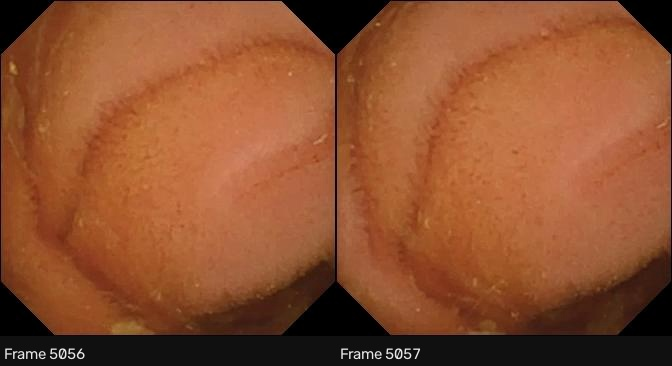

temporal_collage


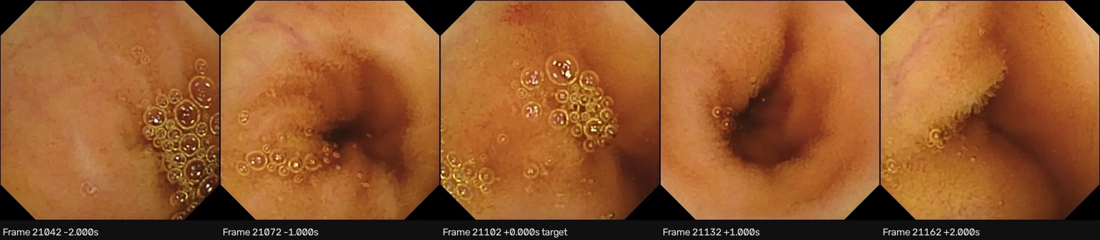

combined_panel


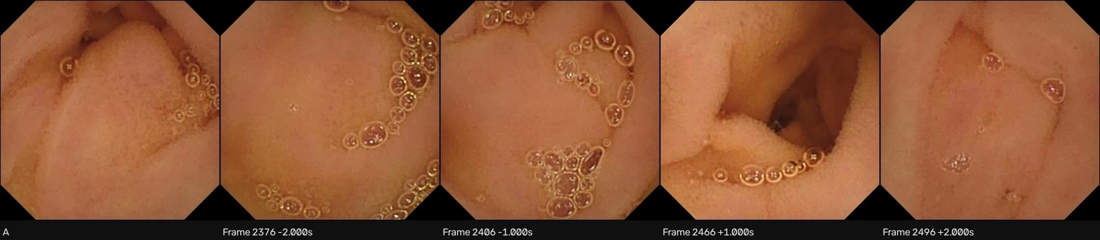

quality_panel


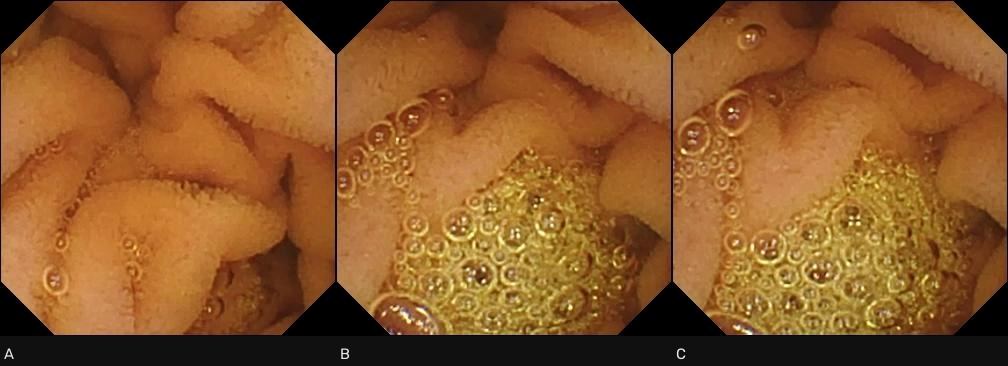

bbox_overlay


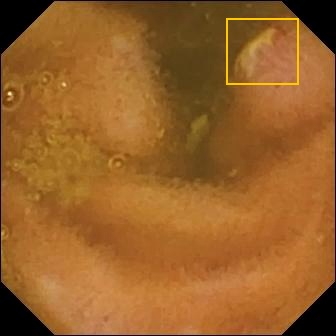

evidence_panel


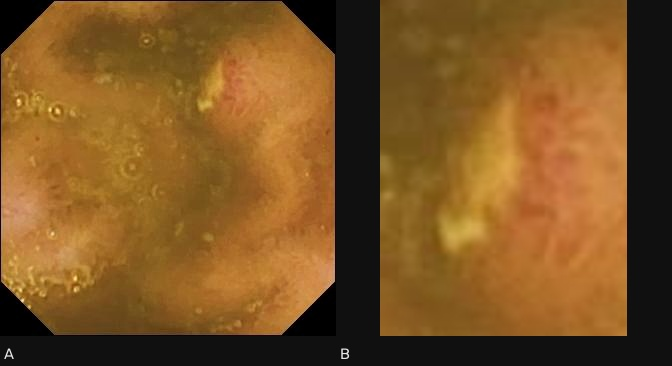

roi_crop


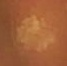

comparison_panel


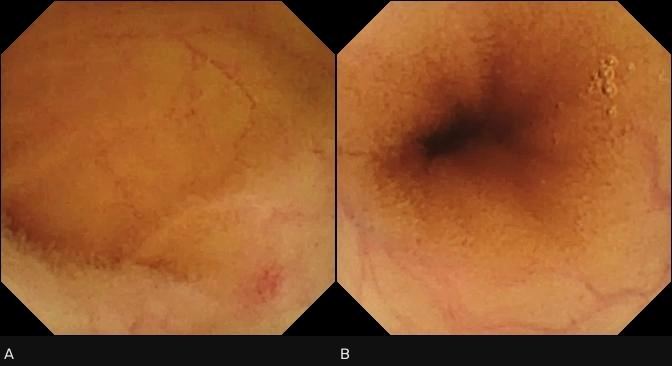

Manifest tables: ['visual_manifest', 'visual_source_manifest', 'source_evidence_manifest', 'benchmark_input_manifest', 'benchmark_ground_truth_manifest', 'shared_source_groups', 'skipped_products']


In [18]:
# One preview per generated kind, read directly from SSD.
previewed = set()
for record in RUN['records']:
    if record.get('materialized', True) and record['kind'] not in previewed:
        print(record['kind'])
        with Image.open(Path(RUN['run_dir']) / record['relative_path']) as opened:
            preview = opened.copy()
            preview.thumbnail((1100, 600))
            display(preview)
        previewed.add(record['kind'])
print('Manifest tables:', list(RUN['tables']))


## 10. Actual model input

The example selects an available `fullcrop` recipe and loads two PIL images in the specified order. Change `SELECTED_VARIANT` for other variants. `QUESTION` is only a demonstration question; it is not added to the benchmark as validated QA.

The `MODEL_INPUT` object can be adapted to the selected model's processor. Image duplicates are not required for each experiment. For `temporal_multi`, the order and roles identify the target/context; actual offsets come from the S7 window.

Plan source staging (metadata only; no Drive reads):   0%|          | 0/1 [00:00<?, ?file/s]

Copy/reuse sources to SSD + SHA-256:   0%|          | 0/1 [00:00<?, ?file/s]

Verify model-input SHA / load images:   0%|          | 0/2 [00:00<?, ?image/s]

Model-facing keys: ['question', 'images', 'image_roles']
Question: Describe the observable visual characteristics in the provided images.
Ordered roles: ['full_frame', 'region_of_interest']
Number of actual images: 2
full_frame (336, 336)


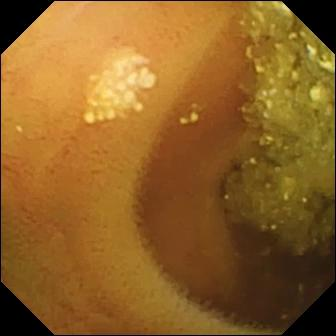

region_of_interest (110, 116)


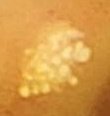

,variant,example_count
0,combined,24164
1,comparison,3357
2,crop,4127
3,full,47239
4,fullcrop,4127
5,fullcrop_panel,4127
6,overlay,4127
7,progression,33861
8,qc,47239
9,temporal_collage,22220


Preparation-only status: 216808 examples are not ready: verified final split assignment, validated QA, and available pixels are required. S8 previews remain allowed.


In [19]:
SELECTED_VARIANT = 'fullcrop'
QUESTION = 'Describe the observable visual characteristics in the provided images.'
choices = [r for r in RUN['benchmark']['examples'] if r['variant'] == SELECTED_VARIANT]
if choices:
    EXAMPLE = choices[0]
    MODEL_INPUT = s8_load_model_input(EXAMPLE, QUESTION, CONFIG, RUN['run_dir'])
    print('Model-facing keys:', list(MODEL_INPUT))
    print('Question:', MODEL_INPUT['question'])
    print('Ordered roles:', MODEL_INPUT['image_roles'])
    print('Number of actual images:', len(MODEL_INPUT['images']))
    for role, pixels in zip(MODEL_INPUT['image_roles'], MODEL_INPUT['images']):
        print(role, pixels.size)
        display(pixels)
else:
    print('Variant unavailable in the selected subset; inspect coverage and skip reasons.')

display(pd.DataFrame(sorted(RUN['benchmark']['coverage']['examples_by_variant'].items()),
                     columns=['variant','example_count']))
# Expected until a downstream stage supplies validated QA and final splits:
try:
    s8_assert_benchmark_ready(RUN['benchmark'])
except RuntimeError as error:
    print('Preparation-only status:', error)


## 11. Drive export with file confirmation

This cell authenticates Drive access from Colab. It saves only S8 products and metadata under the project root. The API verifies each destination and retransmits only missing or different files. The final catalog becomes visible after all products/metadata are confirmed. Rerun the cell after an interruption; do not restart generation if only export failed.

`RUN['state']['complete']` describes the local result. Cloud confirmation is `DRIVE_RECEIPT['complete']`. The manifest may appear through the mount later than through the API; API confirmation does not depend on a readback through the DriveFS cache.

In [25]:
EXPORT_CONFIG = {
    **CONFIG,
    'archive_workers': 4,
    'archive_upload_workers': 8,
    'archive_api_read_workers': 8,
    'drive_hash_workers': 32,
    'drive_archive_chunk_bytes': 32 * 1024**2,
    'drive_sha256_wait_timeout_seconds': 300,
    'drive_ack_timeout_seconds': 6 * 3600,
}

DRIVE_RECEIPT = s8_export_archive_drive(
    RUN['state'],
    RUN['run_dir'],
    EXPORT_CONFIG,
)

print({
    key: DRIVE_RECEIPT.get(key)
    for key in (
        'status', 'complete', 'archive_count',
        'member_count', 'total', 'verified', 'pending'
    )
})

assert DRIVE_RECEIPT['complete'] is True

Verify SSD archive inputs SHA-256:   0%|          | 0/118220 [00:00<?, ?file/s]

Build/reuse category TAR + verify SSD SHA-256:   0%|          | 0/8 [00:00<?, ?archive/s]

Verify archive input file seals:   0%|          | 0/118220 [00:00<?, ?file/s]

Stage archive delivery metadata on SSD:   0%|          | 0/19 [00:00<?, ?file/s]

Verify SSD export SHA-256/MD5:   0%|          | 0/30 [00:00<?, ?file/s]

...

Drive API: resolve inventory folders:   0%|          | 0/8 [00:00<?, ?folder/s]

Drive API: list files/checksum metadata:   0%|          | 0/30 [00:00<?, ?file/s]

Compare remote size + SHA-256/MD5:   0%|          | 0/30 [00:00<?, ?file/s]

Verify SSD export file seals:   0%|          | 0/30 [00:00<?, ?file/s]

S8 Drive delivery confirmed: 30 files; 30 payloads added/replaced.
{'status': 'complete', 'complete': True, 'archive_count': 8, 'member_count': 118201, 'total': 30, 'verified': 30, 'pending': 0}


## 12. Local directory for potential GitHub publication

Prepares Parquet/JSON/schemas and product hashes. JPEGs remain on Drive. `product_hash_diff.json` compares the previous S8 catalog with the current one; `metadata_hash_diff.json` compares against the previous local review directory. These comparisons do not claim that GitHub already contains a particular version.

No Git commands or GitHub uploads are executed. A later commit/PR can publish the files in this directory after your verification in Colab. The `.json.gz` and `.jsonl.gz` archives reduce metadata size and preserve deterministic bytes.

In [33]:
# Fresh Drive fetch gate for metadata publication. Imports stay centralized.


def s8_publication_metadata_path(relative):
    """Accept only explicit metadata paths, never image/archive/session payloads."""
    parts = s8_cloud_relative(relative).parts
    allowed_roots = {'metadata', 'configs', 'reports', 'tables', 'results', 'benchmark'}
    if (parts[0] not in allowed_roots or any(part.startswith('.') for part in parts)
            or any(part in ('products', 'archives', 'checkpoints', 'github_review') for part in parts)
            or not relative.lower().endswith(('.json', '.parquet', '.json.gz', '.jsonl.gz'))):
        raise ValueError('The GitHub publication scope contains a non-metadata path: ' + relative)
    return relative


def s8_validate_archive_publication_source(run, config, receipt):
    """Bind a confirmed delivery receipt to the actual local logical run metadata."""
    if (not isinstance(receipt, dict) or receipt.get('complete') is not True
            or receipt.get('pending') != 0 or receipt.get('storage_mode') != 'tar_per_product_folder'):
        raise ValueError('Complete and confirm the archive export in Section 11 first.')
    root = s8_storage_assert_ssd(run['run_dir'], config)
    bundle = s8_storage_assert_ssd(receipt['bundle_dir'], config)
    catalog_relative = 'configs/sector8_archive_state.json'
    manifest_relative = 'configs/sector8_archives.json'
    semantic_relative = 'configs/sector8_state.json'
    proof_rows = receipt.get('proofs', [])
    proofs = {row['relative_path']: row for row in proof_rows}
    if (len(proofs) != len(proof_rows) or receipt.get('total') != len(proofs)
            or receipt.get('verified') != len(proofs)):
        raise ValueError('Archive delivery receipt has inconsistent proof counts.')
    for relative, proof in proofs.items():
        s8_cloud_relative(relative)
        if (proof.get('algorithm') != 'sha256' or not s8_storage_valid_sha(proof.get('sha256'))
                or proof.get('cloud_checksum') != proof['sha256']
                or proof.get('local_sha256') != proof['sha256'] or not proof.get('file_id')):
            raise ValueError('Every cloud proof must have matching SHA-256 evidence.')

    def read_verified_json(relative):
        proof = proofs.get(relative)
        if proof is None:
            raise ValueError('Missing archive metadata delivery proof: ' + relative)
        path = s8_storage_path(bundle, relative)
        before = s8_storage_stat(path)
        raw = path.read_bytes()
        identity = {'sha256': hashlib.sha256(raw).hexdigest(), 'bytes': len(raw)}
        if (identity['sha256'] != proof['sha256'] or identity['bytes'] != proof.get('bytes')
                or before != s8_storage_stat(path)):
            raise ValueError('Archive metadata changed since cloud confirmation: ' + relative)
        return json.loads(raw), identity

    with s8_storage_progress(total=2, config=config, unit='file',
                             desc='Bind archive publication to confirmed metadata') as progress:
        catalog, catalog_identity = read_verified_json(catalog_relative)
        progress.update(1)
        manifest, manifest_identity = read_verified_json(manifest_relative)
        progress.update(1)
    if catalog_identity['sha256'] != receipt.get('source_catalog_sha256'):
        raise ValueError('The receipt belongs to a different archive delivery catalog.')
    descriptors = {row['relative_path']: row for row in catalog.get('artifacts', [])}
    if (catalog.get('complete') is not True or len(descriptors) != len(catalog.get('artifacts', []))
            or set(proofs) != set(descriptors) | {catalog_relative}):
        raise ValueError('The archive catalog and confirmed cloud inventory disagree.')
    for relative, record in descriptors.items():
        s8_cloud_relative(relative)
        proof = proofs[relative]
        if record.get('sha256') != proof['sha256'] or record.get('bytes') != proof.get('bytes'):
            raise ValueError('Catalog descriptor differs from confirmed cloud bytes: ' + relative)
    semantic_path = s8_storage_path(root, semantic_relative)
    before = s8_storage_stat(semantic_path)
    semantic_bytes = semantic_path.read_bytes()
    semantic_sha256 = hashlib.sha256(semantic_bytes).hexdigest()
    if (before != s8_storage_stat(semantic_path) or json.loads(semantic_bytes) != run['state']
            or catalog.get('logical_artifacts') != run['state']['artifacts']
            or any(catalog.get(key) != value for key, value in run['state'].items() if key != 'artifacts')
            or manifest.get('source_catalog_sha256') != semantic_sha256
            or descriptors.get(semantic_relative, {}).get('sha256') != semantic_sha256
            or manifest.get('logical_artifacts_sha256') != hashlib.sha256(
                s8_storage_json_bytes(run['state']['artifacts'])).hexdigest()):
        raise ValueError('Archive references belong to a different logical S8 run.')
    if (catalog.get('archive_delivery') != {'mode': 'tar_per_product_folder',
                                          'manifest_relative_path': manifest_relative}
            or manifest.get('schema_version') != 1 or manifest.get('mode') != 'tar_per_product_folder'):
        raise ValueError('Unsupported archive delivery metadata contract.')
    groups, metadata = s8_archive_member_records(run['state'])
    archives = manifest.get('archives', [])
    if (manifest.get('archive_count') != len(archives) or len(archives) != len(groups)
            or len({row['kind'] for row in archives}) != len(groups)
            or {row['kind'] for row in archives} != set(groups)
            or manifest.get('member_count') != sum(len(rows) for rows in groups.values())):
        raise ValueError('Archive member/category counts disagree with the S8 run.')
    for archive in archives:
        relative = archive['relative_path']
        declared = descriptors.get(relative, {})
        if (relative != 'archives/' + archive['kind'] + '.tar'
                or archive.get('members') != groups[archive['kind']]
                or archive.get('member_count') != len(groups[archive['kind']])
                or archive.get('sha256') != declared.get('sha256')
                or archive.get('bytes') != declared.get('bytes')):
            raise ValueError('Archive membership or identity does not match its confirmed descriptor.')
    selected = [row['relative_path'] for row in metadata]
    selected.extend([semantic_relative, manifest_relative, catalog_relative])
    if len(set(selected)) != len(selected):
        raise ValueError('Duplicate publication metadata path.')
    for relative in selected:
        s8_publication_metadata_path(relative)
    expected = {relative: {'relative_path': relative, 'sha256': proof['sha256'], 'bytes': proof['bytes']}
                for relative, proof in proofs.items()}
    for record in metadata:
        expected_record = expected.get(record['relative_path'], {})
        if (record.get('sha256') != expected_record.get('sha256')
                or record.get('bytes') != expected_record.get('bytes')):
            raise ValueError('Publication metadata differs from the original logical S8 catalog.')
    if set(expected) != set(selected) | {row['relative_path'] for row in archives}:
        raise ValueError('Unexpected payload in the archive delivery catalog.')
    return {'run_root': root, 'bundle_root': bundle, 'catalog': catalog, 'manifest': manifest,
            'expected': expected, 'selected': sorted(selected),
            'catalog_relative': catalog_relative, 'manifest_relative': manifest_relative,
            'semantic_catalog_sha256': semantic_sha256, 'source_catalog_sha256': catalog_identity['sha256']}


def s8_fetch_confirmed_drive_metadata(run, config, receipt, api=None):
    """Fetch fresh metadata bytes, recheck Drive archives, and gate publication."""
    source = s8_validate_archive_publication_source(run, config, receipt)
    root = source['run_root']
    expected, selected = source['expected'], source['selected']
    output = s8_storage_path(root, 'checkpoints/github_drive_fetch/' + source['source_catalog_sha256'])
    output.mkdir(parents=True, exist_ok=True)
    local_receipt_path = output.parent / (source['source_catalog_sha256'] + '.verification.json')
    config_workers = int(config.get('github_drive_fetch_workers', 8))
    if config_workers < 1:
        raise ValueError('github_drive_fetch_workers must be positive.')
    client = api if api is not None else s8_make_drive_api()
    parts, _ = s8_cloud_parts(config)
    if isinstance(client, S8DriveAPI):
        # Fresh publication validation must never create or mutate Drive paths.
        client._required_prefix_length = len(parts)
        client._progress_config = {
            'progress_bars': config.get('progress_bars', True),
            'drive_api_read_workers': int(config.get('archive_api_read_workers', 8)),
            'drive_api_read_retries': int(config.get('drive_api_read_retries', 4)),
        }
    workers = config_workers
    if (not callable(getattr(client, 'new_worker', None))
            or isinstance(client, S8DriveAPI) and client._worker_factory is None):
        workers = 1
    stop_event, thread_clients = threading.Event(), threading.local()
    activity = {'lock': threading.Lock(), 'fetched_bytes': 0, 'fetched_MiB': 0.0}

    def verify_inventory(observed, label):
        proofs = {}
        with s8_storage_progress(total=len(expected), config=config, unit='file', desc=label) as progress:
            for relative, record in expected.items():
                metadata = observed.get(relative)
                proof = s8_cloud_match(record, metadata)
                if proof is None or proof.get('algorithm') != 'sha256' or not metadata.get('id'):
                    raise RuntimeError('Drive SHA-256/size is missing or changed: ' + relative
                                       + '. Rerun archive export before publication.')
                proofs[relative] = {**record, 'file_id': metadata['id'], **proof}
                progress.update(1)
        return proofs

    def fetch_one(relative):
        if stop_event.is_set():
            raise InterruptedError('Drive metadata fetch cancelled.')
        worker = client
        if workers > 1:
            if not hasattr(thread_clients, 'client'):
                thread_clients.client = client.new_worker()
            worker = thread_clients.client
        record = expected[relative]
        destination = s8_storage_path(output, relative)
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_name(destination.name + '.fetch-' + uuid.uuid4().hex)
        response = None
        try:
            with s8_storage_progress(total=record['bytes'], config=config, unit='B', unit_scale=True,
                                     desc='Fetch ' + Path(relative).name, leave=False) as byte_progress:
                def advanced(count):
                    if stop_event.is_set():
                        raise InterruptedError('Drive metadata fetch cancelled.')
                    byte_progress.update(count)
                    with activity['lock']:
                        activity['fetched_bytes'] += count
                        activity['fetched_MiB'] = round(activity['fetched_bytes'] / 1024 ** 2, 1)
                download_adapter = getattr(worker, 'download_metadata', None)
                if callable(download_adapter):
                    download_adapter(before_inventory[relative]['id'], temporary, dict(record),
                                     progress_callback=advanced)
                    before = s8_storage_stat(temporary)
                    identity = s8_storage_hashes(temporary)
                    if before != s8_storage_stat(temporary):
                        raise RuntimeError('Fetched Drive metadata changed locally: ' + relative)
                    advanced(max(0, identity['bytes'] - byte_progress.n))
                else:
                    file_id = str(before_inventory[relative]['id'])
                    if not re.fullmatch(r'[A-Za-z0-9_-]+', file_id):
                        raise RuntimeError('Drive returned an invalid file identity.')
                    response = worker._response('GET', worker._base + '/files/' + file_id,
                                                params={'alt': 'media'}, stream=True, allow_redirects=False)
                    if response.status_code != 200:
                        raise RuntimeError('Drive metadata fetch did not return a complete payload.')
                    sha256, size = hashlib.sha256(), 0
                    with temporary.open('wb') as stream:
                        for block in response.iter_content(chunk_size=8 * 1024 * 1024):
                            if stop_event.is_set():
                                raise InterruptedError('Drive metadata fetch cancelled.')
                            if not block:
                                continue
                            size += len(block)
                            if size > record['bytes']:
                                raise RuntimeError('Drive metadata exceeds its confirmed size: ' + relative)
                            stream.write(block)
                            sha256.update(block)
                            advanced(len(block))
                        stream.flush()
                        os.fsync(stream.fileno())
                    identity = {'sha256': sha256.hexdigest(), 'bytes': size}
                if identity['sha256'] != record['sha256'] or identity['bytes'] != record['bytes']:
                    raise RuntimeError('Fetched Drive metadata SHA-256/size mismatch: ' + relative)
                os.replace(temporary, destination)
                return {'relative_path': relative, 'sha256': identity['sha256'], 'bytes': identity['bytes']}
        finally:
            if response is not None:
                response.close()
            temporary.unlink(missing_ok=True)

    downloaded = {}
    def fetched(relative, value, error):
        if error is not None:
            raise error
        downloaded[relative] = value

    pending_receipt = {'complete': False, 'status': 'fetching',
                       'source_catalog_sha256': source['source_catalog_sha256']}
    receipt_started = False
    try:
        with s8_workspace_lock(root / '.cloud-delivery.lock'), s8_workspace_lock(output / '.fetch.lock'):
            s8_storage_atomic_json(local_receipt_path, pending_receipt)
            receipt_started = True
            root_id = client.resolve_root(parts)
            before_inventory = client.inventory(root_id, list(expected))
            verify_inventory(before_inventory, 'Drive API: fresh archive + metadata SHA-256 before fetch')
            if isinstance(client, S8DriveAPI):
                client._open_worker_sessions()
            try:
                with s8_storage_progress(total=len(selected), config=config, unit='file',
                                         desc='Fetch verified Drive metadata for GitHub') as progress:
                    execution = s8_storage_parallel_map(selected, fetch_one, workers, fetched,
                        progress=progress, metrics=activity, stop_event=stop_event)
            finally:
                if isinstance(client, S8DriveAPI):
                    client._close_worker_sessions()
            after_inventory = client.inventory(client.resolve_root(parts), list(expected))
            final_proofs = verify_inventory(after_inventory, 'Drive API: recheck archive + metadata SHA-256 after fetch')
            if any(before_inventory[key]['id'] != after_inventory[key]['id'] for key in expected):
                raise RuntimeError('Drive file identities changed during metadata fetch; rerun publication.')
            fetched_catalog = json.loads(s8_storage_path(output, source['catalog_relative']).read_text(encoding='utf-8'))
            fetched_manifest = json.loads(s8_storage_path(output, source['manifest_relative']).read_text(encoding='utf-8'))
            fetched_semantic = json.loads(s8_storage_path(output, 'configs/sector8_state.json').read_text(encoding='utf-8'))
            if (fetched_catalog != source['catalog'] or fetched_manifest != source['manifest']
                    or fetched_semantic != run['state']):
                raise RuntimeError('Fetched Drive catalogs do not describe the current S8 run.')
            # Keep published proof content stable for identical bytes. Operational
            # timestamps and Drive IDs belong only in the local verification receipt.
            stable_proofs = [{key: final_proofs[relative][key] for key in
                ('relative_path', 'bytes', 'sha256', 'algorithm', 'cloud_checksum', 'local_sha256')}
                for relative in sorted(final_proofs)]
            report_relative = 'reports/sector8_archive_delivery.json'
            if report_relative in downloaded:
                raise ValueError('Logical metadata conflicts with the generated cloud evidence report.')
            delivery_report = {
                'schema_version': 1, 'storage_mode': 'tar_per_product_folder', 'complete': True,
                'archive_count': source['manifest']['archive_count'],
                'member_count': source['manifest']['member_count'],
                'total': len(expected), 'verified': len(expected), 'pending': 0,
                'semantic_catalog_sha256': source['semantic_catalog_sha256'],
                'archive_catalog': expected[source['catalog_relative']],
                'archive_manifest': expected[source['manifest_relative']],
                'metadata_fetched_from_drive': True, 'proofs': stable_proofs,
                'note': 'Drive metadata bytes were fetched and SHA-256 verified before publication; '
                        'archive checksums were checked through the API. The Git commit records publication time.',
            }
            report_path = s8_storage_path(output, report_relative)
            s8_storage_atomic_json(report_path, delivery_report)
            report_identity = s8_storage_hashes(report_path)
            downloaded[report_relative] = {'relative_path': report_relative,
                                           'sha256': report_identity['sha256'], 'bytes': report_identity['bytes']}
            result = {'complete': True, 'status': 'verified_from_drive', 'root': str(output),
                      'files': [downloaded[key] for key in sorted(downloaded)],
                      'source_catalog_sha256': source['source_catalog_sha256'],
                      'verification_receipt_path': str(local_receipt_path),
                      'checked_at_utc': datetime.now(timezone.utc).isoformat(),
                      'cloud_proofs': [final_proofs[key] for key in sorted(final_proofs)],
                      'fetch_execution': execution}
            s8_storage_atomic_json(local_receipt_path, result)
            return result
    except BaseException as error:
        if receipt_started:
            pending_receipt.update(status='verification_failed', error_type=type(error).__name__)
            s8_storage_atomic_json(local_receipt_path, pending_receipt)
        raise
    finally:
        if api is None:
            close = getattr(getattr(client, 'session', None), 'close', None)
            if callable(close):
                close()

# Exact-byte storage for large verified metadata. Imports stay centralized.


def s8_github_storage_limits(config):
    maximum = config.get('github_max_metadata_file_bytes', 90 * 1024**2)
    chunk = config.get('github_metadata_chunk_bytes', 32 * 1024**2)
    if isinstance(maximum, bool) or not isinstance(maximum, int) or maximum <= 0:
        raise ValueError('github_max_metadata_file_bytes must be a positive integer.')
    maximum = min(maximum, 90 * 1024**2)
    if isinstance(chunk, bool) or not isinstance(chunk, int) or not 0 < chunk < maximum:
        raise ValueError('github_metadata_chunk_bytes must be positive and smaller than the metadata file limit.')
    return maximum, chunk


def s8_github_storage_logical_record(row):
    if not isinstance(row, dict):
        raise ValueError('A metadata descriptor must be an object.')
    relative = row.get('relative_path')
    s8_publication_metadata_path(relative)
    if (relative == 'configs/sector8_github_storage.json'
            or relative.startswith('metadata/_github_chunks/')):
        raise ValueError('Logical metadata conflicts with the reserved GitHub storage namespace.')
    if not s8_storage_valid_sha(row.get('sha256')):
        raise ValueError('Metadata has a missing or invalid SHA-256: ' + relative)
    size = row.get('bytes')
    if isinstance(size, bool) or not isinstance(size, int) or size < 0:
        raise ValueError('Metadata byte size must be a nonnegative integer: ' + relative)
    return {'relative_path': relative, 'sha256': row['sha256'], 'bytes': size}


def s8_prepare_github_metadata_storage(verified, config):
    """Preserve verified metadata bytes using direct files or bounded binary parts."""
    if not isinstance(verified, dict) or verified.get('complete') is not True:
        raise ValueError('A complete Drive metadata fetch is required before GitHub packaging.')
    if not s8_storage_valid_sha(verified.get('source_catalog_sha256')):
        raise ValueError('Verified metadata must identify the source archive catalog SHA-256.')
    source_root = s8_storage_assert_ssd(verified['root'], config)
    records = [s8_github_storage_logical_record(row) for row in verified.get('files', [])]
    if not records or len({row['relative_path'] for row in records}) != len(records):
        raise ValueError('Verified metadata needs a nonempty, unique logical file list.')
    records.sort(key=lambda row: row['relative_path'])
    logical = {row['relative_path']: row for row in records}
    catalog = logical.get('configs/sector8_archive_state.json')
    if catalog is None or catalog['sha256'] != verified['source_catalog_sha256']:
        raise ValueError('The logical file list lacks its matching archive catalog.')
    maximum, part_bytes = s8_github_storage_limits(config)
    output = s8_storage_path(source_root, 'checkpoints/github_storage/bundle')
    output.mkdir(parents=True, exist_ok=True)
    index_relative = 'configs/sector8_github_storage.json'
    physical, entries = {}, []
    reused_parts = written_parts = 0

    def register(relative, identity):
        record = {'relative_path': relative, 'sha256': identity['sha256'], 'bytes': identity['bytes']}
        if relative in physical and physical[relative] != record:
            raise ValueError('Conflicting physical metadata descriptor: ' + relative)
        physical[relative] = record

    with s8_workspace_lock(output.parent / '.prepare.lock'), s8_storage_progress(
            total=sum(row['bytes'] for row in records), config=config, unit='B', unit_scale=True,
            desc='Prepare GitHub metadata storage + verify SHA-256') as progress:
        for row in records:
            relative, size = row['relative_path'], row['bytes']
            source = s8_storage_path(source_root, relative)
            before = s8_storage_stat(source)
            if before[2] != size:
                raise S8CloudSourceChanged('Verified metadata size changed before packaging: ' + relative)
            digest, count = hashlib.sha256(), 0
            # The API payload budget applies to every blob, including direct
            # metadata. The larger Git file guard is not a safe POST budget.
            progress.set_postfix(file=Path(relative).name, logical_MiB=round(size / 1024**2, 2),
                                 storage='parts' if size > part_bytes else 'direct', refresh=False)
            if size <= part_bytes:
                target = s8_storage_path(output, relative)
                target.parent.mkdir(parents=True, exist_ok=True)
                temporary = target.with_name(target.name + '.partial-' + uuid.uuid4().hex)
                try:
                    with source.open('rb') as incoming, temporary.open('wb') as outgoing:
                        while True:
                            block = incoming.read(8 * 1024**2)
                            if not block:
                                break
                            count += len(block)
                            if count > size:
                                raise S8CloudSourceChanged('Verified metadata grew during packaging: ' + relative)
                            digest.update(block)
                            outgoing.write(block)
                            progress.update(len(block))
                        outgoing.flush()
                        os.fsync(outgoing.fileno())
                    if (count != size or digest.hexdigest() != row['sha256']
                            or before != s8_storage_stat(source)):
                        raise S8CloudSourceChanged('Verified metadata SHA-256/size changed during packaging: ' + relative)
                    actual = s8_storage_hashes(temporary)
                    if actual['sha256'] != row['sha256'] or actual['bytes'] != size:
                        raise RuntimeError('Staged GitHub metadata failed SSD verification: ' + relative)
                    os.replace(temporary, target)
                finally:
                    temporary.unlink(missing_ok=True)
                register(relative, row)
                entries.append({**row, 'storage': 'direct', 'github_relative_path': relative})
            else:
                parts = []
                with source.open('rb') as incoming:
                    while True:
                        block = incoming.read(part_bytes)
                        if not block:
                            break
                        offset = count
                        count += len(block)
                        if count > size:
                            raise S8CloudSourceChanged('Verified metadata grew during packaging: ' + relative)
                        digest.update(block)
                        part_sha = hashlib.sha256(block).hexdigest()
                        part_relative = 'metadata/_github_chunks/' + part_sha + '.bin'
                        identity = {'sha256': part_sha, 'bytes': len(block)}
                        if part_relative not in physical:
                            target = s8_storage_path(output, part_relative)
                            valid = False
                            if target.is_file():
                                observed = s8_storage_hashes(target)
                                valid = observed['sha256'] == part_sha and observed['bytes'] == len(block)
                            if valid:
                                reused_parts += 1
                            else:
                                s8_storage_atomic_bytes(target, block)
                                observed = s8_storage_hashes(target)
                                if observed['sha256'] != part_sha or observed['bytes'] != len(block):
                                    raise RuntimeError('A GitHub metadata part failed SSD verification.')
                                written_parts += 1
                            register(part_relative, identity)
                        parts.append({'ordinal': len(parts), 'offset': offset,
                                      'relative_path': part_relative, **identity})
                        progress.update(len(block))
                if (count != size or digest.hexdigest() != row['sha256']
                        or before != s8_storage_stat(source)):
                    raise S8CloudSourceChanged('Verified metadata SHA-256/size changed during packaging: ' + relative)
                entries.append({**row, 'storage': 'parts', 'parts': parts})
        index = {'schema_version': 1, 'mode': 'exact_byte_parts',
                 'source_catalog_sha256': verified['source_catalog_sha256'],
                 'part_bytes': part_bytes, 'files': entries}
        index_payload = s8_storage_json_bytes(index)
        if len(index_payload) > part_bytes or len(index_payload) >= maximum:
            raise ValueError('The GitHub metadata storage index exceeds the configured API blob budget; '
                             'reduce the index scope before publication.')
        index_path = s8_storage_path(output, index_relative)
        s8_storage_atomic_bytes(index_path, index_payload)
        index_identity = s8_storage_hashes(index_path)
        if index_identity['sha256'] != hashlib.sha256(index_payload).hexdigest():
            raise RuntimeError('The GitHub metadata storage index failed SSD verification.')
        register(index_relative, index_identity)
    result = {**verified, 'root': str(output), 'files': [physical[key] for key in sorted(physical)],
              'logical_files': records, 'storage_index_relative': index_relative,
              'storage_index_sha256': index_identity['sha256'],
              'github_storage_mode': 'exact_byte_parts',
              'storage_summary': {'logical_files': len(records), 'physical_files': len(physical),
                  'sharded_files': sum(row['storage'] == 'parts' for row in entries),
                  'unique_parts': sum(path.startswith('metadata/_github_chunks/') for path in physical),
                  'reused_parts': reused_parts, 'written_parts': written_parts}}
    s8_validate_github_metadata_storage(result, config)
    return result


def s8_validate_github_metadata_storage(prepared, config):
    """Validate the exact storage index and physical allowlist before publication."""
    if not isinstance(prepared, dict) or prepared.get('complete') is not True:
        raise ValueError('A complete metadata storage preparation is required.')
    if prepared.get('github_storage_mode') != 'exact_byte_parts':
        raise ValueError('Unsupported GitHub metadata storage mode.')
    maximum, configured_part_bytes = s8_github_storage_limits(config)
    root = s8_storage_assert_ssd(prepared['root'], config)
    index_relative = prepared.get('storage_index_relative')
    if index_relative != 'configs/sector8_github_storage.json':
        raise ValueError('Unexpected GitHub metadata storage index path.')
    if not s8_storage_valid_sha(prepared.get('storage_index_sha256')):
        raise ValueError('The GitHub storage index requires a valid SHA-256.')
    path = s8_storage_path(root, index_relative)
    before = s8_storage_stat(path)
    if before[2] > configured_part_bytes or before[2] >= maximum:
        raise ValueError('The GitHub metadata storage index exceeds the API blob budget.')
    raw = path.read_bytes()
    if (hashlib.sha256(raw).hexdigest() != prepared['storage_index_sha256']
            or before != s8_storage_stat(path)):
        raise ValueError('The GitHub metadata storage index changed after preparation.')
    index = json.loads(raw)
    if (not isinstance(index, dict) or type(index.get('schema_version')) is not int
            or index.get('schema_version') != 1 or index.get('mode') != 'exact_byte_parts'
            or type(index.get('part_bytes')) is not int
            or index.get('part_bytes') != configured_part_bytes
            or not s8_storage_valid_sha(index.get('source_catalog_sha256'))
            or index['source_catalog_sha256'] != prepared.get('source_catalog_sha256')):
        raise ValueError('Invalid GitHub metadata storage index header.')
    logical_rows = [s8_github_storage_logical_record(row) for row in prepared.get('logical_files', [])]
    logical = {row['relative_path']: row for row in logical_rows}
    if not logical or len(logical) != len(logical_rows):
        raise ValueError('Logical GitHub metadata descriptors must be unique and nonempty.')
    catalog = logical.get('configs/sector8_archive_state.json')
    if catalog is None or catalog['sha256'] != prepared['source_catalog_sha256']:
        raise ValueError('The storage index does not bind its original archive catalog.')
    indexed, physical = {}, {index_relative: {'relative_path': index_relative,
        'sha256': prepared['storage_index_sha256'], 'bytes': len(raw)}}
    index_files = index.get('files')
    if not isinstance(index_files, list):
        raise ValueError('The metadata storage index requires a file list.')
    for entry in index_files:
        original = s8_github_storage_logical_record(entry)
        relative = original['relative_path']
        if relative in indexed or original != logical.get(relative):
            raise ValueError('Storage index logical descriptors are duplicated or changed.')
        indexed[relative] = original
        if entry.get('storage') == 'direct':
            if (entry.get('github_relative_path') != relative or original['bytes'] > configured_part_bytes
                    or 'parts' in entry):
                raise ValueError('Invalid direct metadata mapping.')
            physical[relative] = original
        elif entry.get('storage') == 'parts':
            if original['bytes'] <= configured_part_bytes or 'github_relative_path' in entry:
                raise ValueError('Invalid split metadata mapping.')
            parts, offset = entry.get('parts', []), 0
            if not isinstance(parts, list) or not parts:
                raise ValueError('Split metadata requires an ordered nonempty part list.')
            for ordinal, part in enumerate(parts):
                if not isinstance(part, dict):
                    raise ValueError('A metadata part descriptor must be an object.')
                sha, size = part.get('sha256'), part.get('bytes')
                if (not s8_storage_valid_sha(sha) or isinstance(size, bool) or not isinstance(size, int)
                        or not 0 < size <= configured_part_bytes or size >= maximum
                        or part.get('ordinal') != ordinal or part.get('offset') != offset
                        or type(part.get('ordinal')) is not int or type(part.get('offset')) is not int
                        or ordinal < len(parts) - 1 and size != configured_part_bytes
                        or part.get('relative_path') != 'metadata/_github_chunks/' + str(sha) + '.bin'):
                    raise ValueError('Invalid metadata part order, offset, size, or content identity.')
                record = {key: part[key] for key in ('relative_path', 'sha256', 'bytes')}
                if record['relative_path'] in physical and physical[record['relative_path']] != record:
                    raise ValueError('Conflicting deduplicated metadata part descriptor.')
                physical[record['relative_path']] = record
                offset += size
            if offset != original['bytes']:
                raise ValueError('Metadata part sizes do not reconstruct the original file size.')
        else:
            raise ValueError('Unsupported metadata storage entry.')
    if set(indexed) != set(logical):
        raise ValueError('Storage index does not cover every verified logical metadata file.')
    supplied = {}
    for row in prepared.get('files', []):
        if not isinstance(row, dict):
            raise ValueError('A physical metadata descriptor must be an object.')
        relative = row.get('relative_path')
        s8_cloud_relative(relative)
        record = {key: row.get(key) for key in ('relative_path', 'sha256', 'bytes')}
        if relative in supplied or record != physical.get(relative):
            raise ValueError('Physical metadata allowlist contains an unexpected or changed file.')
        supplied[relative] = record
    if supplied != physical:
        raise ValueError('Physical metadata allowlist does not match the exact storage index.')
    return index


def s8_reassemble_github_metadata(index, relative, repo_root, destination):
    """Reassemble already downloaded metadata locally; verify parts and full SHA-256."""
    s8_github_storage_logical_record({'relative_path': relative, 'sha256': '0' * 64, 'bytes': 0})
    if (not isinstance(index, dict) or type(index.get('schema_version')) is not int
            or index.get('schema_version') != 1 or index.get('mode') != 'exact_byte_parts'
            or type(index.get('part_bytes')) is not int or index['part_bytes'] <= 0):
        raise ValueError('Unsupported metadata storage index.')
    index_files = index.get('files')
    if not isinstance(index_files, list) or any(not isinstance(row, dict) for row in index_files):
        raise ValueError('The metadata storage index requires a list of file descriptors.')
    matches = [row for row in index_files if row.get('relative_path') == relative]
    if len(matches) != 1:
        raise ValueError('The storage index must contain exactly one requested metadata entry.')
    entry = matches[0]
    original = s8_github_storage_logical_record(entry)
    if entry.get('storage') == 'direct':
        if entry.get('github_relative_path') != relative or 'parts' in entry:
            raise ValueError('Invalid direct metadata mapping.')
        parts = [{'ordinal': 0, 'offset': 0, **original}]
    elif entry.get('storage') == 'parts':
        parts = entry.get('parts', [])
        if not isinstance(parts, list) or not parts or 'github_relative_path' in entry:
            raise ValueError('Split metadata requires ordered parts.')
    else:
        raise ValueError('Unsupported metadata storage entry.')
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + '.partial-' + uuid.uuid4().hex)
    total, digest = 0, hashlib.sha256()
    try:
        with temporary.open('wb') as outgoing:
            for ordinal, part in enumerate(parts):
                if not isinstance(part, dict):
                    raise ValueError('A metadata part descriptor must be an object.')
                sha, size = part.get('sha256'), part.get('bytes')
                if (not s8_storage_valid_sha(sha) or isinstance(size, bool) or not isinstance(size, int) or size < 0
                        or type(part.get('ordinal')) is not int or type(part.get('offset')) is not int
                        or part.get('ordinal') != ordinal or part.get('offset') != total):
                    raise ValueError('Invalid metadata part descriptor or order.')
                if entry['storage'] == 'parts' and (not 0 < size <= index['part_bytes']
                        or ordinal < len(parts) - 1 and size != index['part_bytes']):
                    raise ValueError('Invalid metadata part size.')
                part_relative = part.get('relative_path')
                if entry['storage'] == 'parts' and part_relative != 'metadata/_github_chunks/' + sha + '.bin':
                    raise ValueError('Invalid content-addressed metadata part path.')
                source = s8_storage_path(Path(repo_root), part_relative)
                before = s8_storage_stat(source)
                part_digest, part_size = hashlib.sha256(), 0
                with source.open('rb') as incoming:
                    while True:
                        block = incoming.read(8 * 1024**2)
                        if not block:
                            break
                        part_size += len(block)
                        if part_size > size or total + part_size > original['bytes']:
                            raise ValueError('Metadata part exceeds its recorded size.')
                        part_digest.update(block)
                        digest.update(block)
                        outgoing.write(block)
                if part_size != size or part_digest.hexdigest() != sha or before != s8_storage_stat(source):
                    raise ValueError('Metadata part SHA-256/size verification failed.')
                total += part_size
            outgoing.flush()
            os.fsync(outgoing.fileno())
        if total != original['bytes'] or digest.hexdigest() != original['sha256']:
            raise ValueError('Reassembled metadata does not match the original SHA-256/size.')
        installed = s8_storage_hashes(temporary)
        if installed['sha256'] != original['sha256'] or installed['bytes'] != original['bytes']:
            raise ValueError('Reassembled metadata failed SSD verification.')
        os.replace(temporary, destination)
        return {'relative_path': relative, 'path': str(destination), 'sha256': original['sha256'], 'bytes': total}
    finally:
        temporary.unlink(missing_ok=True)

# GitHub publication of freshly fetched, verified Drive metadata only.
# Imports are declared in the notebook's opening import cell.


class S8GitHubAPIError(RuntimeError):
    def __init__(self, message, status=None, method=None, path=None, details=None, context=None):
        self.status = status
        self.method = method
        self.path = path
        self.details = details or {}
        self.context = context or {}
        super().__init__(message)


def s8_github_safe_error_text(value, secrets=(), limit=700):
    """Bound API diagnostics and redact credentials without exposing request data."""
    if not isinstance(value, (str, int, float)) or isinstance(value, bool):
        return ''
    text = str(value)
    for secret in sorted((s for s in secrets if isinstance(s, str) and s), key=len, reverse=True):
        text = text.replace(secret, '[REDACTED]')
    text = re.sub(r'(?i)\b(?:github_pat_[A-Za-z0-9_]+|gh[pousr]_[A-Za-z0-9_]+)', '[REDACTED]', text)
    text = re.sub(r'(?i)\b(?:bearer|token)\s+[A-Za-z0-9._~+/-]+=*', '[REDACTED]', text)
    text = re.sub(r'[A-Za-z0-9+/=_-]{128,}', '[long value omitted]', text)
    text = re.sub(r'[\x00-\x1f\x7f]', ' ', text)
    return text if len(text) <= limit else text[:limit] + '...'


def s8_github_response_error(response, method, path, secrets=()):
    """Keep GitHub's validation explanation; never copy a request or raw response body."""
    status = None if response is None else response.status_code
    details = {'method': method, 'path': path, 'status': status}
    if response is not None:
        for header, key in (('Retry-After', 'retry_after_seconds'),
                            ('X-RateLimit-Reset', 'rate_limit_reset_epoch')):
            try:
                number = float(response.headers.get(header, ''))
                if math.isfinite(number) and number >= 0:
                    details[key] = number
            except (TypeError, ValueError):
                pass
        if response.headers.get('X-RateLimit-Remaining') == '0':
            details['rate_limit_remaining'] = 0
        request_id = s8_github_safe_error_text(response.headers.get('X-GitHub-Request-Id', ''), secrets, 160)
        if request_id:
            details['request_id'] = request_id
        try:
            body = response.json()
        except Exception:
            body = None
        if isinstance(body, dict):
            message = s8_github_safe_error_text(body.get('message'), secrets)
            if message:
                details['message'] = message
            errors = body.get('errors')
            if isinstance(errors, list):
                cleaned = []
                for row in errors[:6]:
                    if isinstance(row, dict):
                        item = {key: s8_github_safe_error_text(row[key], secrets, 300)
                                for key in ('resource', 'field', 'code', 'message') if key in row}
                        item = {key: value for key, value in item.items() if value}
                    elif isinstance(row, str):
                        item = {'message': s8_github_safe_error_text(row, secrets, 300)}
                    else:
                        item = {}
                    if item:
                        cleaned.append(item)
                if cleaned:
                    details['errors'] = cleaned
                if len(errors) > 6:
                    details['additional_errors'] = len(errors) - 6
            documentation = body.get('documentation_url')
            if isinstance(documentation, str):
                try:
                    parsed = urllib.parse.urlsplit(documentation)
                    if parsed.scheme == 'https' and parsed.netloc in ('docs.github.com', 'developer.github.com'):
                        details['documentation_url'] = s8_github_safe_error_text(
                            urllib.parse.urlunsplit((parsed.scheme, parsed.netloc, parsed.path, '', '')), secrets, 350)
                except ValueError:
                    pass
        else:
            details['message'] = 'GitHub returned no JSON error object; the raw response body is omitted.'
    summary = f'GitHub {method} {path} failed: HTTP {status}.'
    if details.get('message'):
        summary += ' ' + details['message']
    if details.get('errors'):
        summary += ' Validation errors: ' + json.dumps(details['errors'], ensure_ascii=False)
    if details.get('request_id'):
        summary += ' Request ID: ' + details['request_id'] + '.'
    return S8GitHubAPIError(summary, status=status, method=method, path=path, details=details)


def s8_github_retryable(error):
    """Retry only identified transport failures, transient HTTP errors and rate limits."""
    if not isinstance(error, S8GitHubAPIError) or error.details.get('integrity_failure'):
        return False
    if error.status is None:
        return error.details.get('transport_failure') is True or error.details.get('ambiguous_response') is True
    if error.status in (429, 500, 502, 503, 504):
        return True
    if error.status == 403:
        message = str(error.details.get('message', '')).lower()
        return (error.details.get('rate_limit_remaining') == 0
                or 'retry_after_seconds' in error.details
                or 'rate limit' in message or 'abuse detection' in message)
    return False


def s8_github_retry_wait(error, attempt, config=None, progress=None):
    """Bound local backoff, respect server timing and keep the wait interruptible."""
    config = {} if config is None else config
    base = float(config.get('github_blob_retry_base_seconds', 2.0))
    maximum = float(config.get('github_blob_retry_max_seconds', 30.0))
    if not (math.isfinite(base) and math.isfinite(maximum) and 0 <= base <= maximum):
        raise ValueError('GitHub retry delays must be finite, nonnegative and ordered.')
    delay = min(maximum, base * 2.0 ** min(attempt, 20))
    details = getattr(error, 'details', {})
    after = details.get('retry_after_seconds')
    if isinstance(after, (int, float)) and math.isfinite(after):
        delay = max(delay, max(0.0, float(after)))
    has_reset = False
    if details.get('rate_limit_remaining') == 0:
        reset = details.get('rate_limit_reset_epoch')
        if isinstance(reset, (int, float)) and math.isfinite(reset):
            has_reset = True
            delay = max(delay, float(reset) - time.time() + 1.0)
    if error.status in (403, 429) and after is None and not has_reset:
        delay = max(delay, 60.0)
    budget = float(config.get('github_blob_max_server_wait_seconds', 300.0))
    if not math.isfinite(budget) or budget < 0:
        raise ValueError('github_blob_max_server_wait_seconds must be finite and nonnegative.')
    if delay > budget:
        error.args = (str(error) + f' Server retry timing requires {math.ceil(delay)} seconds; '
                      'publication stopped without retrying early. Rerun after that interval.',)
        raise error
    if delay <= 0:
        return
    with s8_storage_progress(total=delay, config=config, unit='s',
            desc='GitHub: wait before retry / verify stored blob') as timer:
        remaining = delay
        while remaining > 0:
            interval = min(1.0, remaining)
            time.sleep(interval)
            remaining = max(0.0, remaining - interval)
            timer.update(interval)
            if progress is not None:
                progress.set_postfix(stage='retry_wait', retry_in_s=math.ceil(remaining), refresh=True)


def s8_github_request_context(api, method, path, payload, context):
    """Add the failing publication operation without logging its content payload."""
    try:
        return api.request(method, path, json=payload)
    except S8GitHubAPIError as error:
        error.context = dict(context)
        error.method = error.method or method
        error.path = error.path or path
        error.args = (str(error) + ' Publication context: ' + json.dumps(context, sort_keys=True) + '.',)
        raise


def s8_explain_last_github_error():
    """Read a retained IPython traceback; never send a network request or upload."""
    previous = getattr(sys, 'last_exc', None)
    trace = getattr(previous, '__traceback__', None) or getattr(sys, 'last_traceback', None)
    request_frame, publication_frame, operation = None, None, None
    while trace is not None:
        frame = trace.tb_frame
        if frame.f_code.co_name == 's8_publish_verified_metadata':
            publication_frame = frame.f_locals
        elif frame.f_code.co_name == 's8_github_request_context':
            operation = frame.f_locals.get('context')
        elif frame.f_code.co_name == 'request':
            candidate = frame.f_locals
            adapter = candidate.get('self')
            if (type(adapter).__name__ == 'S8GitHubAPI'
                    and isinstance(candidate.get('path'), str)
                    and candidate['path'].startswith('/git/')):
                request_frame = candidate
        trace = trace.tb_next
    if request_frame is None:
        print('No retained S8 GitHub API traceback was found. Use the updated Section 12 for the next attempt.')
        return None
    adapter = request_frame['self']
    authorization = adapter.session.headers.get('Authorization', '')
    error = s8_github_response_error(request_frame.get('response'), request_frame.get('method'),
        request_frame['path'], secrets=(authorization, authorization.partition(' ')[2]))
    if isinstance(operation, dict):
        error.context = dict(operation)
    elif publication_frame is not None:
        if error.path == '/git/blobs':
            row = publication_frame.get('row', {})
            size = row.get('bytes')
            error.context = {'stage': 'upload_blob', 'relative_path': row.get('relative_path'), 'bytes': size}
            if isinstance(size, int) and not isinstance(size, bool):
                error.context['base64_bytes'] = 4 * ((size + 2) // 3)
        elif error.path == '/git/trees':
            error.context = {'stage': 'create_tree', 'entry_count': len(publication_frame.get('changes', []))}
        elif error.path == '/git/commits':
            error.context = {'stage': 'create_commit', 'tree': publication_frame.get('new_tree'),
                             'parent': publication_frame.get('base_head')}
    print(str(error))
    if error.context:
        print('Publication context:', json.dumps(error.context, sort_keys=True))
    return {**error.details, 'context': error.context}


class S8GitHubAPI:
    """Small Git database adapter; credentials never enter reports or URLs."""
    def __init__(self, repository, token):
        if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*', repository):
            raise ValueError('Expected a GitHub owner/repository identifier.')
        if not isinstance(token, str) or not token.strip():
            raise ValueError('A GitHub token is required for automatic publication.')
        self.base = 'https://api.github.com/repos/' + repository
        self.session = requests.Session()
        self.session.headers.update({
            'Authorization': 'Bearer ' + token.strip(),
            'Accept': 'application/vnd.github+json',
            'X-GitHub-Api-Version': '2026-03-10',
        })

    def close(self):
        self.session.close()

    def request(self, method, path, json=None):
        if not isinstance(path, str) or not path.startswith('/git/') or '..' in path.split('/'):
            raise ValueError('Expected a repository-relative Git database API path.')
        attempts = 4 if method == 'GET' else 1
        for attempt in range(attempts):
            response = None
            try:
                response = self.session.request(method, self.base + path, json=json,
                    timeout=(15, 120), allow_redirects=False)
            except Exception:
                if attempt + 1 == attempts:
                    raise S8GitHubAPIError(f'GitHub {method} {path} transport failed; rerun publication to reconcile.',
                                          method=method, path=path, details={'transport_failure': True}) from None
            if response is not None and 200 <= response.status_code < 300:
                try:
                    return response.json()
                except Exception:
                    raise S8GitHubAPIError(f'GitHub {method} {path} returned an invalid JSON response.',
                        method=method, path=path, details={'ambiguous_response': True}) from None
            status = None if response is None else response.status_code
            retryable = (response is None or status in (429, 500, 502, 503, 504)
                         or (status == 403 and response.headers.get('X-RateLimit-Remaining') == '0'))
            if not retryable or attempt + 1 == attempts:
                authorization = self.session.headers.get('Authorization', '')
                token = authorization.partition(' ')[2]
                raise s8_github_response_error(response, method, path, secrets=(authorization, token)) from None
            authorization = self.session.headers.get('Authorization', '')
            retry_error = s8_github_response_error(response, method, path,
                secrets=(authorization, authorization.partition(' ')[2]))
            s8_github_retry_wait(retry_error, attempt, config={'progress_bars': True,
                'github_blob_retry_base_seconds': 1.0, 'github_blob_retry_max_seconds': 16.0})
        raise S8GitHubAPIError('GitHub request retry loop exhausted.')


def s8_make_github_api(config):
    """Read the token privately from an environment variable or Colab Secret."""
    token = os.environ.get('GITHUB_TOKEN')
    if not token and globals().get('colab_userdata') is not None:
        try:
            token = colab_userdata.get('GITHUB_TOKEN')
        except Exception:
            token = None
    if not token:
        raise RuntimeError('Add a Colab Secret named GITHUB_TOKEN, enable notebook access, and grant '
                           'Contents: read and write for the configured repository. Then rerun this cell.')
    return S8GitHubAPI(config['repository'], token)


def s8_github_blob_sha(payload):
    return hashlib.sha1(b'blob ' + str(len(payload)).encode('ascii') + b'\0' + payload).hexdigest()


def s8_probe_github_blob(api, row):
    """404 is absence; an existing object must match both hashes and its byte size."""
    try:
        blob = api.request('GET', '/git/blobs/' + row['git_blob_sha'])
    except Exception as error:
        if getattr(error, 'status', None) == 404:
            return False
        raise
    try:
        if not isinstance(blob, dict) or blob.get('encoding') != 'base64' or not isinstance(blob.get('content'), str):
            raise ValueError('Invalid blob response')
        payload = base64.b64decode(''.join(blob['content'].split()), validate=True)
        valid = (blob.get('sha') == row['git_blob_sha']
                 and type(blob.get('size')) is int and blob['size'] == row['bytes'] == len(payload)
                 and s8_github_blob_sha(payload) == row['git_blob_sha']
                 and hashlib.sha256(payload).hexdigest() == row['sha256'])
    except (TypeError, ValueError):
        valid = False
    if not valid:
        raise S8GitHubAPIError('Existing GitHub blob failed content SHA-256, Git identity or size verification.',
            method='GET', path='/git/blobs/' + row['git_blob_sha'], details={'integrity_failure': True})
    return True


def s8_ensure_github_blob(api, row, payload, config, progress=None):
    """Resume or retry one immutable blob; commit and branch writes are not retried here."""
    attempts = config.get('github_blob_max_attempts', 6)
    if type(attempts) is not int or not 1 <= attempts <= 20:
        raise ValueError('github_blob_max_attempts must be an integer from 1 to 20.')
    _, blob_budget = s8_github_storage_limits(config)
    if (len(payload) > blob_budget or len(payload) != row['bytes']
            or hashlib.sha256(payload).hexdigest() != row['sha256']
            or s8_github_blob_sha(payload) != row['git_blob_sha']):
        raise S8CloudSourceChanged('Blob payload does not match the verified metadata identity or upload budget.')
    context = {'stage': 'upload_blob', 'relative_path': row['relative_path'],
               'bytes': len(payload), 'base64_bytes': 4 * ((len(payload) + 2) // 3)}
    previous, encoded, posts, last_was_post = None, None, 0, False

    def probe():
        try:
            return s8_probe_github_blob(api, row)
        except S8GitHubAPIError as error:
            error.context = {**context, 'stage': 'verify_stored_blob', 'post_attempts': posts}
            raise

    def finished(action):
        return {'sha': row['git_blob_sha'], 'action': action, 'post_attempts': posts}

    for attempt in range(attempts):
        if previous is not None:
            s8_github_retry_wait(previous, attempt - 1, config, progress)
        if progress is not None:
            progress.set_postfix(stage='verify_stored_blob', attempt=attempt + 1,
                                 max_attempts=attempts, file=Path(row['relative_path']).name, refresh=True)
        last_was_post = False
        try:
            if probe():
                return finished('recovered' if posts else 'reused')
        except S8GitHubAPIError as error:
            if not s8_github_retryable(error):
                raise
            previous = error
            continue
        # A definite 404 permits creation. Unknown lookup failures never do.
        if encoded is None:
            encoded = base64.b64encode(payload).decode('ascii')
        posts += 1
        if progress is not None:
            progress.set_postfix(stage='upload_blob', attempt=posts, max_attempts=attempts, refresh=True)
        try:
            result = s8_github_request_context(api, 'POST', '/git/blobs',
                {'encoding': 'base64', 'content': encoded}, {**context, 'attempt': posts})
        except S8GitHubAPIError as error:
            if not s8_github_retryable(error):
                raise
            previous, last_was_post = error, True
            continue
        if not isinstance(result, dict) or result.get('sha') != row['git_blob_sha']:
            raise S8GitHubAPIError('GitHub did not confirm the expected metadata blob identity.',
                method='POST', path='/git/blobs', details={'integrity_failure': True}, context=context)
        return finished('uploaded')
    # The final POST may have been stored even when its response was lost.
    if last_was_post:
        s8_github_retry_wait(previous, attempts - 1, config, progress)
        try:
            if probe():
                return finished('recovered')
        except S8GitHubAPIError as error:
            if not s8_github_retryable(error):
                raise
            previous = error
    previous.context = {**previous.context, 'attempts_exhausted': attempts, 'post_attempts': posts}
    previous.args = (str(previous) + f' Blob recovery stopped after {attempts} rounds and {posts} POST attempts. '
                     'Rerun Section 12; previously stored blobs will be verified and reused.',)
    raise previous


def s8_github_metadata_path(relative):
    parts = s8_cloud_relative(relative).parts
    if (parts[0] not in ('metadata', 'configs', 'reports', 'tables', 'results', 'benchmark')
            or any(part.startswith('.') or part in ('archives', 'products', 'checkpoints', 'github_review') for part in parts)
            or not relative.lower().endswith(('.json', '.parquet', '.json.gz', '.jsonl.gz'))):
        raise ValueError('Only explicitly verified S8 metadata can be published: ' + relative)
    return parts


def s8_github_inventory(api, commit_sha, paths, config):
    """Read exact paths from immutable Git trees without truncating a global listing."""
    commit = api.request('GET', '/git/commits/' + commit_sha)
    tree_sha = commit.get('tree', {}).get('sha')
    if not isinstance(tree_sha, str) or not re.fullmatch(r'[0-9a-f]{40}', tree_sha):
        raise S8GitHubAPIError('GitHub commit lacks a valid root tree identity.')
    cache = {}

    def entries(sha):
        if sha not in cache:
            result = api.request('GET', '/git/trees/' + sha)
            if result.get('truncated'):
                raise S8GitHubAPIError('GitHub tree inventory is truncated; publication is blocked.')
            rows = result.get('tree', [])
            index = {row['path']: row for row in rows}
            if len(index) != len(rows):
                raise S8GitHubAPIError('GitHub tree contains duplicate paths.')
            cache[sha] = index
        return cache[sha]

    result = {}
    with s8_storage_progress(total=len(paths), config=config, unit='file',
                             desc='GitHub: inspect current metadata paths') as progress:
        for path in paths:
            parent, found = tree_sha, None
            parts = s8_cloud_relative(path).parts
            for index, part in enumerate(parts):
                found = entries(parent).get(part)
                if found is None:
                    break
                if index < len(parts) - 1:
                    if found.get('type') != 'tree' or found.get('mode') != '040000':
                        raise S8GitHubAPIError('GitHub directory identity conflicts with metadata path: ' + path)
                    parent = found['sha']
                elif found.get('type') != 'blob' or found.get('mode') not in ('100644', '100755'):
                    raise S8GitHubAPIError('GitHub file identity conflicts with metadata path: ' + path)
            result[path] = found
            progress.update(1)
    return tree_sha, result


def s8_publish_verified_metadata(verified, config, api=None):
    """Publish changed SHA-256 metadata in one non-forced GitHub commit.

    The input must come from the fresh Drive fetch/verification stage. Every
    existing GitHub blob is fetched and hashed before a skip/replace decision.
    Unrelated repository files are preserved, and archive/image bytes are never
    eligible. Retrying reconciles the branch contents before creating a commit.
    """
    if not isinstance(verified, dict) or verified.get('complete') is not True:
        raise ValueError('A fresh, complete Drive fetch verification is required before GitHub publication.')
    if not s8_storage_valid_sha(verified.get('source_catalog_sha256')):
        raise ValueError('Verified metadata must identify its archive catalog SHA-256.')
    verified = s8_prepare_github_metadata_storage(verified, config)
    storage_index = s8_validate_github_metadata_storage(verified, config)
    chunk_paths = {part['relative_path'] for entry in storage_index['files']
                   if entry['storage'] == 'parts' for part in entry['parts']}
    root = s8_storage_assert_ssd(verified['root'], config)
    records = verified.get('files', [])
    if not records:
        raise ValueError('No verified metadata files were provided for publication.')
    repository = config['repository']
    if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*', repository):
        raise ValueError('Expected a GitHub owner/repository identifier.')
    branch = str(config.get('github_publish_branch', 'main'))
    if (not branch or branch == '@' or branch.startswith('/') or branch.endswith('/')
            or '..' in branch or '//' in branch or '@{' in branch
            or any(c.isspace() or ord(c) < 32 or ord(c) == 127 or c in '~^:?*[\\' for c in branch)
            or any(part.startswith('.') or part.endswith(('.lock', '.')) for part in branch.split('/'))):
        raise ValueError('Invalid GitHub publication branch name.')
    prefix = str(s8_cloud_relative(config.get('sector8_relative_root', 'outputs/phase2/sector8')))
    if any(part.startswith('.') for part in PurePosixPath(prefix).parts):
        raise ValueError('GitHub publication prefix cannot contain hidden directories.')
    branch_path = urllib.parse.quote(branch, safe='/')
    max_bytes, blob_bytes = s8_github_storage_limits(config)
    expected, seals = {}, {}
    with s8_storage_progress(total=len(records), config=config, unit='file',
                             desc='Verify fetched metadata SHA-256 before GitHub publication') as progress:
        for row in records:
            relative = row.get('relative_path')
            if relative not in chunk_paths:
                s8_github_metadata_path(relative)
            if relative in expected:
                raise ValueError('Duplicate verified metadata publication path.')
            if not s8_storage_valid_sha(row.get('sha256')):
                raise ValueError('Metadata has a missing or invalid SHA-256: ' + relative)
            if isinstance(row.get('bytes'), bool) or not isinstance(row.get('bytes'), int) or row['bytes'] < 0:
                raise ValueError('Metadata has an invalid byte size: ' + relative)
            if row['bytes'] >= max_bytes:
                raise ValueError(f'Prepared GitHub payload is {row["bytes"]:,} bytes, exceeding the '
                                 f'{max_bytes:,}-byte publication threshold: {relative}')
            if row['bytes'] > blob_bytes:
                raise ValueError(f'Prepared GitHub payload exceeds the {blob_bytes:,}-byte API blob budget: '
                                 + relative + '. Rebuild the metadata storage parts before publication.')
            path = s8_storage_path(root, relative)
            before = s8_storage_stat(path)
            sha256, git_sha = hashlib.sha256(), hashlib.sha1()
            git_sha.update(b'blob ' + str(row['bytes']).encode('ascii') + b'\0')
            size = 0
            with path.open('rb') as stream:
                while True:
                    block = stream.read(8 * 1024**2)
                    if not block:
                        break
                    size += len(block)
                    sha256.update(block)
                    git_sha.update(block)
            if sha256.hexdigest() != row['sha256'] or size != row['bytes'] or before != s8_storage_stat(path):
                raise S8CloudSourceChanged('Fetched metadata changed before publication: ' + relative)
            expected[relative] = {'relative_path': relative, 'repository_path': prefix + '/' + relative,
                                  'sha256': row['sha256'], 'bytes': size, 'git_blob_sha': git_sha.hexdigest()}
            seals[relative] = before
            progress.update(1)
    catalog = next((row for row in storage_index['files']
                    if row['relative_path'] == 'configs/sector8_archive_state.json'), None)
    if catalog is None or catalog['sha256'] != verified['source_catalog_sha256']:
        raise ValueError('The logical metadata index does not contain its matching archive catalog.')
    expected = dict(sorted(expected.items()))
    client = api if api is not None else s8_make_github_api(config)
    journal = root / 'checkpoints' / 'github_publication.json'
    report = {'schema_version': 1, 'status': 'pending', 'complete': False,
              'repository': repository, 'branch': branch, 'source_catalog_sha256': catalog['sha256'],
              'verified_files': len(expected), 'changed_files': 0, 'skipped_files': 0, 'files': [],
              'logical_files': len(storage_index['files']),
              'sharded_files': sum(row['storage'] == 'parts' for row in storage_index['files']),
              'storage_index_relative': verified['storage_index_relative'],
              'max_blob_bytes': blob_bytes,
              'max_base64_content_bytes': 4 * ((blob_bytes + 2) // 3),
              'blob_uploads': {'uploaded': 0, 'reused': 0, 'recovered': 0, 'post_attempts': 0}}
    remote_hash_cache = {}
    uploaded_blobs = set()

    def checkpoint():
        s8_storage_atomic_json(journal, report)

    def check_local():
        for relative, seal in seals.items():
            if s8_storage_stat(s8_storage_path(root, relative)) != seal:
                raise S8CloudSourceChanged('Fetched metadata changed during publication: ' + relative)

    def head():
        value = client.request('GET', '/git/ref/heads/' + branch_path)
        sha = value.get('object', {}).get('sha')
        if value.get('object', {}).get('type') != 'commit' or not isinstance(sha, str) or not re.fullmatch(r'[0-9a-f]{40}', sha):
            raise S8GitHubAPIError('GitHub branch does not resolve to a valid commit.')
        return sha

    def remote_sha256(item):
        if item is None:
            return None
        sha = item.get('sha')
        if not isinstance(sha, str) or not re.fullmatch(r'[0-9a-f]{40}', sha):
            raise S8GitHubAPIError('GitHub file lacks a valid blob identity.')
        if sha not in remote_hash_cache:
            if int(item.get('size', 0)) >= 100 * 1024**2:
                raise S8GitHubAPIError('An existing GitHub metadata blob is too large for verified API comparison.')
            blob = client.request('GET', '/git/blobs/' + sha)
            if blob.get('encoding') != 'base64':
                raise S8GitHubAPIError('GitHub blob response uses an unsupported encoding.')
            try:
                encoded = ''.join(str(blob['content']).split())
                payload = base64.b64decode(encoded, validate=True)
            except Exception:
                raise S8GitHubAPIError('GitHub blob content is not valid base64.') from None
            if (s8_github_blob_sha(payload) != sha or blob.get('sha', sha) != sha
                    or int(blob.get('size', -1)) != len(payload)):
                raise S8GitHubAPIError('GitHub blob bytes do not match their immutable identity.')
            remote_hash_cache[sha] = (hashlib.sha256(payload).hexdigest(), len(payload))
        return remote_hash_cache[sha]

    def compare(inventory, desc):
        changes, rows = [], []
        with s8_storage_progress(total=len(expected), config=config, unit='file', desc=desc) as progress:
            for relative, row in expected.items():
                item = inventory[row['repository_path']]
                remote = remote_sha256(item)
                matches = remote == (row['sha256'], row['bytes'])
                if not matches:
                    changes.append(relative)
                rows.append({'relative_path': relative, 'repository_path': row['repository_path'],
                             'sha256': row['sha256'], 'bytes': row['bytes'],
                             'previous_github_sha256': None if remote is None else remote[0],
                             'action': 'unchanged' if matches else 'add' if item is None else 'update'})
                progress.update(1)
        return changes, rows

    def finish(observed_head, rows, created_commit=None):
        check_local()
        changed_rows = [row for row in rows if row['action'] != 'unchanged']
        report.update(status='published' if created_commit else 'unchanged', complete=True,
                      commit_sha=observed_head, commit_url=f'https://github.com/{repository}/commit/{observed_head}',
                      created_commit_sha=created_commit, changed_files=len(changed_rows),
                      skipped_files=len(expected) - len(changed_rows), files=rows)
        checkpoint()
        return report

    try:
        with s8_workspace_lock(root / '.github-publication.lock'):
            checkpoint()
            for attempt in range(3):
                check_local()
                base_head = head()
                tree_sha, inventory = s8_github_inventory(client, base_head,
                    [row['repository_path'] for row in expected.values()], config)
                changes, rows = compare(inventory, 'GitHub: fetch metadata and compare actual SHA-256')
                report.update(base_commit_sha=base_head, attempt=attempt + 1,
                              changed_files=len(changes), skipped_files=len(expected) - len(changes), files=rows)
                if not changes:
                    # The immutable commit contains every expected byte. A fresh
                    # ref read catches a branch change while blobs were checked.
                    if head() != base_head:
                        continue
                    return finish(base_head, rows)
                checkpoint()
                with s8_storage_progress(total=len(changes), config=config, unit='file',
                                         desc='GitHub: upload changed metadata blobs') as progress:
                    for relative in changes:
                        row = expected[relative]
                        if row['git_blob_sha'] not in uploaded_blobs:
                            check_local()
                            payload = s8_storage_path(root, relative).read_bytes()
                            if (hashlib.sha256(payload).hexdigest() != row['sha256']
                                    or len(payload) != row['bytes'] or s8_github_blob_sha(payload) != row['git_blob_sha']):
                                raise S8CloudSourceChanged('Fetched metadata changed before blob upload: ' + relative)
                            result = s8_ensure_github_blob(client, row, payload, config, progress)
                            del payload
                            if result.get('sha') != row['git_blob_sha']:
                                raise S8GitHubAPIError('GitHub did not confirm the expected metadata blob identity.')
                            uploaded_blobs.add(row['git_blob_sha'])
                            report['blob_uploads'][result['action']] += 1
                            report['blob_uploads']['post_attempts'] += result['post_attempts']
                            checkpoint()
                            check_local()
                        progress.update(1)
                result = s8_github_request_context(client, 'POST', '/git/trees', {'base_tree': tree_sha, 'tree': [
                    {'path': expected[relative]['repository_path'], 'mode': '100644', 'type': 'blob',
                     'sha': expected[relative]['git_blob_sha']} for relative in changes]}, {
                    'stage': 'create_tree', 'entry_count': len(changes), 'base_tree': tree_sha})
                new_tree = result.get('sha')
                if not isinstance(new_tree, str) or not re.fullmatch(r'[0-9a-f]{40}', new_tree):
                    raise S8GitHubAPIError('GitHub did not return a valid updated tree identity.')
                commit = s8_github_request_context(client, 'POST', '/git/commits', {
                    'message': 'Update S8 metadata and verified archive references',
                    'tree': new_tree, 'parents': [base_head]}, {
                    'stage': 'create_commit', 'tree': new_tree, 'parent': base_head})
                commit_sha = commit.get('sha')
                if not isinstance(commit_sha, str) or not re.fullmatch(r'[0-9a-f]{40}', commit_sha):
                    raise S8GitHubAPIError('GitHub did not return a valid metadata commit identity.')
                # Read back immutable committed metadata before touching the ref.
                _, candidate = s8_github_inventory(client, commit_sha,
                    [row['repository_path'] for row in expected.values()], config)
                missing, _ = compare(candidate, 'GitHub: verify committed metadata SHA-256')
                if missing:
                    raise S8GitHubAPIError('The candidate commit does not contain every verified metadata file.')
                report.update(status='commit_prepared', candidate_commit_sha=commit_sha)
                checkpoint()
                check_local()
                if head() != base_head:
                    # Rebuild on the current head; unrelated commits are retained.
                    continue
                failure = None
                try:
                    client.request('PATCH', '/git/refs/heads/' + branch_path,
                                   json={'sha': commit_sha, 'force': False})
                except Exception as error:
                    failure = error
                observed_head = head()
                _, observed = s8_github_inventory(client, observed_head,
                    [row['repository_path'] for row in expected.values()], config)
                missing, _ = compare(observed, 'GitHub: confirm published branch metadata')
                if not missing:
                    return finish(observed_head, rows, created_commit=commit_sha)
                if observed_head != base_head:
                    continue
                report.update(status='branch_update_unconfirmed', complete=False)
                checkpoint()
                status = getattr(failure, 'status', None)
                if isinstance(failure, S8GitHubAPIError):
                    failure.context = {'stage': 'update_branch', 'branch': branch,
                                       'base_commit': base_head, 'candidate_commit': commit_sha}
                    failure.args = (str(failure) + ' Branch contents were checked and publication is still unconfirmed.',)
                    raise failure
                raise S8GitHubAPIError(
                    f'GitHub branch publication was not confirmed (HTTP {status}). Check token Contents permissions '
                    'and branch rules, then rerun this cell. No forced update was attempted.', status=status) from None
            report.update(status='branch_changed', complete=False)
            checkpoint()
            raise S8GitHubAPIError('GitHub branch changed repeatedly. Rerun this cell; matching files will be reused.')
    except S8GitHubAPIError as error:
        report.update(complete=False, failure_status=report.get('status'), status='failed', last_error={
            'message': str(error), 'status': error.status, 'method': error.method,
            'path': error.path, 'details': error.details, 'context': error.context})
        try:
            checkpoint()
        except Exception:
            error.add_note('The publication error checkpoint could not be saved; the API error is preserved above.')
        raise
    finally:
        if api is None:
            client.close()

# Add GITHUB_TOKEN to Colab Secrets and enable notebook access before running.
# The token needs Contents: Read and write for the configured repository.
PUBLICATION_CONFIG = {
    **CONFIG,
    'github_publish_branch': 'main',
    'github_drive_fetch_workers': 8,
    'archive_api_read_workers': 8,
    'github_metadata_chunk_bytes': 32 * 1024**2,
    'github_blob_max_attempts': 6,
    'github_blob_retry_base_seconds': 2.0,
    'github_blob_retry_max_seconds': 30.0,
    'github_blob_max_server_wait_seconds': 300.0,
}

with s8_workspace_lock(Path(RUN['run_dir']) / '.github-publication.lock'):
    GITHUB_VERIFIED_INPUTS = s8_fetch_confirmed_drive_metadata(
        RUN, PUBLICATION_CONFIG, DRIVE_RECEIPT,
    )
    GITHUB_PUBLICATION = s8_publish_verified_metadata(
        GITHUB_VERIFIED_INPUTS, PUBLICATION_CONFIG,
    )
print('GitHub publication:', GITHUB_PUBLICATION['status'])
print('Commit:', GITHUB_PUBLICATION['commit_url'])
print('Changed files:', GITHUB_PUBLICATION['changed_files'])
print('Unchanged files:', GITHUB_PUBLICATION['skipped_files'])
print('Logical metadata files:', GITHUB_PUBLICATION['logical_files'])
print('Metadata files stored in parts:', GITHUB_PUBLICATION['sharded_files'])
print('GitHub blob recovery:', GITHUB_PUBLICATION['blob_uploads'])
assert GITHUB_PUBLICATION['complete'] is True

Bind archive publication to confirmed metadata:   0%|          | 0/2 [00:00<?, ?file/s]

Drive API: resolve project path:   0%|          | 0/4 [00:00<?, ?folder/s]

Drive API: resolve inventory folders:   0%|          | 0/8 [00:00<?, ?folder/s]

Drive API: list files/checksum metadata:   0%|          | 0/30 [00:00<?, ?file/s]

Drive API: fresh archive + metadata SHA-256 before fetch:   0%|          | 0/30 [00:00<?, ?file/s]

...

GitHub: inspect current metadata paths:   0%|          | 0/41 [00:00<?, ?file/s]

GitHub: verify committed metadata SHA-256:   0%|          | 0/41 [00:00<?, ?file/s]

GitHub: inspect current metadata paths:   0%|          | 0/41 [00:00<?, ?file/s]

GitHub: confirm published branch metadata:   0%|          | 0/41 [00:00<?, ?file/s]

GitHub publication: published
Commit: https://github.com/bogdanparvu18/msc-graduate-project/commit/30386545aa0ee96484d3ac2640897d5cb1d25938
Changed files: 41
Unchanged files: 0
Logical metadata files: 23
Metadata files stored in parts: 8
GitHub blob recovery: {'uploaded': 18, 'reused': 23, 'recovered': 0, 'post_attempts': 21}
